# Rule derivation — training-specific rankings for each outer fold
For outer fold **f**, load its saved model (trained without f), compute TreeSHAP on **only its outer-training rows**, and rank groups using those values. Descriptor correlations, groups, and representatives are also calculated only on those training rows. The pooled OOF SHAP summary and the test-fold SHAP file are not used for selecting features.

Set `MODEL_DIR` to the fitted models trained on `DATA_PATH` and its exact fold assignments. No model is retrained. The notebook requires matching no-imputation models and feature-name sidecars; descriptor NaNs are preserved. All model descriptors remain in grouping, with undefined correlations assigned zero similarity. The default grouping uses absolute Spearman correlation ≥ 0.80 and complete linkage, as in script 13. No compound or descriptor-range filters are added.

`top_n` is the maximum number of groups per fold. Each contributes its training-derived medoid, or every member when `ALL_GROUP_MEMBERS=True`. The selected outer fold's plots use that fold's list; the automatic all-fold loop uses `features_by_outer[fold]` for each corresponding training partition and evaluates its frozen rules only on that fold's test rows. Fold-specific rankings, memberships, feature lists, and training IDs are saved.

The original shifted-bin plots, GAM style, and rule bars are retained. The five inner-training sets overlap; mean ± sample SD describes fit stability, not independent validation. Manual changes after inspecting outer-test outcomes remain exploratory.

Consensus uses agreement among training-selected rules only. Outer-test support and p-values are reported, but do not select or revise consensus. Because the outer training sets overlap, the consensus itself needs independent external evaluation; pooled outer results validate the per-fold selection procedure.


## Numbered publication figures
Run from the project directory containing `butina_outerfolds`, `results`, and the existing relative dataset paths. Run all cells in order. The additional exports use `./figures/Figure_3.pdf`, `Figure_3.svg`, `Figure_3.png`, etc.; **Figure 3 and Figure 4 are each complete, single-page figures in every format**. Existing figures and panel exports retain their `./results/deriving_rules/...` paths. All plotting code is contained in this notebook.

Use the configuration cell below for additional saved sources. The rule data/model paths stay in the original setup cell. No model is retrained, no p-value is inferred from a plotted difference, and no compound is removed to reconcile inconsistent prediction files. Figure filenames use publication fold numbers 1–5; `fold_number_mapping.csv` preserves the saved labels alongside them.

| Figures | Inputs/calculation |
|---|---|
| 3b–c | Current selected outer-training partition; the same five inner-training subsets, three configured descriptors, mean ± sample SD. |
| 3a | Original **held-out**, cross-fold grouped-SHAP source; it is deliberately separate from the training-only rankings used for rule discovery. |
| 4 | Existing training-defined consensus, full B3DB data, **unbalanced** external Inxight data, and molecule examples. |
| S4–S8 | Ten medoids from each fold's training-only ranking, all outer-training rows; GAMs show 95% prediction intervals. |
| S9–S10 | Union of those top-ten lists, summarized over the five **outer-training** partitions, not five inner subsets. |
| S11–S15 | Existing fold-specific greedy rules, step-conditional MI, training/test bars, original Holm correction families. |
| 1, 2, S1–S3 | Additional original prediction/calibration/β-sweep/test files in `FIGURE_SOURCES`. |
| 5 | Original cleaning-audit JSON, with supplied counts or dataset paths; counts are never copied from the proof. |
| S16 | Five drug-like descriptors from `DATA_PATH`, or the explicitly supplied distribution source. |

`figure_coverage.csv` reports **every** main/SI figure and the exact missing input or error. Missing panels are not exported as a complete numbered figure. An older numbered file is not proof of success: check this run's coverage report. Old output files are never deleted automatically.


Supplementary display ranges: S4-S8 use their own outer-training classification windows; S9 and
S10 use the same windows on a common reference grid across the five outer-training partitions.
A window qualifies only when `support > MIN_SUPPORT` in every contributing partition.
`feature_ratios.x` is an upper bin edge. GAM limits cover the complete eligible bin
intervals, with 5% axis padding; classification axes run from the first to the last supported
plotted edge, also with 5% padding. A single plotted edge receives half a bin of padding.
GAM lines/bands are hidden across unsupported gaps. This is a
display rule based on classification counts, **not** a measured-logBB count filter; each GAM
still fits all finite measured training rows. The supplied supplement's S9/S10 ranges were not
identical throughout. The new exports use common support criteria with separate display
limits for classification points and GAM bin intervals.

Range audits are saved as `results/deriving_rules/union_top10/feature_plot_ranges.csv` and
`outer_<fold>/publication_top10_plot_ranges.csv`. GAM CSVs retain the evaluated predictions and
include `classification_supported` to identify the portions drawn. S11-S15 retain step/rule
details, training counts, panel headings and adjusted-significance summaries; their footers
and overall fold titles are omitted.


In [1]:
from pathlib import Path
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Numbered publication figures are additional exports. Existing results/ paths stay in use.
FIGURE_DIR = Path('./figures')
FIGURE_FORMATS = ('pdf', 'svg', 'png')
FIGURE_DPI = 600
LEGACY_DPI = 300
MAX_PNG_PIXELS = 24_000_000  # Avoid huge raster buffers; PDF/SVG text and curves remain vectors.
SEED = 15  # Used only when no saved inner-fold assignment column is available.
PUBLICATION_TOP_N = 10
MAIN_FIGURE_FEATURES = ['TopoPSA', 'DPSA4', 'ATSC4c']
FOLD_NUMBER_OVERRIDES = {}  # Only needed for fold labels other than 0..4 or 1..5.

# Supply the ORIGINAL numerical sources here; paths are relative to the kernel directory.
# None means unavailable, and is reported in figure_coverage.csv without a substitute plot.
FIGURE_SOURCES = {
    'grouped_shap': "./results/shap_analysis/butina_outerfolds/grouped_shap/grouped_shap_summary.csv",          # Figure 3a: stable cluster identities, five held-out folds.
    'oof_predictions': None,       # Figures 1/2, S1/S2/S3: per-compound, per-model OOF predictions.
    'training_predictions': None,  # S3a; also needed to derive OOF calibration if not saved.
    'external_predictions': None,  # Figure 2: balanced Inxight predictions, with saved probabilities.
    'beta_sweep': None,            # Figure 1c: saved beta, mae, balanced_accuracy.
    'regression_tests': None,      # Figure 1d: saved adjusted tests, never invented from fold MAEs.
    'flowchart': None,             # Figure 5: JSON cleaning audit (nodes/edges), no hard-coded counts.
    'feature_distributions': None, # S16: None uses DATA_PATH, without additional compound filters.
}
# A source can also be {'path': '...', 'column_map': {'saved_column': 'canonical_column'}}.
# Multiple CSVs: {'paths': ['first.csv', 'second.csv'], 'column_map': {...}}.
# Prediction canonical columns: sample_id, model, outer_fold, bbb_class,
# predicted_logBB, logBB (MEASURED targets only), class_prediction, decision_threshold,
# probability_np. Common 09/11 evaluator column names are recognized and checked for conflicts.
# Add has_logBB / logbb_is_measured / classification_only if logBB includes filled targets.
# training_predictions must identify the OUTER model fold, with only that model's training IDs.
FIGURE_MODEL_IDS = {
    'mse': 'lightgbm_mse_regression',
    'custom': 'custom_mtl_bab',
    'tuned': 'lightgbm_mse_regression_threshold',
}
# Exact selectors for Figure 4c, if necessary: {'Sulfasalazine': 40, 'Olsalazine': 506}.
# None identifies the two published examples by name or by their structures below.
# These identify the illustration; all class/descriptor values still come from EXTERNAL_PATH.
FIGURE4_EXAMPLE_IDS = None
FIGURE4_EXAMPLE_STRUCTURES = {
    'Sulfasalazine': r'OC(=O)C1=C(O)C=CC(=C1)\N=N\C2=CC=C(C=C2)S(=O)(=O)NC3=NC=CC=C3',
    'Olsalazine': r'OC(=O)C1=CC(=CC=C1O)\N=N\C2=CC(C(O)=O)=C(O)C=C2',
}

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figure_coverage = {}
EXPECTED_FIGURES = [str(i) for i in range(1, 6)] + [f'S{i}' for i in range(1, 17)]

class FigureInputError(ValueError):
    pass

def figure_stem(number):
    return f'Figure_{number}'

def effective_dpi(fig, requested):
    width, height = fig.get_size_inches()
    return min(requested, np.sqrt(MAX_PNG_PIXELS / (width * height)))

def save_formats(fig, stem, formats=FIGURE_FORMATS, dpi=FIGURE_DPI):
    stem = Path(stem)
    stem.parent.mkdir(parents=True, exist_ok=True)
    files = []
    with plt.rc_context({'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'path'}):
        for extension in formats:
            path = stem.parent / (stem.name + '.' + extension)
            fig.savefig(path, dpi=effective_dpi(fig, dpi),
                        bbox_inches=getattr(fig, '_publication_export_bbox', 'tight'),
                        pad_inches=0 if hasattr(fig, '_publication_export_bbox') else .12,
                        facecolor='white')
            files.append(str(path))
            gc.collect()
    return files

def save_publication(fig, number, panels):
    # S11-S15 retain scientific rule/step headings and significance summaries.
    # Other SI exports retain the requested heading-free presentation.
    decorations = []
    label = str(number).upper()
    if label in {f'S{i}' for i in range(11, 16)}:
        decorations = [artist for artist in
                       [getattr(fig, '_suptitle', None), getattr(fig, '_supxlabel', None)]
                       if artist is not None]
    elif label.startswith('S'):
        decorations = list(fig.texts)
        for ax in fig.axes:
            decorations.extend([ax.title, ax._left_title, ax._right_title])
    visibility = [(artist, artist.get_visible()) for artist in decorations]
    for artist, _ in visibility:
        artist.set_visible(False)
    try:
        files = save_formats(fig, FIGURE_DIR / figure_stem(number))
    finally:
        for artist, visible in visibility:
            artist.set_visible(visible)
    figure_coverage[number] = {'status': 'generated', 'details': panels,
                               'files': ' | '.join(files)}
    return files

def record_figure_problem(number, error, status='missing_input'):
    figure_coverage[number] = {'status': status, 'details': str(error), 'files': ''}
    print(f'Figure {number}: {status}: {error}')

def attempt_figure(number, builder):
    # Independent figures continue, but a failed or incomplete figure is never marked generated.
    before = set(plt.get_fignums())
    try:
        builder()
    except (FigureInputError, FileNotFoundError) as error:
        record_figure_problem(number, error)
    except Exception as error:
        record_figure_problem(number, f'{type(error).__name__}: {error}', status='error')
    finally:
        for ident in set(plt.get_fignums()) - before:
            plt.close(ident)

def publication_fold_numbers(labels):
    labels = list(labels)
    if FOLD_NUMBER_OVERRIDES:
        missing = [x for x in labels if x not in FOLD_NUMBER_OVERRIDES]
        if missing:
            raise FigureInputError(f'Add these raw fold labels to FOLD_NUMBER_OVERRIDES: {missing}')
        mapping = {x: int(FOLD_NUMBER_OVERRIDES[x]) for x in labels}
    else:
        try:
            numeric = {x: int(x) for x in labels if float(x) == int(x)}
        except (TypeError, ValueError):
            numeric = {}
        if len(numeric) != len(labels):
            raise FigureInputError('Noninteger fold labels require FOLD_NUMBER_OVERRIDES.')
        numbers = set(numeric.values())
        if numbers == set(range(5)):
            mapping = {x: n + 1 for x, n in numeric.items()}
        elif numbers == set(range(1, 6)):
            mapping = numeric
        else:
            raise FigureInputError(f'Expected five folds 0..4 or 1..5; got {labels}. Set explicit overrides.')
    if set(mapping.values()) != set(range(1, 6)) or len(mapping) != 5:
        raise FigureInputError('Publication fold mapping must be one-to-one onto 1..5.')
    return mapping

def read_figure_source(key, required=True):
    source = FIGURE_SOURCES.get(key)
    if source is None or source == '':
        if required:
            raise FigureInputError(f'Set FIGURE_SOURCES[{key!r}] to the original saved source.')
        return None
    config = source if isinstance(source, dict) else {'path': source}
    paths = config.get('paths', [config.get('path')])
    if not paths or any(p is None or not str(p).strip() for p in paths):
        raise FigureInputError(f'{key}: supply path or paths.')
    tables = []
    for path in paths:
        path = Path(path)
        if not path.is_file():
            raise FileNotFoundError(f'{key}: {path}')
        if path.suffix.lower() == '.json':
            frame = pd.read_json(path)
        else:
            frame = pd.read_csv(path, low_memory=False)
        frame = frame.rename(columns=config.get('column_map', {}))
        if frame.columns.duplicated().any():
            raise FigureInputError(f'{key}: column_map produces duplicate columns.')
        tables.append(frame)
    return pd.concat(tables, ignore_index=True, sort=False)

def require_columns(df, columns, context):
    missing = sorted(set(columns) - set(df.columns))
    if missing:
        raise FigureInputError(f'{context}: missing columns {missing}. Use column_map in FIGURE_SOURCES.')
    if df.empty:
        raise FigureInputError(f'{context}: no rows.')

def panel_label(ax, label, x=-.15, y=1.06):
    ax.text(x, y, label, transform=ax.transAxes, fontweight='bold', fontsize=13,
            va='bottom', ha='left', clip_on=False)

def write_figure_coverage():
    rows = []
    for number in EXPECTED_FIGURES:
        record = figure_coverage.get(number, {'status': 'not_run', 'details': 'Generator was not run.', 'files': ''})
        rows.append({'figure': f'Figure {number}', **record})
    report = pd.DataFrame(rows)
    report.to_csv(FIGURE_DIR / 'figure_coverage.csv', index=False)
    (FIGURE_DIR / 'figure_run_config.json').write_text(json.dumps({
        'data_path': globals().get('DATA_PATH'), 'model_dir': str(globals().get('MODEL_DIR')),
        'selected_outer_fold': globals().get('OUTER_FOLD'),
        'inner_fold_column': globals().get('INNER_FOLD_COL'), 'fallback_inner_seed': SEED,
        'figure_sources': FIGURE_SOURCES, 'model_ids': FIGURE_MODEL_IDS,
        'main_features': MAIN_FIGURE_FEATURES, 'formats': FIGURE_FORMATS,
        'consensus_rules': globals().get('consensus_rules', []),
    }, indent=2, default=str))
    display(report)
    return report


In [2]:
from pathlib import Path
import operator, json, re
import joblib
import lightgbm as lgb
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from sklearn.model_selection import StratifiedKFold
from pygam import LinearGAM
from statsmodels.stats.proportion import proportion_confint

DATA_PATH = '../datasets/druglike_b3db_labelled_butina_outerfolds.csv'
OUTER_FOLD = None                 # None = first outer fold; or enter your fold label
INNER_FOLD_COL = None             # existing inner-fold column for this outer split, if available
top_n = 100                       # maximum top-ranked groups per outer fold
MODEL_DIR = Path('./butina_outerfolds/all_model_results/fitted_models')
CORRELATION_METHOD, CORRELATION_THRESHOLD, LINKAGE_METHOD = 'spearman', .80, 'complete'
MODEL_NAME = 'custom_mtl_bab'
RANK_COLUMN = 'raw_importance_rank_within_model'
ALL_GROUP_MEMBERS = False         # False = one representative per group; True = every member
n_cols, MIN_SUPPORT = 5, 30        # original condition: bin count > 30
colors = ["#F35965", "#6BF178", "#3EA7FF", "#8633A8", "#30D5C8", "#DC8DC4"]
plt.rcParams.update({'font.size': 10})
custom_cmap = LinearSegmentedColormap.from_list('custom_cmap', ['#FFFFFF', colors[3], 'black'])

def values(df, feature):
    return pd.to_numeric(df[feature], errors='coerce').to_numpy(dtype=float, na_value=np.nan)

full_df = pd.read_csv(DATA_PATH, low_memory=False)
if 'sample_id' not in full_df or full_df.sample_id.isna().any() or full_df.sample_id.duplicated().any():
    raise ValueError('Need unique, nonmissing sample_id values')
full_df['bbb_class'] = pd.to_numeric(full_df.bbb_class, errors='raise')
if not full_df.bbb_class.isin([0, 1]).all(): raise ValueError('bbb_class must be 0/1')
if full_df.outer_fold.isna().any(): raise ValueError('outer_fold contains missing values')
fold_number_map = publication_fold_numbers(full_df.outer_fold.unique())
pd.DataFrame([{'saved_outer_fold': raw, 'publication_fold': number,
               'descriptor_figure': f'S{number+3}', 'rule_figure': f'S{number+10}'}
              for raw, number in sorted(fold_number_map.items(), key=lambda item: item[1])]).to_csv(
    FIGURE_DIR/'fold_number_mapping.csv', index=False)
if OUTER_FOLD is None: OUTER_FOLD = sorted(full_df.outer_fold.unique(), key=str)[0]
if OUTER_FOLD not in full_df.outer_fold.unique(): raise ValueError('Unknown outer fold')
train = full_df.loc[full_df.outer_fold != OUTER_FOLD].copy()
test = full_df.loc[full_df.outer_fold == OUTER_FOLD].copy()
if train.empty or test.empty: raise ValueError('Need nonempty training and outer-test sets')
if 'sample_id' in full_df and set(train.sample_id.dropna()) & set(test.sample_id.dropna()):
    raise ValueError('sample_id overlap between outer training and test sets')
if 'smiles' in full_df and set(train.smiles.dropna()) & set(test.smiles.dropna()):
    raise ValueError('Identical SMILES occur in outer training and test sets')
train['bbb_class'] = pd.to_numeric(train.bbb_class, errors='raise')
if not train.bbb_class.isin([0,1]).all(): raise ValueError('Training bbb_class must be 0/1')
if INNER_FOLD_COL is None and f'inner_fold_outer_{OUTER_FOLD}' in train: INNER_FOLD_COL = f'inner_fold_outer_{OUTER_FOLD}'
if INNER_FOLD_COL:
    labels = train[INNER_FOLD_COL]
    if labels.isna().any() or labels.nunique() != 5: raise ValueError('Need five inner folds')
    inner_sets = [train.loc[labels != f].copy() for f in sorted(labels.unique(), key=str)]
else:
    if train.bbb_class.value_counts().reindex([0,1], fill_value=0).min() < 5:
        raise ValueError('Need at least five training molecules per class')
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    inner_sets = [train.iloc[i].copy() for i, _ in cv.split(train, train.bbb_class)]
out = Path(f'./results/deriving_rules/outer_{OUTER_FOLD}')
out.mkdir(parents=True, exist_ok=True)
pd.DataFrame([(j, i) for j, d in enumerate(inner_sets, 1) for i in d.index],
             columns=['inner_set', 'dataframe_row']).to_csv(out/'inner_training_rows.csv', index=False)
print('Outer test fold:', OUTER_FOLD, '| Inner-training sizes:', [len(d) for d in inner_sets])

# Recomputed in this run; no pooled or held-out SHAP files are loaded.
rankings_by_outer, features_by_outer = {}, {}

def load_outer_model(fold):
    if float(fold) != int(fold): raise ValueError('Expected integer folds for saved model filenames')
    stem = f'{MODEL_NAME}_outer_{int(fold)}'
    txt, saved = MODEL_DIR/f'{stem}.txt', MODEL_DIR/f'{stem}.joblib'
    if txt.exists():
        model, model_path = lgb.Booster(model_file=str(txt)), txt
    elif saved.exists():
        fitted, model_path = joblib.load(saved), saved
        model = fitted if isinstance(fitted, lgb.Booster) else getattr(fitted, 'booster_', None)
        if model is None: raise TypeError(f'{saved}: expected a Booster or fitted LightGBM estimator')
    else: raise FileNotFoundError(f'No saved model for outer fold {fold}: {txt} or {saved}')
    prep_path = MODEL_DIR/f'{stem}_preprocessor.joblib'
    prep = joblib.load(prep_path) if prep_path.exists() else {}
    if prep.get('imputer') is not None: raise ValueError(f'{prep_path}: use the matching no-imputation model')
    names = list(prep.get('feature_names', model.feature_name()))
    if not names or len(names) != len(set(names)) or len(names) != model.num_feature():
        raise ValueError(f'Fold {fold}: invalid saved descriptor names')
    if not prep and all(re.fullmatch(r'Column_\d+', name) for name in names):
        raise ValueError(f'Fold {fold}: generic names require a feature_names sidecar')
    metadata = {'logbb', 'bbb_class', 'classification_only', 'row_index', 'outer_fold', 'sample_id', 'has_logbb', 'logbb_is_measured', 'outer_stratum'}
    if any(str(f).lower() in metadata or str(f).lower().startswith('inner_fold_outer_') for f in names):
        raise ValueError('Saved model contains metadata predictors; supply a descriptor-only fitted model')
    return model, names, model_path

def training_group_ranking(training, model, names):
    # All statistics and SHAP values below depend only on this training partition.
    X = training[names].apply(pd.to_numeric, errors='raise')
    corr = X.corr(method=CORRELATION_METHOD).abs().fillna(0).clip(0, 1)
    distance = 1 - (corr.to_numpy() + corr.to_numpy().T)/2
    np.fill_diagonal(distance, 0)
    ids = (fcluster(linkage(squareform(distance, checks=True), method=LINKAGE_METHOD),
                    t=1-CORRELATION_THRESHOLD, criterion='distance') if len(names)>1 else np.ones(1, dtype=int))
    contribution = np.asarray(model.predict(X.to_numpy(float), pred_contrib=True), dtype=float)
    prediction = np.asarray(model.predict(X.to_numpy(float), raw_score=True), dtype=float)
    if contribution.shape != (len(X), len(names)+1) or not np.isfinite(contribution).all():
        raise ValueError('Invalid TreeSHAP dimensions or values')
    if not np.allclose(contribution.sum(axis=1), prediction, rtol=1e-5, atol=1e-6):
        raise ValueError('TreeSHAP contributions do not reconstruct model predictions')
    missing, variance = X.isna().mean(), X.var(ddof=0).fillna(0)
    rows, membership = [], []
    groups = sorted([np.flatnonzero(ids == k) for k in np.unique(ids)], key=lambda ix: min(names[j] for j in ix))
    for cluster_id, ix in enumerate(groups, 1):
        members = [names[j] for j in ix]
        def medoid_key(j):
            others = ix[ix != j]
            mean_distance = float(distance[j, others].mean()) if len(others) else 0.
            return mean_distance, missing[names[j]], -variance[names[j]], names[j]
        order = sorted(ix, key=medoid_key)
        representative = names[order[0]]
        rows.append({'cluster_key': f'cluster_{cluster_id}', 'cluster_id': cluster_id,
                     'selected_representative': representative, 'members_defined_json': json.dumps([names[j] for j in order]),
                     'mean_abs_group_shap': np.abs(contribution[:, ix].sum(axis=1)).mean()})
        membership.extend({'cluster_id': cluster_id, 'feature': f, 'selected_representative': representative} for f in members)
    ranking = pd.DataFrame(rows).sort_values(['mean_abs_group_shap', 'cluster_key'], ascending=[False, True], kind='stable').reset_index(drop=True)
    ranking[RANK_COLUMN] = np.arange(1, len(ranking)+1)
    return ranking, pd.DataFrame(membership)

def get_fold_features(fold):
    if fold in features_by_outer: return features_by_outer[fold]
    if not isinstance(top_n, int) or top_n < 1: raise ValueError('top_n must be a positive integer')
    training = full_df.loc[full_df.outer_fold != fold].copy()
    testing = full_df.loc[full_df.outer_fold == fold]
    if training.empty or testing.empty: raise ValueError('Need nonempty outer partitions')
    if 'smiles' in full_df and set(training.smiles.dropna()) & set(testing.smiles.dropna()):
        raise ValueError(f'Fold {fold}: identical SMILES occur in training and test')
    model, names, model_path = load_outer_model(fold)
    ranking, membership = training_group_ranking(training, model, names)
    ranking.insert(0, 'outer_fold', fold)
    ranking.insert(0, 'model', MODEL_NAME)
    ranking['ranking_population'] = 'outer_training'
    top = ranking.head(top_n)
    selected = (list(dict.fromkeys(f for members in top.members_defined_json for f in json.loads(members)))
                if ALL_GROUP_MEMBERS else top.selected_representative.tolist())
    fold_out = Path(f'./results/deriving_rules/outer_{fold}')
    fold_out.mkdir(parents=True, exist_ok=True)
    ranking.to_csv(fold_out/'training_grouped_shap_ranking.csv', index=False)
    membership.to_csv(fold_out/'training_cluster_membership.csv', index=False)
    pd.DataFrame({'feature': selected}).to_csv(fold_out/'plotted_features.csv', index=False)
    training[['sample_id', 'outer_fold']].to_csv(fold_out/'ranking_training_rows.csv', index=False)
    (fold_out/'ranking_provenance.json').write_text(json.dumps({'model_path': str(model_path), 'data_path': DATA_PATH,
        'outer_fold': int(fold), 'ranking_population': 'outer_training', 'n_training': len(training),
        'n_model_features': len(names), 'correlation_method': CORRELATION_METHOD,
        'correlation_threshold': CORRELATION_THRESHOLD, 'linkage_method': LINKAGE_METHOD,
        'descriptor_imputation': 'none', 'top_n': top_n, 'all_group_members': ALL_GROUP_MEMBERS}, indent=2))
    rankings_by_outer[fold], features_by_outer[fold] = ranking, selected
    print(f'Outer fold {fold}: {len(selected)} candidate features from its own training ranking')
    return selected

features = get_fold_features(OUTER_FOLD)
print('Plotting features:', features)


Outer test fold: 0 | Inner-training sizes: [2033, 2025, 2063, 2047, 2080]
Outer fold 0: 100 candidate features from its own training ranking
Plotting features: ['TopoPSA', 'RPSA', 'BCUTd-1l', 'FNSA2', 'FPSA5', 'ATSC0c', 'nHetero', 'AATSC2are', 'AATSC0pe', 'DPSA3', 'AATSC2v', 'AATSC0c', 'SpDiam_A', 'RNCS', 'AATSC2c', 'RPCG', 'MACCS_134', 'AATS0s', 'ATSC3s', 'GATS2are', 'MATS1p', 'ETA_shape_x', 'PEOE_VSA6', 'ATSC4v', 'ATSC4c', 'GATS1c', 'ATSC4are', 'Mare', 'ATSC6m', 'SIC2', 'ATSC3dv', 'Xch-6dv', 'ATSC1dv', 'BCUTpe-1l', 'AATS1i', 'PBF', 'ATSC7m', 'GeomShapeIndex', 'nBonds', 'SlogP_VSA10', 'AATSC1i', 'WPSA4', 'WNSA1', 'ATSC8v', 'JGT10', 'ATSC8m', 'SpDiam_Dzse', 'ATSC6are', 'AATSC2i', 'SIC3', 'ATSC3v', 'BCUTv-1h', 'ATSC3d', 'EState_VSA3', 'nHeavyAtom', 'AATS2dv', 'ATSC5dv', 'AATSC1pe', 'ATSC5c', 'AATSC1se', 'FNSA1', 'SIC4', 'AATSC1s', 'AATSC2s', 'ATSC5v', 'MIC2', 'ATSC6v', 'AATSC2m', 'ATSC5d', 'nAcid', 'SLogP', 'AETA_beta_ns', 'AXp-1d', 'JGI4', 'Xc-3d', 'AATS0i', 'ATS5s', 'AMID_C', 'SIC0', 

In [3]:
MIN_PROPORTION = .7
STEP_TARGETS = {}                 # e.g. {2: .80, 3: .85}; steps start at 1
MIN_STANDALONE = .7              # required proportion without previous rules
MIN_RULE_SUPPORT = 30
MIN_GAIN = 0.0                    # require improvement > this amount
MIN_RETAINED = 0.0                # e.g. .50 retains at least half the previous subset
MAX_RULES = 5

def best_mi_split(x, y):
    order = np.argsort(x)
    x, y = x[order], y[order]
    cuts = np.flatnonzero(x[:-1] < x[1:])
    if not len(cuts): return None

    n_left = cuts + 1
    pos_left = np.cumsum(y)[cuts]
    tables = np.stack([
        n_left-pos_left, pos_left,
        len(y)-n_left-(y.sum()-pos_left), y.sum()-pos_left,
    ], axis=1).reshape(-1, 2, 2)

    p = tables / len(y)
    expected = p.sum(axis=2, keepdims=True) * p.sum(axis=1, keepdims=True)
    ratio = np.divide(p, expected, out=np.ones_like(p), where=expected > 0)
    mi = (p * np.log(np.maximum(ratio, np.finfo(float).tiny))).sum(axis=(1, 2))
    k = np.argmax(mi)
    return x[cuts[k]], mi[k]       # <= threshold versus > threshold

def satisfies(df, feature, direction, threshold):
    x = values(df, feature)
    ops = {'>': operator.gt, '>=': operator.ge, '<': operator.lt, '<=': operator.le}
    if direction not in ops: raise ValueError(f'Unknown rule operator: {direction}')
    return np.isfinite(x) & ops[direction](x, threshold)

def rule_candidates(base, current, used, candidate_features):
    y = values(current, 'bbb_class')
    baseline = y.mean()
    rows = []
    for f in candidate_features:
        if f in used: continue
        x = values(current, f)
        valid = np.isfinite(x)
        split = best_mi_split(x[valid], y[valid])
        if split is None: continue
        threshold, mi = split

        for direction in ['>', '<=']:
            hit = satisfies(current, f, direction, threshold)
            alone = satisfies(base, f, direction, threshold)
            if not hit.any(): continue
            proportion = y[hit].mean()
            rows.append({
                'feature': f, 'direction': direction, 'threshold': threshold,
                'mi': mi, 'proportion': proportion, 'support': int(hit.sum()),
                'gain': proportion-baseline, 'retained': hit.mean(),
                'standalone_proportion': values(base, 'bbb_class')[alone].mean(),
                'standalone_support': int(alone.sum()),
            })
    return pd.DataFrame(rows)

def select_rules(base, candidate_features):
    current, chosen, records = base.copy(), [], []
    for step in range(1, MAX_RULES+1):
        target = STEP_TARGETS.get(step, MIN_PROPORTION)
        c = rule_candidates(base, current, {f for f, _, _ in chosen}, candidate_features)
        if c.empty: break
        c = c.loc[
            c.proportion.ge(target) & c.support.ge(MIN_RULE_SUPPORT)
            & c.standalone_proportion.ge(MIN_STANDALONE)
            & c.retained.ge(MIN_RETAINED) & c.gain.gt(MIN_GAIN)
        ].sort_values(['support', 'proportion', 'mi'], ascending=False)
        if c.empty: break
        best = c.iloc[0]
        rule = (best.feature, best.direction, float(best.threshold))
        chosen.append(rule)
        records.append({'step': step, 'target': target, **best.to_dict()})
        current = current.loc[satisfies(current, *rule)].copy()
    return chosen, records


base = train.copy()
base['bbb_class'] = pd.to_numeric(base.bbb_class, errors='raise')
if not base.bbb_class.isin([0, 1]).all():
    raise ValueError('Training bbb_class must be 0 = penetrant, 1 = non-penetrant')

current, rules, selected, candidate_tables = base.copy(), [], [], {}
for step in range(1, MAX_RULES+1):
    target = STEP_TARGETS.get(step, MIN_PROPORTION)
    candidates = rule_candidates(base, current, {f for f, _, _ in rules}, features)
    if candidates.empty:
        print(f'Stopped at step {step}: no remaining splits.')
        break

    candidates['eligible'] = (
        candidates.proportion.ge(target)
        & candidates.support.ge(MIN_RULE_SUPPORT)
        & candidates.standalone_proportion.ge(MIN_STANDALONE)
        & candidates.retained.ge(MIN_RETAINED)
        & candidates.gain.gt(MIN_GAIN)
    )
    candidates = candidates.sort_values(
        ['eligible', 'support', 'proportion', 'mi'], ascending=False
    )
    candidate_tables[step] = candidates
    display(candidates)

    eligible = candidates.loc[candidates.eligible]
    if eligible.empty:
        print(f'Stopped at step {step}: no rule meets the criteria.')
        break

    best = eligible.iloc[0]
    rule = (best.feature, best.direction, float(best.threshold))
    rules.append(rule)
    selected.append({'step': step, 'target': target, **best.to_dict()})
    current = current.loc[satisfies(current, *rule)].copy()
    print(f'Step {step}: {rule} | proportion={best.proportion:.3f}, n={int(best.support)}')

selected_rules = pd.DataFrame(selected)
display(selected_rules)
print('Rules:', rules)

,feature,direction,threshold,mi,proportion,support,gain,retained,standalone_proportion,standalone_support,eligible
49,ATSC4c,<=,-0.437683,0.026241,0.713415,164,0.422236,0.064012,0.713415,164,True
73,ATSC7m,<=,2408.384662,0.001446,0.290348,2559,-0.000831,0.998829,0.290348,2559,False
90,ATSC8m,>,-5845.070546,0.003380,0.289237,2555,-0.001942,0.997268,0.289237,2555,False
64,ATSC1dv,>,-26.058945,0.003865,0.288958,2554,-0.002220,0.996877,0.288958,2554,False
56,ATSC6m,>,-7577.896634,0.004349,0.288680,2553,-0.002499,0.996487,0.288680,2553,False
...,...,...,...,...,...,...,...,...,...,...,...
177,ATSC7v,<=,-2481.207538,0.001099,0.636364,11,0.345185,0.004294,0.636364,11,False
57,ATSC6m,<=,-7577.896634,0.004349,1.000000,9,0.708821,0.003513,1.000000,9,False
65,ATSC1dv,<=,-26.058945,0.003865,1.000000,8,0.708821,0.003123,1.000000,8,False
91,ATSC8m,<=,-5845.070546,0.003380,1.000000,7,0.708821,0.002732,1.000000,7,False


Step 1: ('ATSC4c', '<=', -0.4376826269636784) | proportion=0.713, n=164


,feature,direction,threshold,mi,proportion,support,gain,retained,standalone_proportion,standalone_support,eligible
7,FNSA2,<=,-1.283382,0.108579,0.966102,59,0.252687,0.359756,0.757764,161,True
50,ATSC4are,>,-7.018661,0.023289,0.726708,161,0.013293,0.981707,0.292981,2536,False
70,ATSC7m,>,-1859.004316,0.023289,0.726708,161,0.013293,0.981707,0.290271,2508,False
131,ATSC6v,<=,1441.954232,0.039314,0.735849,159,0.022434,0.969512,0.294282,2501,False
187,ATS2dv,<=,878.666667,0.039314,0.735849,159,0.022434,0.969512,0.288149,2523,False
...,...,...,...,...,...,...,...,...,...,...,...
121,SIC4,<=,0.794056,0.017909,0.200000,5,-0.513415,0.030488,0.205556,180,False
130,ATSC6v,>,1441.954232,0.039314,0.000000,5,-0.713415,0.030488,0.163934,61,False
186,ATS2dv,>,878.666667,0.039314,0.000000,5,-0.713415,0.030488,0.487179,39,False
51,ATSC4are,<=,-7.018661,0.023289,0.000000,3,-0.713415,0.018293,0.115385,26,False


Step 2: ('FNSA2', '<=', -1.2833823972898453) | proportion=0.966, n=59


,feature,direction,threshold,mi,proportion,support,gain,retained,standalone_proportion,standalone_support,eligible
10,nHetero,>,9.000000,0.034449,1.000000,37,0.033898,0.627119,0.709091,165,True
5,BCUTd-1l,<=,0.977224,0.062419,0.982759,58,0.016657,0.983051,0.401055,1137,False
6,FPSA5,>,0.024927,0.062419,0.982759,58,0.016657,0.983051,0.294749,2514,False
8,ATSC0c,>,0.870091,0.062419,0.982759,58,0.016657,0.983051,0.441239,936,False
16,DPSA3,>,45.915264,0.062419,0.982759,58,0.016657,0.983051,0.375940,1596,False
...,...,...,...,...,...,...,...,...,...,...,...
180,ATSC8are,>,5.198095,0.062419,0.000000,1,-0.966102,0.016949,0.391304,23,False
183,ATSC0s,<=,37.381954,0.062419,0.000000,1,-0.966102,0.016949,0.146605,648,False
185,ATS2dv,<=,184.962963,0.062419,0.000000,1,-0.966102,0.016949,0.191589,214,False
187,TpiPC10,<=,4.779123,0.062419,0.000000,1,-0.966102,0.016949,0.075472,106,False


Step 3: ('nHetero', '>', 9.0) | proportion=1.000, n=37


,feature,direction,threshold,mi,proportion,support,gain,retained,standalone_proportion,standalone_support,eligible
0,TopoPSA,>,115.640000,0.0,1.0,36,0.0,0.972973,0.712644,261,False
2,RPSA,>,0.155367,0.0,1.0,36,0.0,0.972973,0.397426,1321,False
4,BCUTd-1l,>,0.880190,0.0,1.0,36,0.0,0.972973,0.290702,2549,False
6,FPSA5,>,0.037622,0.0,1.0,36,0.0,0.972973,0.353687,1736,False
8,ATSC0c,>,1.025231,0.0,1.0,36,0.0,0.972973,0.500000,652,False
...,...,...,...,...,...,...,...,...,...,...,...
183,ATS2dv,<=,461.333333,0.0,1.0,1,0.0,0.027027,0.244641,1586,False
185,TpiPC10,<=,6.803505,0.0,1.0,1,0.0,0.027027,0.241758,455,False
187,PEOE_VSA7,<=,6.066367,0.0,1.0,1,0.0,0.027027,0.203540,113,False
189,JGI3,<=,0.040584,0.0,1.0,1,0.0,0.027027,0.197256,583,False


Stopped at step 4: no rule meets the criteria.


,step,target,feature,direction,threshold,mi,proportion,support,gain,retained,standalone_proportion,standalone_support,eligible
0,1,0.7,ATSC4c,<=,-0.437683,0.026241,0.713415,164,0.422236,0.064012,0.713415,164,True
1,2,0.7,FNSA2,<=,-1.283382,0.108579,0.966102,59,0.252687,0.359756,0.757764,161,True
2,3,0.7,nHetero,>,9.000000,0.034449,1.000000,37,0.033898,0.627119,0.709091,165,True


Rules: [('ATSC4c', '<=', -0.4376826269636784), ('FNSA2', '<=', -1.2833823972898453), ('nHetero', '>', 9.0)]


## Original proportion plots + mean ± SD
The original `count > 30` criterion remains configurable above. No descriptor-range or outlier filtering is added. As in the original code, color represents the **number of non-penetrants in a bin** (despite the original “Support” colorbar label); aggregate color uses the mean of those five counts. A mean/SD point is shown only when the bin qualifies in all five sets, so it always summarizes five values. Every per-set count and proportion is saved, including bins that do not qualify.

The one necessary binning change is using the same outer-training feature range for all five sets. Independently shifted ranges would represent different intervals and could not be averaged pointwise.

In [4]:
# The three Figure 3 descriptors; the all-fold top-ten and union figures run separately below.
fewer_features = list(MAIN_FIGURE_FEATURES)


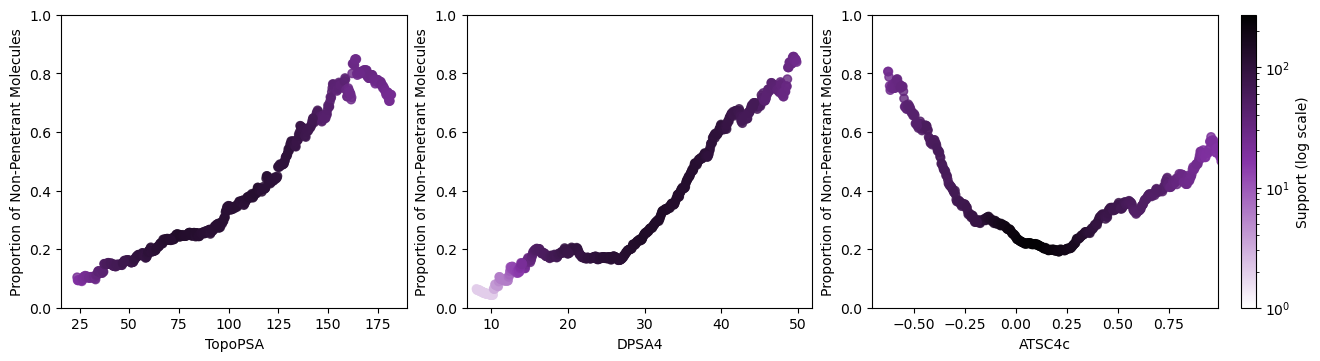

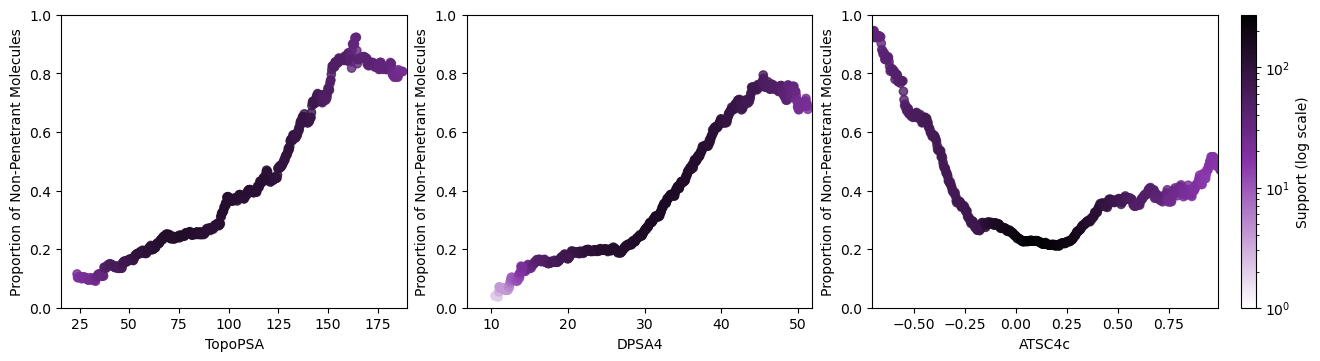

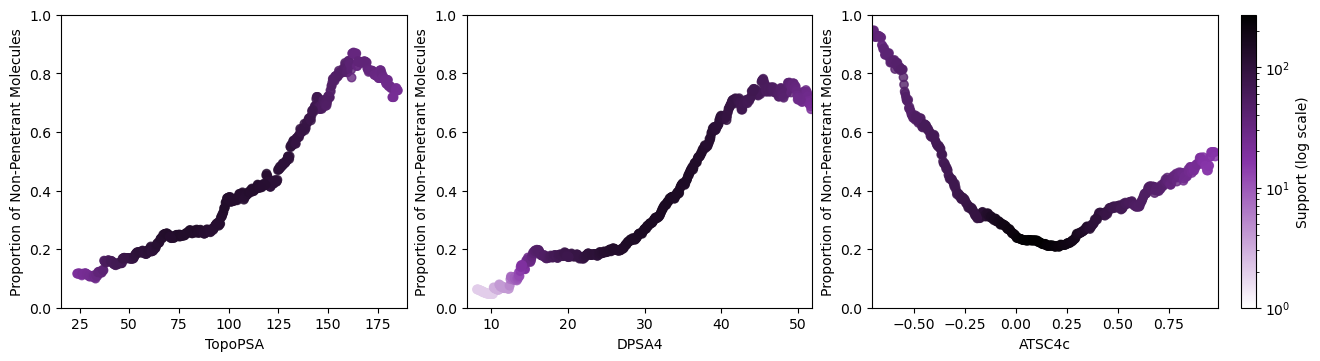

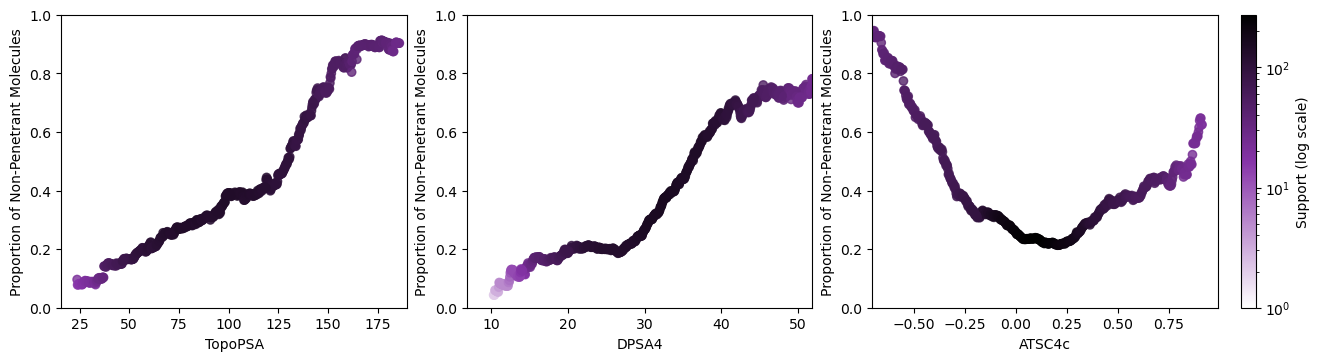

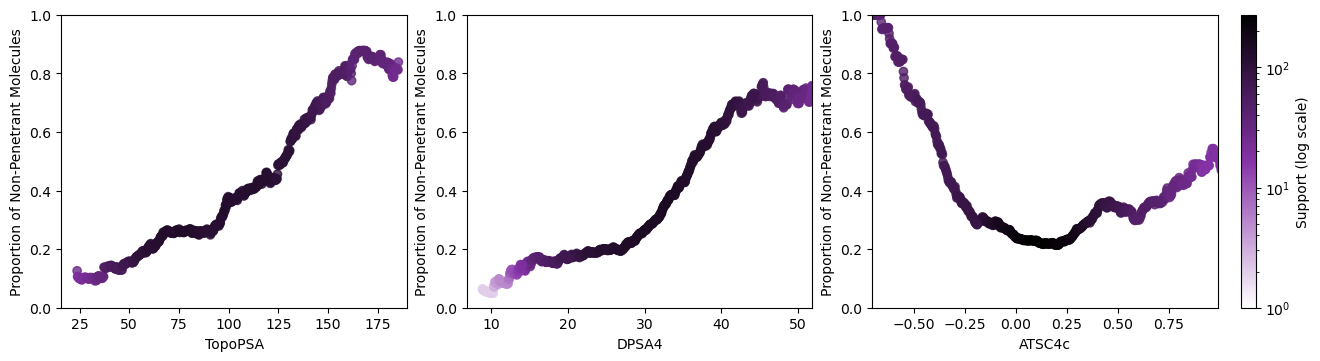

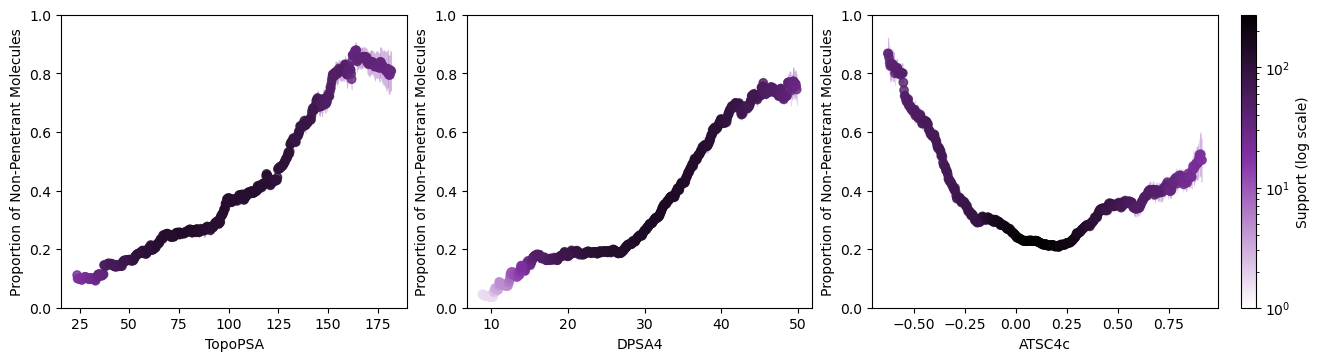

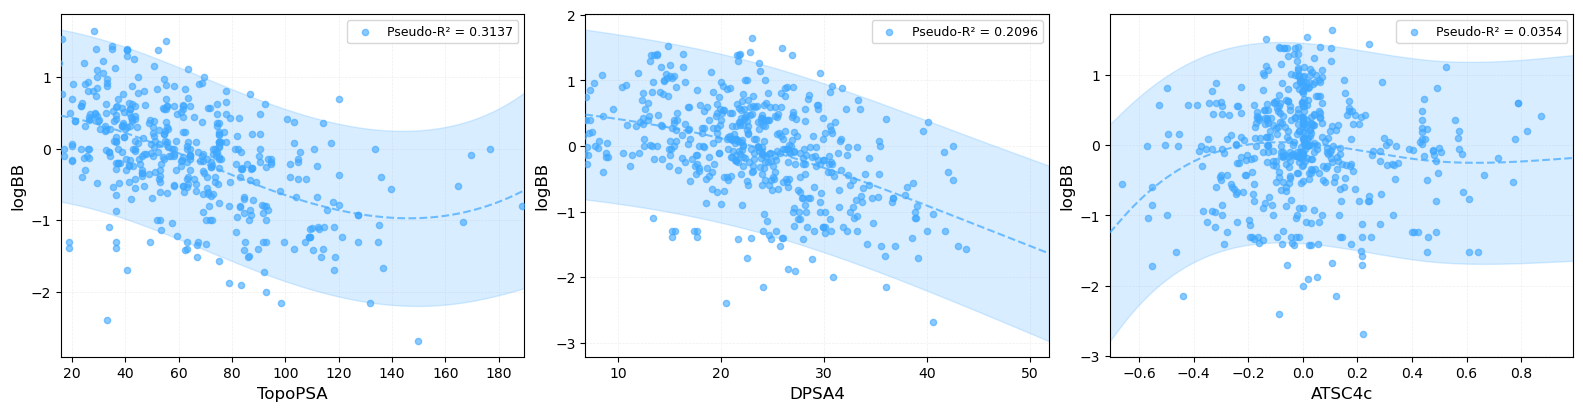

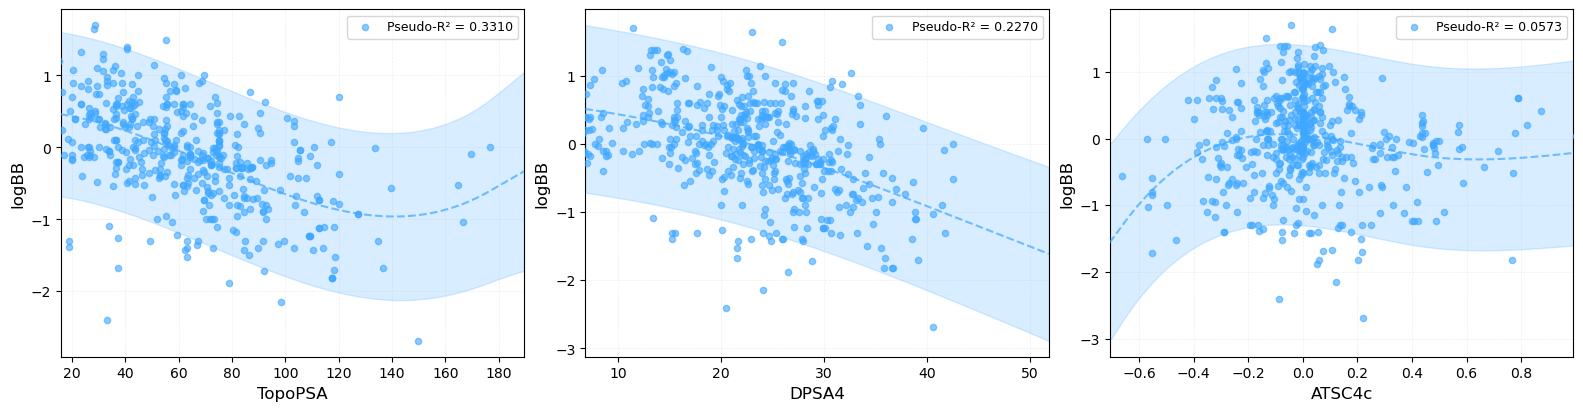

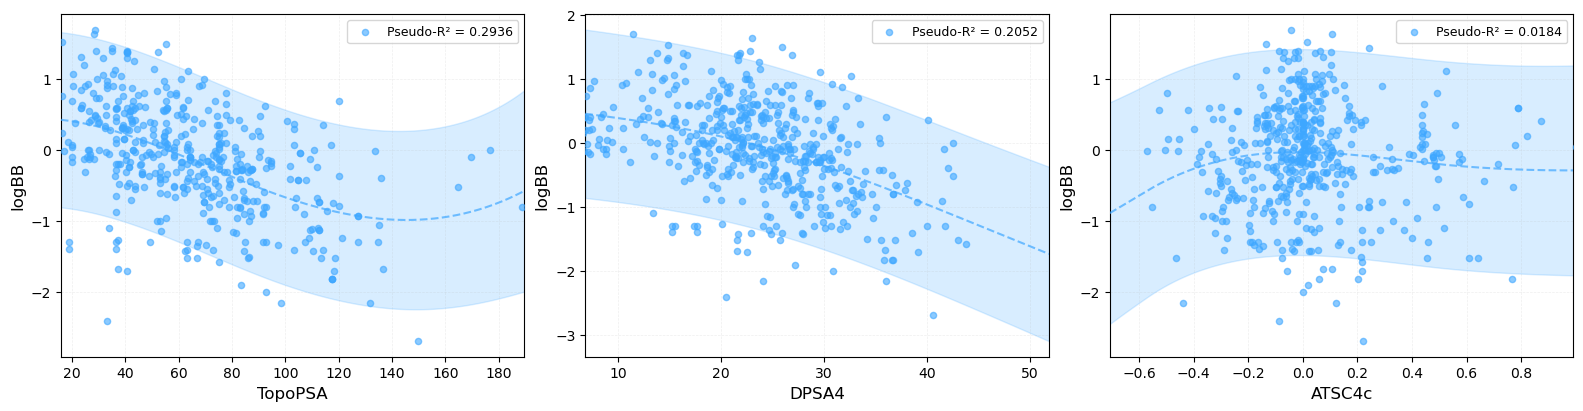

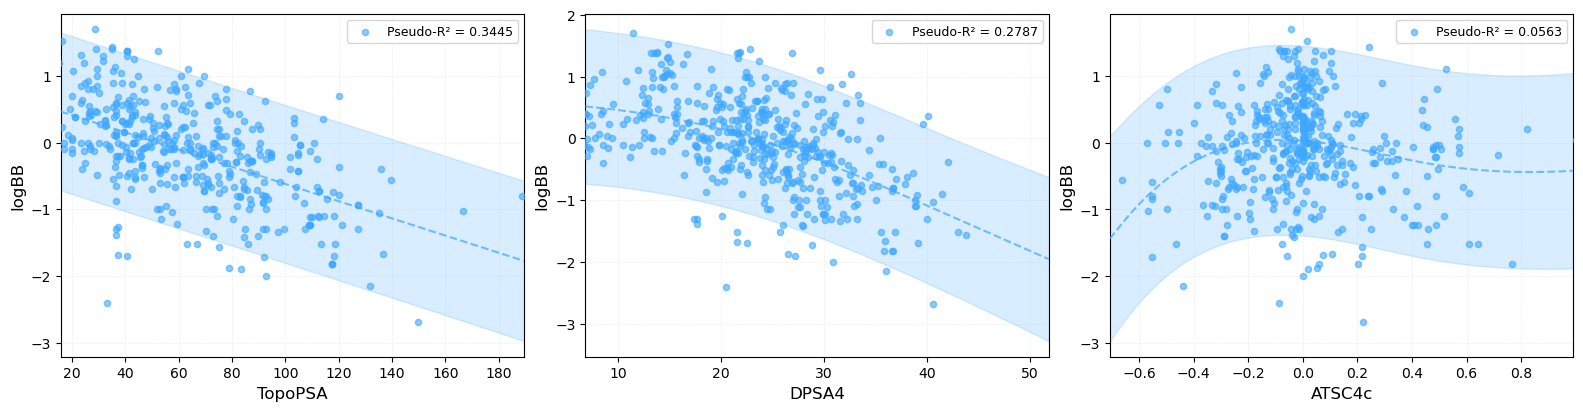

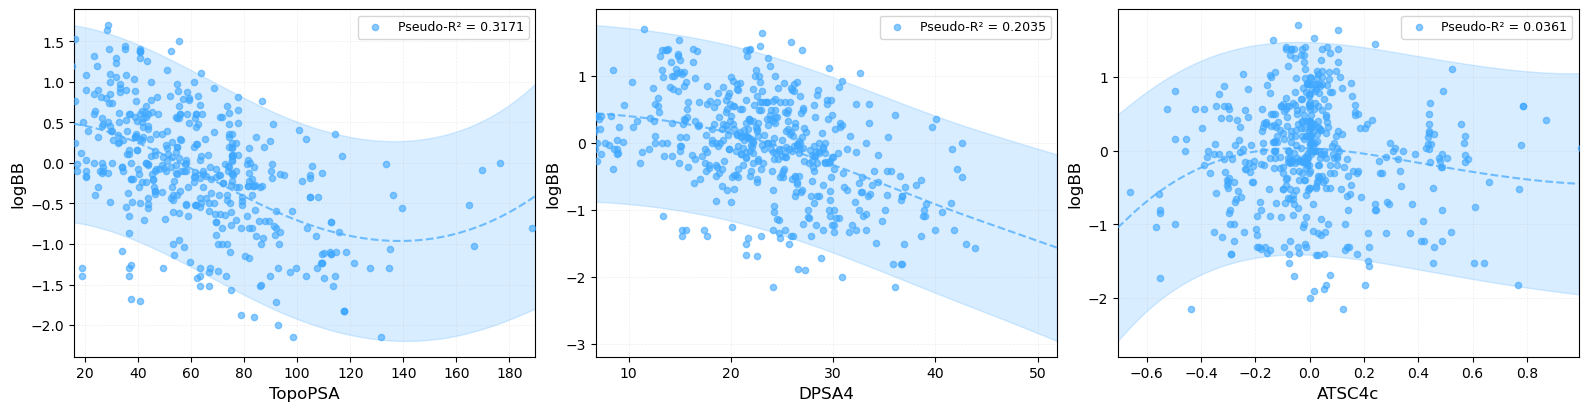

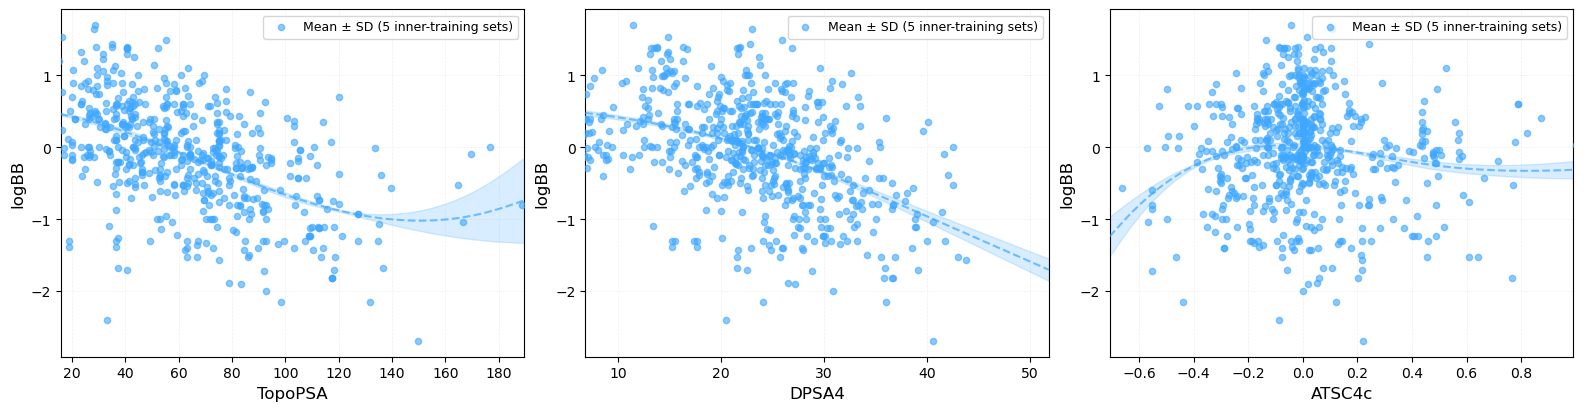

In [5]:
def finish(fig, path, dpi=LEGACY_DPI):
    # Save every format before closing; keep the original output stem/location.
    path = Path(path)
    save_formats(fig, path.with_suffix(''), dpi=dpi)
    plt.show()
    plt.close(fig)
    gc.collect()

def feature_ratios(df, feature, reference):
    x, y = values(df, feature), values(df, 'bbb_class')
    r = values(reference, feature)
    r = r[np.isfinite(r)]
    if not len(r) or np.ptp(r) == 0:
        raise ValueError(f'{feature}: missing/constant training values')
    rows = []
    for step in range(100):
        bins = np.arange(r.min() + np.ptp(r)*step/1000, r.max(), np.ptp(r)/10)
        bin_indices = np.digitize(x, bins, right=False)
        for i in range(1, len(bins)):
            mask = (bin_indices == i) & np.isfinite(x) & np.isin(y, [0,1])
            count, nonpen = mask.sum(), y[mask].sum()
            rows.append([
                step, i, bins[i], count, nonpen,
                y[mask].mean() if count > MIN_SUPPORT else np.nan
            ])
    return pd.DataFrame(
        rows, columns=['step','bin','x','support','nonpenetrant','proportion']
    )

fewer_features = list(fewer_features)
if not fewer_features or not inner_sets:
    raise ValueError('Select at least one feature and one inner-training subset')

ratios = {
    f: [feature_ratios(d, f, train) for d in inner_sets]
    for f in fewer_features
}

# Shared x-axis limits derived from supported points in mean panel 3c.
# These update automatically when this block is rerun.
feature_limits = {}
for f, tables in ratios.items():
    proportions = np.stack([t.proportion.to_numpy() for t in tables])
    supported_x = tables[0].x.to_numpy()[np.isfinite(proportions).all(axis=0)]

    if not len(supported_x):
        reference_x = values(train, f)
        supported_x = reference_x[np.isfinite(reference_x)]
        print(f'{f}: no windows supported in every inner set; using the training range.')

    lo, hi = supported_x.min(), supported_x.max()
    pad = .05 * (hi-lo if hi > lo else max(abs(lo), 1.0))
    feature_limits[f] = (lo-pad, hi+pad)

pd.DataFrame.from_dict(
    feature_limits, orient='index', columns=['xmin','xmax']
).rename_axis('feature').to_csv(out/'feature_plot_ranges.csv')

instances = np.concatenate([
    t.loc[t.proportion.notna(), 'nonpenetrant'].to_numpy()
    for tables in ratios.values() for t in tables
])
vmin = max(1, instances.min()) if len(instances) else 1
norm = LogNorm(
    vmin=vmin,
    vmax=max(vmin*1.01, instances.max() if len(instances) else 1)
)

for j, f in enumerate(fewer_features):
    pd.concat([
        t.assign(inner_set=k+1) for k, t in enumerate(ratios[f])
    ]).to_csv(out/f'feature_{j}_proportions.csv', index=False)

def plot_feature_panels(fold=None):
    n_rows = int(np.ceil(len(fewer_features)/n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4*n_cols, 3.5*n_rows),
        constrained_layout=True
    )
    axes = np.asarray(axes).reshape(-1)

    for j, (ax, f) in enumerate(zip(axes, fewer_features)):
        if fold is not None:
            t = ratios[f][fold]
            ax.scatter(
                t.x, t.proportion,
                color=custom_cmap(norm(t.nonpenetrant.clip(lower=1))),
                alpha=.8
            )
        else:
            y = np.stack([t.proportion.to_numpy() for t in ratios[f]])
            x = ratios[f][0].x.to_numpy()
            valid = np.isfinite(y).all(axis=0)
            mean = y[:,valid].mean(axis=0)
            sd = y[:,valid].std(axis=0, ddof=int(len(inner_sets)>1))
            support = np.stack([
                t.nonpenetrant.to_numpy() for t in ratios[f]
            ]).mean(axis=0)[valid]

            ax.errorbar(
                x[valid], mean, yerr=sd, fmt='none',
                ecolor=colors[3], alpha=.2, linewidth=.7, zorder=1
            )
            ax.scatter(
                x[valid], mean,
                color=custom_cmap(norm(np.maximum(support,1))),
                alpha=.8, zorder=2
            )
            pd.DataFrame({
                'x':x[valid], 'mean':mean, 'sd':sd,
                'mean_nonpenetrant':support
            }).to_csv(out/f'feature_{j}_proportion_mean_sd.csv', index=False)

        ax.set_xlabel(f)
        ax.set_ylabel('Proportion of Non-Penetrant Molecules')
        ax.set_xlim(feature_limits[f])
        ax.set_ylim((0,1))

    for ax in axes[len(fewer_features):]:
        fig.delaxes(ax)

    sm = cm.ScalarMappable(cmap=custom_cmap, norm=norm)
    sm.set_array([])
    fig.colorbar(
        sm, ax=list(axes[:len(fewer_features)]),
        location='right', pad=.02, fraction=.02
    ).set_label('Support (log scale)')

    finish(fig, out / ('classification_mean_sd.png' if fold is None else f'classification_inner_{fold+1}.png'))

for fold in range(len(inner_sets)): plot_feature_panels(fold)
plot_feature_panels()


def measured(df):
    mask = np.isfinite(values(df, 'logBB'))
    for col, expected in [
        ('logbb_is_measured',True),
        ('has_logbb',True),
        ('classification_only',False)
    ]:
        if col in df:
            flag = df[col].astype('string').str.lower().str.strip().map({
                'true':True, 'false':False, '1':True, '0':False,
                '1.0':True, '0.0':False
            })
            if flag.isna().any():
                raise ValueError(f'{col}: unknown/missing flag')
            mask &= flag.to_numpy(dtype=bool) == expected
    return mask

gams, grids = {}, {}
for j, f in enumerate(fewer_features):
    # Plot over the same range as panel 3c.
    grids[f] = np.linspace(*feature_limits[f], 500)[:,None]
    gams[f] = []

    # Fit on all available measured rows, independent of displayed limits.
    for d in inner_sets:
        x, y = values(d,f), values(d,'logBB')
        valid = np.isfinite(x) & measured(d)
        gams[f].append(
            LinearGAM(n_splines=5).gridsearch(
                x[valid,None], y[valid], progress=False
            )
        )

    fitted = np.stack([g.predict(grids[f]) for g in gams[f]])
    pd.DataFrame({
        'x':grids[f][:,0],
        'mean':fitted.mean(axis=0),
        'sd':fitted.std(axis=0, ddof=int(len(inner_sets)>1)),
        **{f'inner_{k+1}':p for k,p in enumerate(fitted)}
    }).to_csv(out/f'feature_{j}_gam_mean_sd.csv', index=False)

def plot_gam_panels(fold=None):
    n_rows = int(np.ceil(len(fewer_features)/n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(5*n_cols, 4*n_rows),
        constrained_layout=True
    )
    axes = np.asarray(axes).reshape(-1)

    for ax, f in zip(axes, fewer_features):
        XX = grids[f]
        d = train if fold is None else inner_sets[fold]
        x, y = values(d,f), values(d,'logBB')
        valid = np.isfinite(x) & measured(d)

        if fold is None:
            preds = np.stack([g.predict(XX) for g in gams[f]])
            mean = preds.mean(axis=0)
            sd = preds.std(axis=0, ddof=int(len(inner_sets)>1))
            low, high = mean-sd, mean+sd
            label = f'Mean ± SD ({len(inner_sets)} inner-training sets)'
        else:
            gam = gams[f][fold]
            mean = gam.predict(XX)
            low, high = gam.prediction_intervals(XX, width=.95).T
            label = f"Pseudo-R² = {gam.statistics_['pseudo_r2']['explained_deviance']:.4f}"

        ax.fill_between(
            XX[:,0], low, high, alpha=.2, color=colors[2], zorder=1
        )
        ax.plot(
            XX[:,0], mean, '--', color=colors[2], alpha=.7, zorder=4
        )
        ax.scatter(
            x[valid], y[valid], facecolor=colors[2],
            alpha=.6, s=20, label=label, zorder=3
        )
        ax.grid(True, linestyle='--', linewidth=.5, alpha=.2, zorder=0)
        ax.set_xlabel(f, fontsize=12)
        ax.set_ylabel('logBB', fontsize=12)
        ax.set_xlim(feature_limits[f])
        ax.legend(fontsize=9)
        ax.tick_params(axis='both', labelsize=10)

    for ax in axes[len(fewer_features):]:
        fig.delaxes(ax)

    finish(fig, out / ('gam_mean_sd.png' if fold is None else f'gam_inner_{fold+1}.png'))

for fold in range(len(inner_sets)):
    plot_gam_panels(fold)
plot_gam_panels()

In [6]:
# def finish(fig, path, dpi=1200):
#     fig.savefig(path, dpi=dpi, bbox_inches='tight')
#     plt.show()
#     plt.close(fig)

# def feature_ratios(df, feature, reference):
#     x, y = values(df, feature), values(df, 'bbb_class')
#     r = values(reference, feature)
#     r = r[np.isfinite(r)]
#     if not len(r) or np.ptp(r) == 0: raise ValueError(f'{feature}: missing/constant training values')
#     rows = []
#     for step in range(100):
#         bins = np.arange(r.min() + np.ptp(r)*step/1000, r.max(), np.ptp(r)/10)
#         bin_indices = np.digitize(x, bins, right=False)
#         for i in range(1, len(bins)):
#             mask = (bin_indices == i) & np.isfinite(x) & np.isin(y, [0,1])
#             count, nonpen = mask.sum(), y[mask].sum()
#             rows.append([step, i, bins[i], count, nonpen, y[mask].mean() if count > MIN_SUPPORT else np.nan])
#     return pd.DataFrame(rows, columns=['step','bin','x','support','nonpenetrant','proportion'])

# ratios = {f: [feature_ratios(d, f, train) for d in inner_sets] for f in fewer_features}
# instances = np.concatenate([t.loc[t.proportion.notna(), 'nonpenetrant'].to_numpy()
#                             for tables in ratios.values() for t in tables])
# vmin = max(1, instances.min()) if len(instances) else 1
# norm = LogNorm(vmin=vmin, vmax=max(vmin*1.01, instances.max() if len(instances) else 1))
# for j, f in enumerate(fewer_features):
#     pd.concat([t.assign(inner_set=k+1) for k,t in enumerate(ratios[f])]).to_csv(out/f'feature_{j}_proportions.csv', index=False)

# def plot_feature_panels(fold=None):
#     fig, axes = plt.subplots(int(np.ceil(len(fewer_features)/n_cols)), n_cols,
#                              figsize=(4*n_cols, 3.5*int(np.ceil(len(fewer_features)/n_cols))), constrained_layout=True)
#     axes = np.asarray(axes).reshape(-1)
#     for ax, f in zip(axes, fewer_features):
#         if fold is not None:
#             t = ratios[f][fold]
#             ax.scatter(t.x, t.proportion, color=custom_cmap(norm(t.nonpenetrant.clip(lower=1))), alpha=.8)
#         else:
#             y = np.stack([t.proportion.to_numpy() for t in ratios[f]])
#             x = ratios[f][0].x.to_numpy()
#             valid = np.isfinite(y).all(axis=0)
#             mean, sd = y[:,valid].mean(axis=0), y[:,valid].std(axis=0, ddof=1)
#             support = np.stack([t.nonpenetrant.to_numpy() for t in ratios[f]]).mean(axis=0)[valid]
#             ax.errorbar(x[valid], mean, yerr=sd, fmt='none', ecolor=colors[3], alpha=.2, linewidth=.7, zorder=1)
#             ax.scatter(x[valid], mean, color=custom_cmap(norm(np.maximum(support,1))), alpha=.8, zorder=2)
#             pd.DataFrame({'x':x[valid], 'mean':mean, 'sd':sd, 'mean_nonpenetrant':support}).to_csv(
#                 out/f'feature_{fewer_features.index(f)}_proportion_mean_sd.csv', index=False)
#         ax.set_xlabel(f)
#         ax.set_ylabel('Proportion of Non-Penetrant Molecules')
#         ax.set_ylim((0,1))
#     for ax in axes[len(fewer_features):]: fig.delaxes(ax)
#     sm = cm.ScalarMappable(cmap=custom_cmap, norm=norm)
#     sm.set_array([])
#     fig.colorbar(sm, ax=list(axes[:len(fewer_features)]), location='right', pad=.02, fraction=.02).set_label('Support (log scale)')
#     finish(fig, out / ('classification_mean_sd.png' if fold is None else f'classification_inner_{fold+1}.png'))
#     finish(fig, out / ('classification_mean_sd.svg' if fold is None else f'classification_inner_{fold+1}.svg'))

# # for fold in range(5): plot_feature_panels(fold)
# plot_feature_panels()

In [7]:
# # given rule: 

# def rule(df):
#     return values(df, 'WNSA4') < -8
#     # Multiple conditions:
#     # return (values(df, 'TopoPSA(NO)') > 110) & (values(df, 'PNSA4') < -12)

# rule_sets = [d.loc[rule(d)].copy() for d in inner_sets]
# print('Molecules satisfying rule per set:', [len(d) for d in rule_sets])

# ratios = {f: [feature_ratios(d, f, train) for d in rule_sets] for f in features}


# instances = np.concatenate([t.loc[t.proportion.notna(), 'nonpenetrant'].to_numpy()
#                             for tables in ratios.values() for t in tables])
# vmin = max(1, instances.min()) if len(instances) else 1
# norm = LogNorm(vmin=vmin, vmax=max(vmin*1.01, instances.max() if len(instances) else 1))
# for j, f in enumerate(features):
#     pd.concat([t.assign(inner_set=k+1) for k,t in enumerate(ratios[f])]).to_csv(out/f'feature_{j}_proportions.csv', index=False)

# plot_feature_panels()


## Original GAM panels + mean ± SD
Fit each GAM on its inner-training rows only. Individual panels retain the original 95% prediction interval and pseudo-R². The aggregate dashed curve is the pointwise mean of the five fitted curves; its shading is **±1 between-set SD**, replacing the prediction interval there. Blue points show the outer-training observations once. All five GAMs use the same x-grid; regions outside a particular inner set's observed range involve extrapolation.

Only finite measured logBB can enter a GAM. Explicit measurement flags, when present, are respected. Missing descriptor values are omitted only from the affected fit; no imputation.

In [8]:
# fewer_features = fewer_features[:2]

In [9]:
# The shared-range GAM fit/plot implementation above already saves the five individual
# fits and the mean ± SD panels as PNG, SVG and PDF. Do not refit here with different
# display ranges or overwrite feature_*_gam_mean_sd.csv with another grid.


## Review the selected rules
The default rules were selected from this outer fold's training-specific candidate list. Set `MANUAL_RULES` only for thresholds chosen from training plots before viewing the reserved test. The automatic all-fold analysis below always derives each fold's rules from its own training ranking.


In [10]:
# Keep the rules selected from this fold's training ranking by default.
MANUAL_RULES = None  # Optional list of (feature, operator, threshold), chosen before viewing outer-test results.
if MANUAL_RULES is not None: rules = list(MANUAL_RULES)


In [11]:
def rule_summary(df, by_count=False, chosen=None):
    selected = rules if chosen is None else chosen
    ops = {'>':operator.gt, '>=':operator.ge, '<':operator.lt, '<=':operator.le}
    x = np.column_stack([values(df,f) for f,_,_ in selected]) if selected else np.empty((len(df), 0))
    y = values(df,'bbb_class')
    valid = np.isfinite(x).all(axis=1) & np.isin(y,[0,1])
    hits = np.column_stack([ops[op](x[:,i],t) for i,(_,op,t) in enumerate(selected)]) if selected else np.empty((len(df), 0), dtype=bool)
    if by_count:
        groups, order = hits.sum(axis=1), list(range(len(selected)+1))
    else:
        if len(selected) != 2: raise ValueError('Combination plot requires two rules; use by_count=True')
        a, b = hits.T
        order = ['Neither', f'{selected[1][0]} only', f'{selected[0][0]} only', 'Both']
        groups = np.select([~a & ~b, ~a & b, a & ~b, a & b], order, default='Unknown')
    summary = pd.DataFrame({'group':groups[valid], 'bbb_class':y[valid]}).groupby('group').bbb_class.agg(
        nonpenetrant='sum', support='size', proportion_nonpenetrant='mean').reindex(order)
    summary[['support','nonpenetrant']] = summary[['support','nonpenetrant']].fillna(0)
    summary['penetrant'] = summary.support-summary.nonpenetrant
    summary['ci_low'], summary['ci_high'] = np.nan, np.nan
    ok = summary.support > 0
    low, high = proportion_confint(summary.loc[ok,'nonpenetrant'], summary.loc[ok,'support'], method='wilson')
    summary.loc[ok,'ci_low'], summary.loc[ok,'ci_high'] = low, high
    summary['error_low'] = summary.proportion_nonpenetrant-summary.ci_low
    summary['error_high'] = summary.ci_high-summary.proportion_nonpenetrant
    print(f'Rule-evaluable rows: {valid.sum()}/{len(df)}')
    return summary

# def plot_rules(summary, path, mean_sd=False, by_count=False):
#     norm = LogNorm(vmin=1, vmax=max(1.01, summary.support.max()))
#     x = np.arange(len(summary))
#     fig, ax = plt.subplots(figsize=(5.5,10) if by_count else (6,11))
#     ax.bar(x, summary.proportion_nonpenetrant, color=custom_cmap(norm(summary.support.clip(lower=1))), width=.75)
#     ax.errorbar(x, summary.proportion_nonpenetrant,
#                 yerr=np.maximum(0, np.vstack([summary.error_low,summary.error_high])), fmt='none',
#                 ecolor='black', elinewidth=1.5, capsize=3, capthick=1.5, zorder=3)
#     for i, (_,row) in enumerate(summary.iterrows()):
#         label = f'mean n = {row.support:.1f}' if mean_sd else f'n = {int(row.support)}'
#         ax.annotate(label, xy=(i,row.proportion_nonpenetrant+row.error_high if np.isfinite(row.proportion_nonpenetrant) else 0),
#                     xytext=(0,7), textcoords='offset points', ha='center', va='bottom', fontsize=9, annotation_clip=False)
#     ax.set_xticks(x)
#     ax.set_xticklabels(summary.index, rotation=0 if by_count else 25, ha='center' if by_count else 'right')
#     ax.set_ylim(0,1.2)
#     ax.set_xlabel('Number of rules satisfied' if by_count else 'Rule combination')
#     ax.set_ylabel('Observed proportion of non-penetrant compounds')
#     sm = cm.ScalarMappable(cmap=custom_cmap, norm=norm)
#     sm.set_array([])
#     fig.colorbar(sm, ax=ax).set_label('Mean support' if mean_sd else 'Support')
#     fig.tight_layout()
#     finish(fig,path,dpi=600)

def draw_rule_bars(ax, df, chosen, title):
    summary = rule_summary(df, by_count=True, chosen=chosen)
    x = np.arange(len(summary))
    norm = LogNorm(vmin=1, vmax=max(1.01, summary.support.max()))
    ax.bar(x, summary.proportion_nonpenetrant, color=custom_cmap(norm(summary.support.clip(lower=1))), width=.75)
    ax.errorbar(x, summary.proportion_nonpenetrant, yerr=np.maximum(0, [summary.error_low, summary.error_high]),
                fmt='none', ecolor='black', capsize=3, zorder=3)
    for i, row in enumerate(summary.itertuples()):
        height = row.ci_high if np.isfinite(row.ci_high) else 0
        ax.annotate(f'n = {int(row.support)}', (i, height), xytext=(0, 7), textcoords='offset points', ha='center')
    ax.set(xticks=x, xticklabels=summary.index, ylim=(0, 1.2), xlabel='Number of rules satisfied',
           ylabel='Observed proportion of non-penetrant compounds', title=title)
    sm = cm.ScalarMappable(cmap=custom_cmap, norm=norm)
    sm.set_array([])
    ax.figure.colorbar(sm, ax=ax).set_label('Support')

# for by_count in [False, True] if len(rules) == 2 else [True]:
#     name = 'rule_counts' if by_count else 'rule_combinations'
#     summaries = [rule_summary(d, by_count) for d in inner_sets]
#     for k, summary in enumerate(summaries,1):
#         summary.to_csv(out/f'{name}_inner_{k}.csv')
#         # plot_rules(summary, out/f'{name}_inner_{k}.png', by_count=by_count)
#     mean = summaries[0].copy()
#     p = np.stack([s.proportion_nonpenetrant.to_numpy() for s in summaries])
#     mean['proportion_nonpenetrant'] = p.mean(axis=0)
#     mean['error_low'] = mean['error_high'] = p.std(axis=0,ddof=1)
#     for col in ['support','nonpenetrant','penetrant']: mean[col] = np.stack([s[col] for s in summaries]).mean(axis=0)
#     mean = mean.drop(columns=['ci_low','ci_high'])
#     mean.to_csv(out/f'{name}_mean_sd.csv')
#     plot_rules(mean, out/f'{name}_mean_sd.png', mean_sd=True, by_count=by_count)

## Apply the frozen rules to the reserved outer fold
Run this cell only after defining the rules above. Same original bars, support colors, count labels and Wilson error bars. The five-set mean rule plot above instead uses between-set SD; groups empty in any set have undefined five-set means/SDs. No external dataset is loaded.

In [12]:
# for by_count in [False, True] if len(rules) == 2 else [True]:
#     name = 'rule_counts' if by_count else 'rule_combinations'
#     summary = rule_summary(test, by_count)
#     summary.to_csv(out/f'{name}_outer_test.csv')
#     plot_rules(summary, out/f'{name}_outer_test.png', by_count=by_count)

In [13]:
# from itertools import combinations
# from scipy.stats import fisher_exact
# from statsmodels.stats.multitest import multipletests

# # Derive each fold's rules with its own training ranking before evaluation.
# folds = sorted(full_df.outer_fold.unique(), key=str)
# rules_by_outer, training_records_by_outer = {}, {}
# for fold in folds:
#     fold_features = get_fold_features(fold)
#     training = full_df.loc[full_df.outer_fold != fold].copy()
#     rules_by_outer[fold], training_records_by_outer[fold] = select_rules(training, fold_features)
#     pd.DataFrame(training_records_by_outer[fold]).to_csv(
#         Path(f'./results/deriving_rules/outer_{fold}')/'selected_rules.csv', index=False)

# saved_rules, results = rules, []
# try:
#     for fold in folds:
#         rules = rules_by_outer[fold]
#         held_out = full_df.loc[full_df.outer_fold == fold]
#         for by_count in [False, True] if len(rules) == 2 else [True]:
#             name = 'rule_counts' if by_count else 'rule_combinations'
#             summary = rule_summary(held_out, by_count)
#             summary.to_csv(out/f'{name}_outer_{fold}.csv')
#             plot_rules(summary, out/f'{name}_outer_{fold}.png', by_count=by_count)

#             for a, b in combinations(summary.index, 2):
#                 ra, rb = summary.loc[a], summary.loc[b]
#                 table = summary.loc[[a, b], ['nonpenetrant', 'penetrant']].to_numpy(dtype=int)
#                 odds, p = fisher_exact(table, alternative='two-sided') if (table.sum(axis=1) > 0).all() else (np.nan, np.nan)
#                 results.append({
#                     'outer_fold': fold, 'analysis': name, 'rules': repr(rules),
#                     'group_a': a, 'group_b': b,
#                     'n_a': int(ra.support), 'n_b': int(rb.support),
#                     'proportion_a': ra.proportion_nonpenetrant,
#                     'proportion_b': rb.proportion_nonpenetrant,
#                     'difference_a_minus_b': ra.proportion_nonpenetrant - rb.proportion_nonpenetrant,
#                     'odds_ratio_a_vs_b': odds, 'p_value': p,
#                 })
# finally:
#     rules = saved_rules

# significance = pd.DataFrame(results, columns=['outer_fold', 'analysis', 'rules', 'group_a', 'group_b', 'n_a', 'n_b', 'proportion_a', 'proportion_b', 'difference_a_minus_b', 'odds_ratio_a_vs_b', 'p_value'])
# significance['p_holm'] = np.nan
# for name in significance.analysis.unique():
#     mask = significance.analysis.eq(name) & significance.p_value.notna()
#     if mask.any():
#         significance.loc[mask, 'p_holm'] = multipletests(
#             significance.loc[mask, 'p_value'], method='holm'
#         )[1]
# significance['significant_holm'] = significance.p_holm.lt(.05)
# significance.to_csv(out/'rule_significance_all_outerfolds.csv', index=False)
# display(significance)

In [14]:
# from itertools import combinations
# from scipy.stats import fisher_exact
# from statsmodels.stats.multitest import multipletests

# EXTERNAL_PATH = '../datasets/inxight_labelled_unbalanced.csv'
# external = pd.read_csv(EXTERNAL_PATH, low_memory=False)
# external['bbb_class'] = pd.to_numeric(external['bbb_class'], errors='raise')
# if not external.bbb_class.isin([0, 1]).all():
#     raise ValueError('bbb_class must be 0 = penetrant, 1 = non-penetrant')

# missing = [f for f, _, _ in rules if f not in external.columns]
# if missing: raise KeyError(f'External dataset is missing descriptors: {missing}')

# results = []
# for by_count in [False, True] if len(rules) == 2 else [True]:
#     name = 'rule_counts' if by_count else 'rule_combinations'
#     summary = rule_summary(external, by_count)
#     summary.to_csv(out/f'{name}_inxight.csv')
#     plot_rules(summary, out/f'{name}_inxight.png', by_count=by_count)

#     for a, b in combinations(summary.index, 2):
#         ra, rb = summary.loc[a], summary.loc[b]
#         table = summary.loc[[a, b], ['nonpenetrant', 'penetrant']].to_numpy(dtype=int)
#         odds, p = (
#             fisher_exact(table, alternative='two-sided')
#             if (table.sum(axis=1) > 0).all() else (np.nan, np.nan)
#         )
#         results.append({
#             'analysis': name, 'rules': repr(rules),
#             'group_a': a, 'group_b': b,
#             'n_a': int(ra.support), 'n_b': int(rb.support),
#             'proportion_a': ra.proportion_nonpenetrant,
#             'proportion_b': rb.proportion_nonpenetrant,
#             'difference_a_minus_b': ra.proportion_nonpenetrant - rb.proportion_nonpenetrant,
#             'odds_ratio_a_vs_b': odds, 'p_value': p,
#         })

# significance = pd.DataFrame(results, columns=['analysis', 'rules', 'group_a', 'group_b', 'n_a', 'n_b', 'proportion_a', 'proportion_b', 'difference_a_minus_b', 'odds_ratio_a_vs_b', 'p_value'])
# significance['p_holm'] = np.nan
# for name in significance.analysis.unique():
#     mask = significance.analysis.eq(name) & significance.p_value.notna()
#     if mask.any():
#         significance.loc[mask, 'p_holm'] = multipletests(
#             significance.loc[mask, 'p_value'], method='holm'
#         )[1]
# significance['significant_holm'] = significance.p_holm.lt(.05)
# significance.to_csv(out/'rule_significance_inxight.csv', index=False)
# display(significance)

In [15]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

MIN_PROPORTION = .7
STEP_TARGETS = {}                  # e.g. {2: .80}
MIN_STANDALONE = .7
MIN_RULE_SUPPORT = 30
MIN_GAIN = 0.0
MIN_RETAINED = 0.0
MAX_RULES = 5
MIN_FOLD_AGREEMENT = 4             # same feature + direction in at least 4 folds
EXTERNAL_PATH = '../datasets/inxight_labelled_unbalanced.csv'

def evaluate_rules(df, chosen):
    # Use the same evaluable rows for all steps; missing descriptors are not rule failures.
    y = values(df, 'bbb_class')
    valid = np.isin(y, [0, 1])
    for f, _, _ in chosen: valid &= np.isfinite(values(df, f))
    d, y = df.loc[valid], y[valid]
    cumulative, rows = np.ones(len(d), dtype=bool), []
    for step, rule in enumerate(chosen, 1):
        alone = satisfies(d, *rule)
        cumulative &= alone
        n, other_n = cumulative.sum(), (~cumulative).sum()
        pos, other_pos = y[cumulative].sum(), y[~cumulative].sum()
        odds, p = (
            fisher_exact([[pos, n-pos], [other_pos, other_n-other_pos]])
            if n and other_n else (np.nan, np.nan)
        )
        rows.append({
            'step': step, 'feature': rule[0], 'direction': rule[1],
            'threshold': rule[2], 'n_evaluable': len(d), 'n_total': len(df),
            'baseline_proportion': y.mean() if len(y) else np.nan,
            'support': int(n), 'proportion': pos/n if n else np.nan,
            'coverage': n/len(d) if len(d) else np.nan,
            'standalone_support': int(alone.sum()),
            'standalone_proportion': y[alone].mean() if alone.any() else np.nan,
            'remaining_proportion': other_pos/other_n if other_n else np.nan,
            'odds_ratio': odds, 'p_value': p,
        })
    return rows

def add_holm(table):
    table['p_holm'] = np.nan
    if 'p_value' in table:
        valid = table.p_value.notna()
        if valid.any():
            table.loc[valid, 'p_holm'] = multipletests(
                table.loc[valid, 'p_value'], method='holm'
            )[1]
    return table

data = full_df.copy()
data['bbb_class'] = pd.to_numeric(data.bbb_class, errors='raise')
if not data.bbb_class.isin([0, 1]).all() or data.outer_fold.isna().any():
    raise ValueError('Need valid 0/1 classes and nonmissing outer folds')

folds = sorted(data.outer_fold.unique(), key=str)
if not 1 <= MIN_FOLD_AGREEMENT <= len(folds):
    raise ValueError('MIN_FOLD_AGREEMENT must be between 1 and the number of folds')

rules_by_outer, discovery, heldout_results = {}, [], []
for fold in folds:
    training = data.loc[data.outer_fold != fold].copy()
    testing = data.loc[data.outer_fold == fold].copy()
    fold_features = get_fold_features(fold)
    chosen, records = select_rules(training, fold_features)
    rules_by_outer[fold] = chosen
    discovery.extend({'outer_fold': fold, **r} for r in records)
    heldout_results.extend(
        {'outer_fold': fold, **r} for r in evaluate_rules(testing, chosen)
    )
    print(f'Outer fold {fold}: {chosen}')

discovery = pd.DataFrame(discovery)
outer_results = pd.DataFrame(heldout_results)
display(outer_results)
discovery.to_csv(out/'rules_selected_per_outerfold.csv', index=False)
outer_results.to_csv(out/'rules_outerfold_evaluation.csv', index=False)

# Consensus uses training-selected feature/direction agreement only.
records = [{'outer_fold': fold, 'feature': f, 'direction': direction, 'threshold': threshold}
           for fold, chosen in rules_by_outer.items() for f, direction, threshold in chosen]
if records:
    stability = pd.DataFrame(records)
    consensus = stability.groupby(['feature', 'direction'], as_index=False).agg(
        folds_selected=('outer_fold', 'nunique'), threshold=('threshold', 'median'),
        threshold_min=('threshold', 'min'), threshold_max=('threshold', 'max'))
    consensus = consensus.loc[consensus.folds_selected.ge(MIN_FOLD_AGREEMENT)].sort_values(
        ['folds_selected', 'feature', 'direction'], ascending=[False, True, True])
    consensus_rules = list(consensus[['feature', 'direction', 'threshold']].itertuples(index=False, name=None))
    stability.to_csv(out/'rule_selection_per_outerfold.csv', index=False)
else:
    consensus, consensus_rules = pd.DataFrame(), []

consensus.to_csv(out/'consensus_rules.csv', index=False)
display(consensus)
print('Consensus rules:', consensus_rules)
# Evaluate the frozen consensus on Inxight.
external = None
if consensus_rules and Path(EXTERNAL_PATH).is_file():
    external = pd.read_csv(EXTERNAL_PATH, low_memory=False)
    external['bbb_class'] = pd.to_numeric(external.bbb_class, errors='raise')
    if not external.bbb_class.isin([0, 1]).all():
        raise ValueError('External bbb_class must be 0/1')
    external_results = add_holm(pd.DataFrame(evaluate_rules(external, consensus_rules)))
    external_results.to_csv(out/'consensus_rules_inxight.csv', index=False)
    display(external_results)
else:
    print('External plots unavailable:', 'no consensus rules' if not consensus_rules else f'missing EXTERNAL_PATH: {EXTERNAL_PATH}')

Outer fold 0: [('ATSC4c', '<=', -0.4376826269636784), ('FNSA2', '<=', -1.2833823972898453), ('nHetero', '>', 9.0)]
Outer fold 1: 100 candidate features from its own training ranking
Outer fold 1: [('nAcid', '>', 0.0), ('DPSA4', '>', 33.966299404426955), ('DPSA3', '>', 78.93265088129377)]
Outer fold 2: 100 candidate features from its own training ranking
Outer fold 2: [('TopoPSA', '>', 106.97000000000004), ('WNSA4', '<=', -9.508718446057587), ('nAcid', '>', 0.0), ('DPSA4', '>', 41.56544031603488)]
Outer fold 3: 100 candidate features from its own training ranking
Outer fold 3: [('nAcid', '>', 0.0), ('DPSA4', '>', 41.56544031603488)]
Outer fold 4: 100 candidate features from its own training ranking
Outer fold 4: [('TopoPSA', '>', 108.56), ('DPSA4', '>', 35.68769108812768), ('WNSA4', '<=', -10.836259535378174), ('nAcid', '>', 0.0), ('DPSA3', '>', 95.85749714424745)]


,outer_fold,step,feature,direction,threshold,n_evaluable,n_total,baseline_proportion,support,proportion,coverage,standalone_support,standalone_proportion,remaining_proportion,odds_ratio,p_value
0,0,1,ATSC4c,<=,-0.437683,626,626,0.354633,48,0.791667,0.076677,48,0.791667,0.318339,8.136957,1.425390e-10
1,0,2,FNSA2,<=,-1.283382,626,626,0.354633,17,0.941176,0.027157,49,0.775510,0.338259,31.300971,5.062026e-07
2,0,3,nHetero,>,9.000000,626,626,0.354633,13,0.923077,0.020767,57,0.807018,0.342577,23.028571,2.891976e-05
3,1,1,nAcid,>,0.000000,654,654,0.266055,74,0.567568,0.113150,74,0.567568,0.227586,4.454545,5.390716e-09
4,1,2,DPSA4,>,33.966299,654,654,0.266055,22,0.772727,0.033639,87,0.655172,0.248418,10.286624,6.447064e-07
5,1,3,DPSA3,>,78.932651,654,654,0.266055,15,0.733333,0.022936,62,0.596774,0.255086,8.030675,1.768606e-04
6,2,1,TopoPSA,>,106.970000,616,616,0.300325,81,0.592593,0.131494,81,0.592593,0.256075,4.225614,6.786473e-09
7,2,2,WNSA4,<=,-9.508718,616,616,0.300325,37,0.729730,0.060065,53,0.698113,0.272884,7.194304,3.265204e-08
8,2,3,nAcid,>,0.000000,616,616,0.300325,16,1.000000,0.025974,72,0.750000,0.281667,inf,2.734381e-09
9,2,4,DPSA4,>,41.565440,616,616,0.300325,11,1.000000,0.017857,28,0.678571,0.287603,inf,1.448341e-06


,feature,direction,folds_selected,threshold,threshold_min,threshold_max
2,DPSA4,>,4,38.626566,33.966299,41.56544
6,nAcid,>,4,0.000000,0.000000,0.00000


Consensus rules: [('DPSA4', '>', 38.62656570208128), ('nAcid', '>', 0.0)]


,step,feature,direction,threshold,n_evaluable,n_total,baseline_proportion,support,proportion,coverage,standalone_support,standalone_proportion,remaining_proportion,odds_ratio,p_value,p_holm
0,1,DPSA4,>,38.626566,604,604,0.254967,81,0.382716,0.134106,81,0.382716,0.235182,2.016260,0.006088,0.006088
1,2,nAcid,>,0.000000,604,604,0.254967,17,0.647059,0.028146,112,0.303571,0.243612,5.692308,0.000624,0.001248


In [16]:
# # Five figures: corresponding training data and outer test, using the same rules.
# for fold in sorted(data.outer_fold.unique(), key=str):
#     chosen = rules_by_outer[fold]
#     fig, axes = plt.subplots(1, 2, figsize=(12, 11), constrained_layout=True)

#     for ax, df, title in [
#         (axes[0], data.loc[data.outer_fold != fold], 'Training'),
#         (axes[1], data.loc[data.outer_fold == fold], 'Outer test'),
#     ]:
#         draw_rule_bars(ax, df, chosen, title)

#     rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in chosen)
#     fig.suptitle(f'Outer fold {fold}\n{rule_text}', fontsize=12)
#     finish(fig, out/f'training_vs_outer_test_{fold}.png')

# # One figure: consensus rules on full dataset and Inxight.
# external = pd.read_csv(EXTERNAL_PATH, low_memory=False)
# fig, axes = plt.subplots(1, 2, figsize=(12, 11), constrained_layout=True)

# draw_rule_bars(axes[0], data, consensus_rules, 'Full dataset')
# draw_rule_bars(axes[1], external, consensus_rules, 'Inxight')

# rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in consensus_rules)
# fig.suptitle(f'Consensus rules\n{rule_text}', fontsize=12)
# finish(fig, out/'consensus_full_vs_inxight.png')

In [17]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

ALPHA = .05

records = []
for fold, chosen in rules_by_outer.items():
    df = data.loc[data.outer_fold == fold]
    for f, direction, threshold in chosen:
        x, y = values(df, f), values(df, 'bbb_class')
        valid = np.isfinite(x) & np.isin(y, [0, 1])
        hit = satisfies(df, f, direction, threshold)[valid]
        y = y[valid]

        n, m = int(hit.sum()), int((~hit).sum())
        a, b = int(y[hit].sum()), int(y[~hit].sum())
        odds, p = (
            fisher_exact([[a, n-a], [b, m-b]], alternative='two-sided')
            if n and m else (np.nan, np.nan)
        )
        records.append({
            'outer_fold': fold, 'feature': f, 'direction': direction,
            'threshold': threshold, 'support': n,
            'proportion': a/n if n else np.nan,
            'remaining_proportion': b/m if m else np.nan,
            'odds_ratio': odds, 'p_value': p,
        })

rule_tests = pd.DataFrame(records, columns=['outer_fold', 'feature', 'direction', 'threshold', 'support',
    'proportion', 'remaining_proportion', 'odds_ratio', 'p_value'])
rule_tests['p_holm'] = np.nan
valid = rule_tests.p_value.notna()
if valid.any(): rule_tests.loc[valid, 'p_holm'] = multipletests(rule_tests.loc[valid, 'p_value'], method='holm')[1]
rule_tests['significant_enrichment'] = rule_tests.p_holm.lt(ALPHA) & rule_tests.proportion.gt(rule_tests.remaining_proportion)
rule_tests.to_csv(out/'rule_significance_per_outerfold.csv', index=False)
display(rule_tests)
# Keep the training-defined consensus from the previous cell unchanged.
print('Frozen consensus rules:', consensus_rules)


,outer_fold,feature,direction,threshold,support,proportion,remaining_proportion,odds_ratio,p_value,p_holm,significant_enrichment
0,0,ATSC4c,<=,-0.437683,48,0.791667,0.318339,8.136957,1.425390e-10,1.425390e-09,True
1,0,FNSA2,<=,-1.283382,49,0.775510,0.318891,7.378458,5.973703e-10,4.778962e-09,True
2,0,nHetero,>,9.000000,57,0.807018,0.309315,9.337810,2.595536e-13,3.374197e-12,True
3,1,nAcid,>,0.000000,74,0.567568,0.227586,4.454545,5.390716e-09,3.773501e-08,True
4,1,DPSA4,>,33.966299,87,0.655172,0.206349,7.307692,1.758805e-16,2.638207e-15,True
5,1,DPSA3,>,78.932651,62,0.596774,0.231419,4.915328,8.692275e-09,4.346138e-08,True
6,2,TopoPSA,>,106.970000,81,0.592593,0.256075,4.225614,6.786473e-09,4.071884e-08,True
7,2,WNSA4,<=,-9.508718,53,0.698113,0.262877,6.484375,4.267755e-10,3.840980e-09,True
8,2,nAcid,>,0.000000,72,0.750000,0.240809,9.458015,4.386762e-17,7.018819e-16,True
9,2,DPSA4,>,41.565440,28,0.678571,0.282313,5.366801,2.615584e-05,5.231167e-05,True


Frozen consensus rules: [('DPSA4', '>', 38.62656570208128), ('nAcid', '>', 0.0)]


In [18]:
# # Five figures: corresponding training data and outer test, using the same rules.
# for fold in sorted(data.outer_fold.unique(), key=str):
#     chosen = rules_by_outer[fold]
#     fig, axes = plt.subplots(1, 2, figsize=(12, 11), constrained_layout=True)

#     for ax, df, title in [
#         (axes[0], data.loc[data.outer_fold != fold], 'Training'),
#         (axes[1], data.loc[data.outer_fold == fold], 'Outer test'),
#     ]:
#         draw_rule_bars(ax, df, chosen, title)

#     rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in chosen)
#     fig.suptitle(f'Outer fold {fold}\n{rule_text}', fontsize=12)
#     finish(fig, out/f'training_vs_outer_test_{fold}.png')

# # One figure: consensus rules on full dataset and Inxight.
# external = pd.read_csv(EXTERNAL_PATH, low_memory=False)
# fig, axes = plt.subplots(1, 2, figsize=(12, 11), constrained_layout=True)

# draw_rule_bars(axes[0], data, consensus_rules, 'Full dataset')
# draw_rule_bars(axes[1], external, consensus_rules, 'Inxight')

# rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in consensus_rules)
# fig.suptitle(f'Consensus rules\n{rule_text}', fontsize=12)
# finish(fig, out/'consensus_full_vs_inxight.png')

In [19]:
# from scipy.stats import fisher_exact
# from statsmodels.stats.multitest import multipletests

def external_rule_tests(df, chosen):
    rows = []
    for f, op, threshold in chosen:
        x, y = values(df, f), values(df, 'bbb_class')
        valid = np.isfinite(x) & np.isin(y, [0, 1])
        hit, y = satisfies(df, f, op, threshold)[valid], y[valid]
        n, m = int(hit.sum()), int((~hit).sum())
        a, b = int(y[hit].sum()), int(y[~hit].sum())
        p = fisher_exact([[a, n-a], [b, m-b]])[1] if n and m else np.nan
        rows.append({'feature': f, 'direction': op, 'threshold': threshold, 'p_value': p})

    tests = pd.DataFrame(rows)
    tests['p_holm'] = np.nan
    if len(tests):
        valid = tests.p_value.notna()
        if valid.any():
            tests.loc[valid, 'p_holm'] = multipletests(
                tests.loc[valid, 'p_value'], method='holm'
            )[1]
    return tests

SIGNIFICANCE_LEGEND = 'Significance annotations (Holm-adjusted p):  ns: p > 0.05;  *: p ≤ 0.05;  **: p ≤ 0.01;  ***: p ≤ 0.001;  ****: p ≤ 0.0001'

def significance_label(p):
    if not np.isfinite(p): return 'not estimable'
    return next((label for threshold, label in [(1e-4, '****'), (1e-3, '***'), (.01, '**'), (.05, '*')] if p <= threshold), 'ns')

def add_significance_legend(fig):
    fig.supxlabel(SIGNIFICANCE_LEGEND, fontsize=9)

def annotate_pvalues(ax, tests):
    if tests.empty: return
    lines = ['Standalone rule vs rest — Holm-adjusted significance']
    for r in tests.itertuples():
        label = significance_label(r.p_holm)
        lines.append(f'{r.feature} {r.direction} {r.threshold:.4g}: {label}')
    ax.set_title(ax.get_title() + '\n' + '\n'.join(lines), fontsize=10)
    add_significance_legend(ax.figure)

# # Five figures: training and corresponding outer test.
# for fold in sorted(data.outer_fold.unique(), key=str):
#     chosen = rules_by_outer[fold]
#     fig, axes = plt.subplots(1, 2, figsize=(12, 11), constrained_layout=True)

#     draw_rule_bars(axes[0], data.loc[data.outer_fold != fold], chosen, 'Training')
#     draw_rule_bars(axes[1], data.loc[data.outer_fold == fold], chosen, 'Outer test')
#     if chosen:
#         # Reuse the exact globally Holm-adjusted outer-test reporting p-values.
#         annotate_pvalues(axes[1], rule_tests.loc[rule_tests.outer_fold.eq(fold)])

#     rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in chosen)
#     fig.suptitle(f'Outer fold {fold}\n{rule_text}', fontsize=12)
#     finish(fig, out/f'training_vs_outer_test_{fold}.png')

# # One figure: full dataset and Inxight, using consensus rules.
# external = pd.read_csv(EXTERNAL_PATH, low_memory=False)
# fig, axes = plt.subplots(1, 2, figsize=(12, 11), constrained_layout=True)

# draw_rule_bars(axes[0], data, consensus_rules, 'Full dataset')
# draw_rule_bars(axes[1], external, consensus_rules, 'Inxight')
# if consensus_rules:
#     inxight_tests = external_rule_tests(external, consensus_rules)
#     annotate_pvalues(axes[1], inxight_tests)
#     inxight_tests.to_csv(out/'consensus_standalone_inxight_tests.csv', index=False)

# rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in consensus_rules)
# fig.suptitle(f'Consensus rules\n{rule_text}', fontsize=12)
# finish(fig, out/'consensus_full_vs_inxight.png')

## Rule-count comparisons
Pairwise two-sided Fisher tests compare nonpenetrant fractions between disjoint rule-count groups. Holm correction covers all such outer-test comparisons together, with a separate family for Inxight. Brackets show these count-group comparisons; title annotations retain the existing standalone-rule tests. Rules and rankings stay frozen.


Rule-evaluable rows: 626/626
Rule-evaluable rows: 654/654
Rule-evaluable rows: 616/616
Rule-evaluable rows: 640/640
Rule-evaluable rows: 652/652
Rule-evaluable rows: 2562/2562
Rule-evaluable rows: 626/626


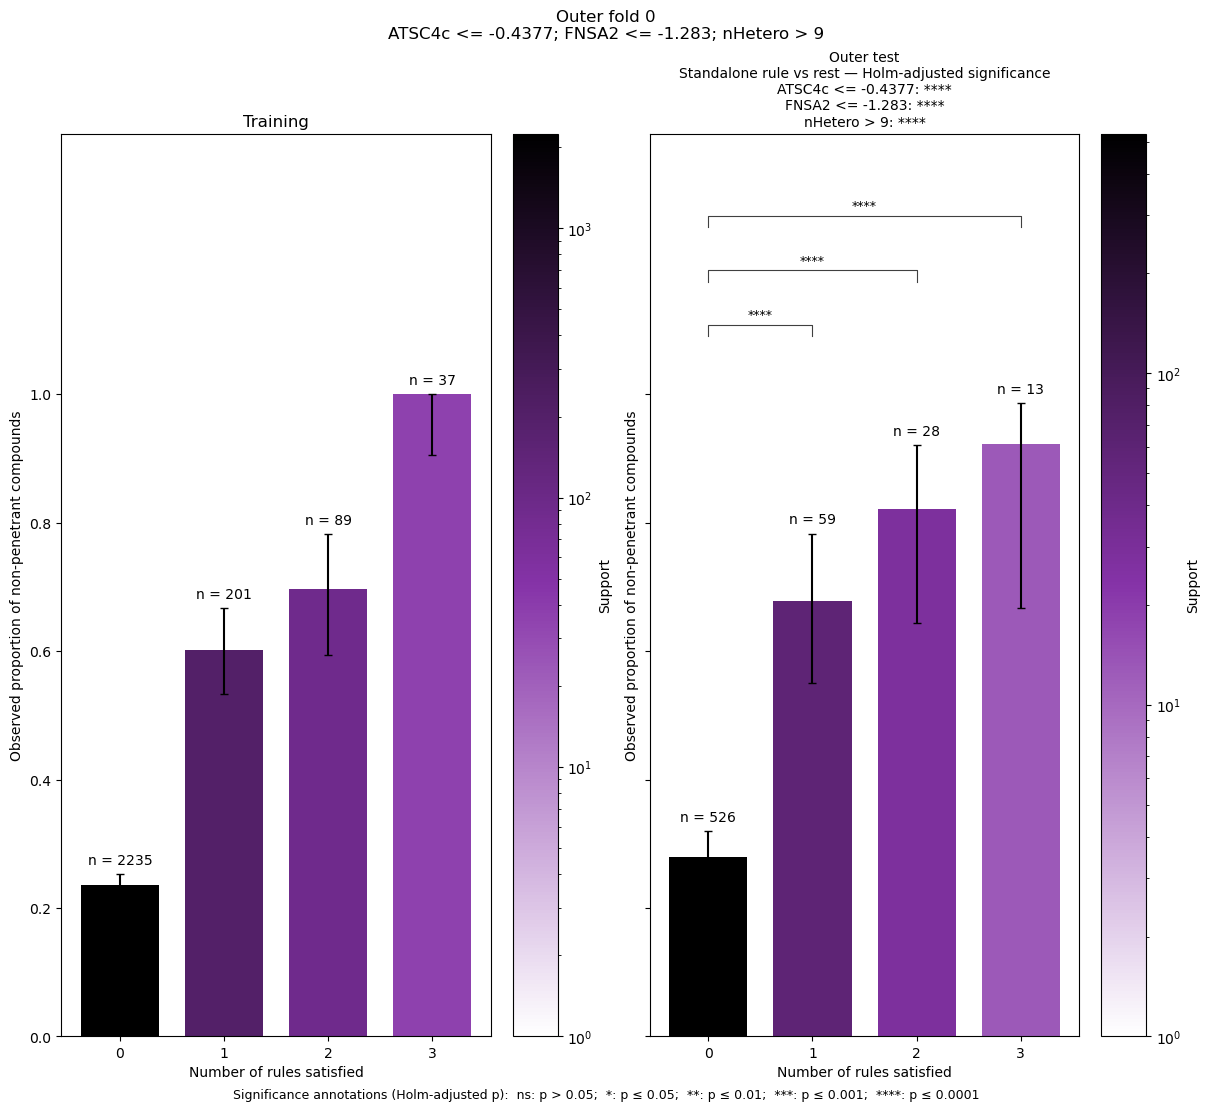

Rule-evaluable rows: 2534/2534
Rule-evaluable rows: 654/654


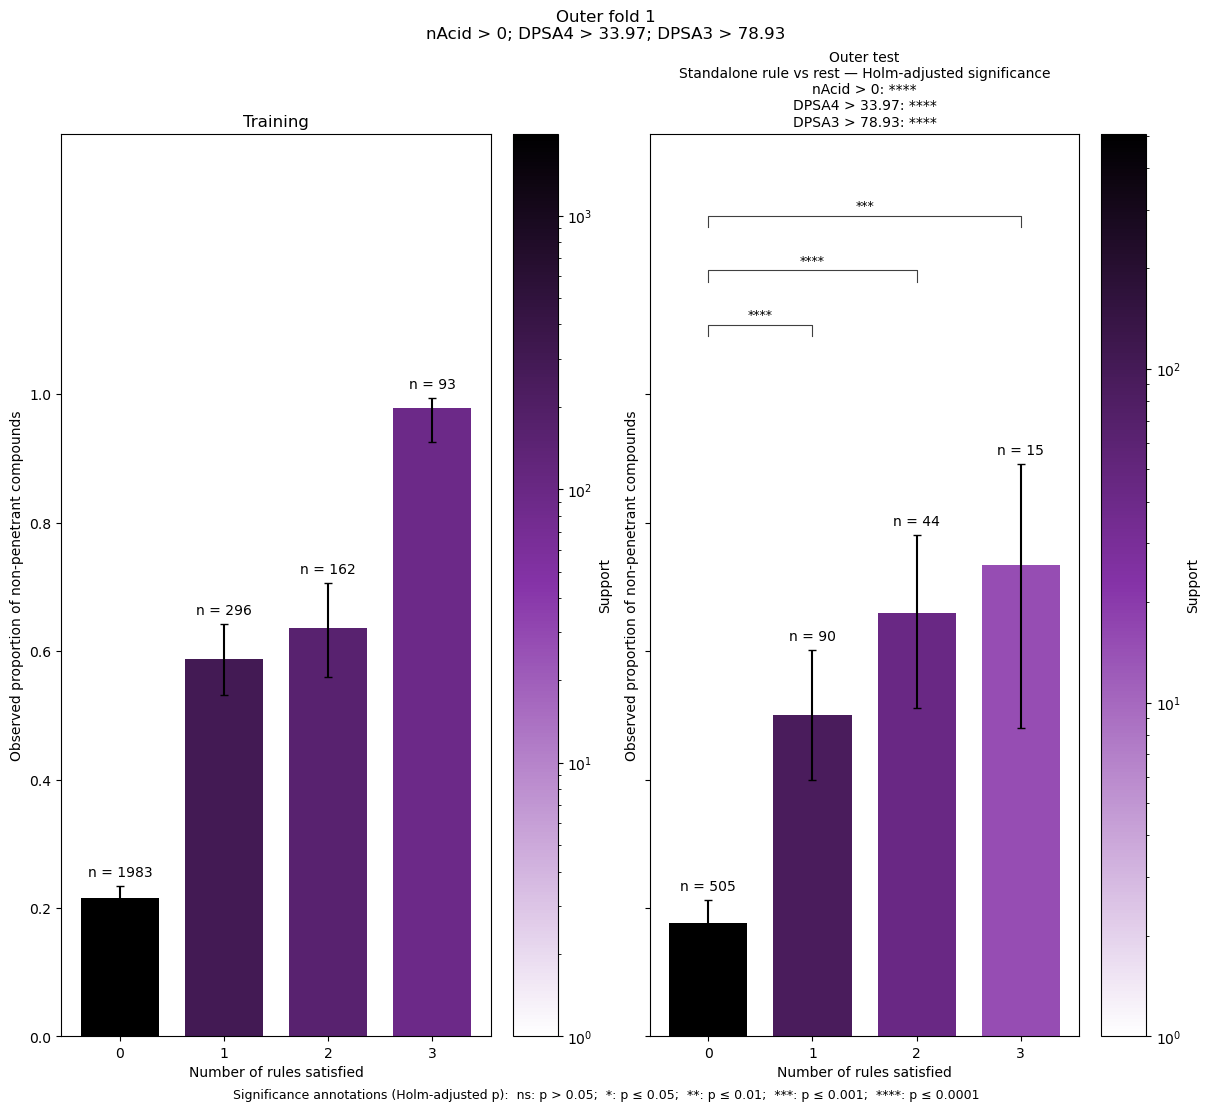

Rule-evaluable rows: 2572/2572
Rule-evaluable rows: 616/616


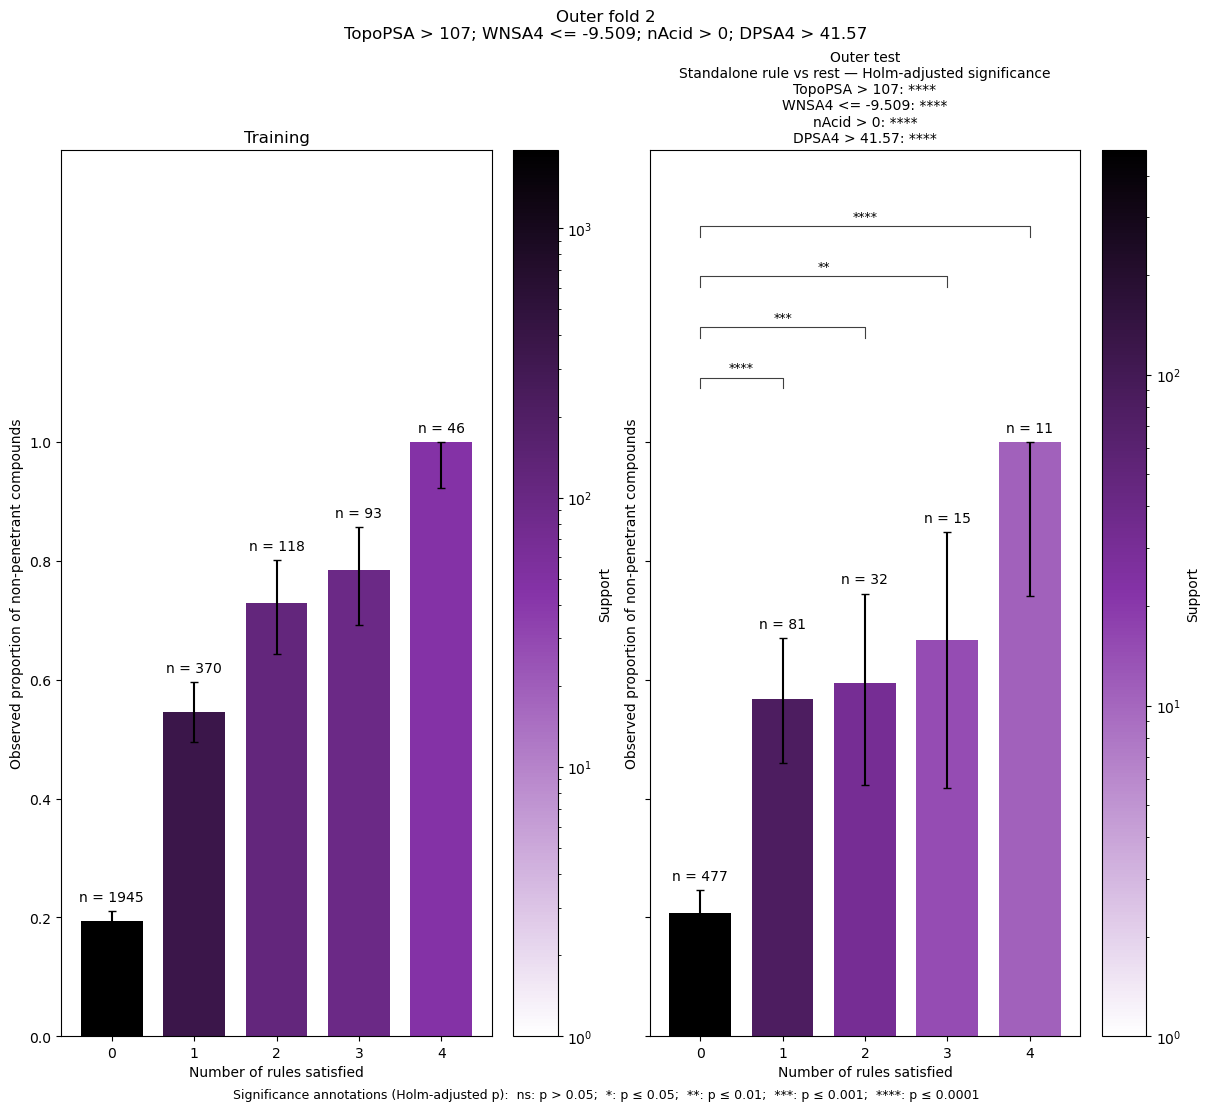

Rule-evaluable rows: 2548/2548
Rule-evaluable rows: 640/640


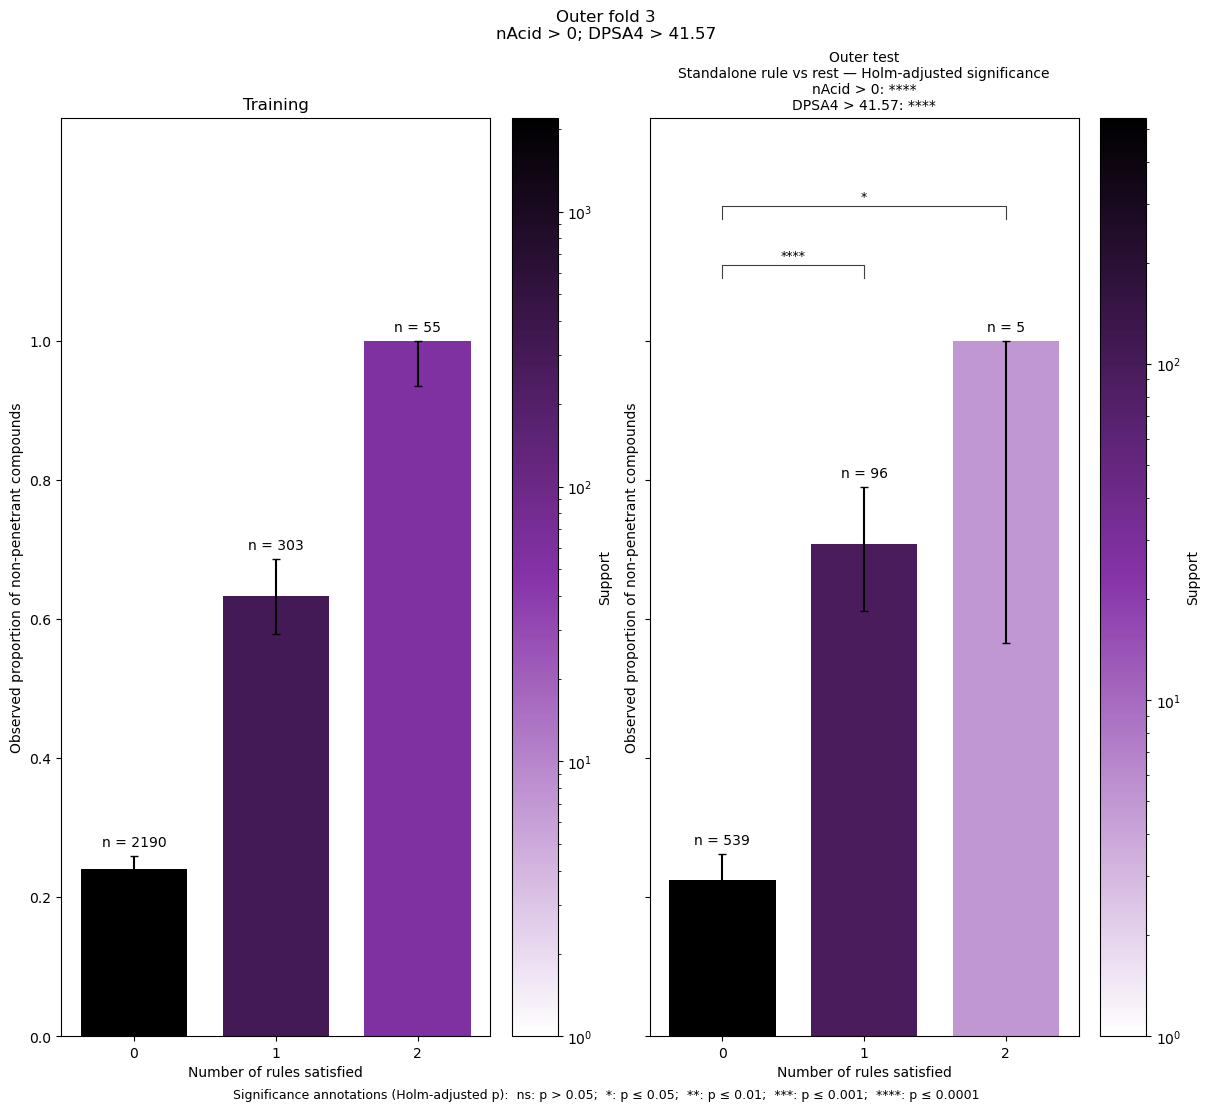

Rule-evaluable rows: 2536/2536
Rule-evaluable rows: 652/652


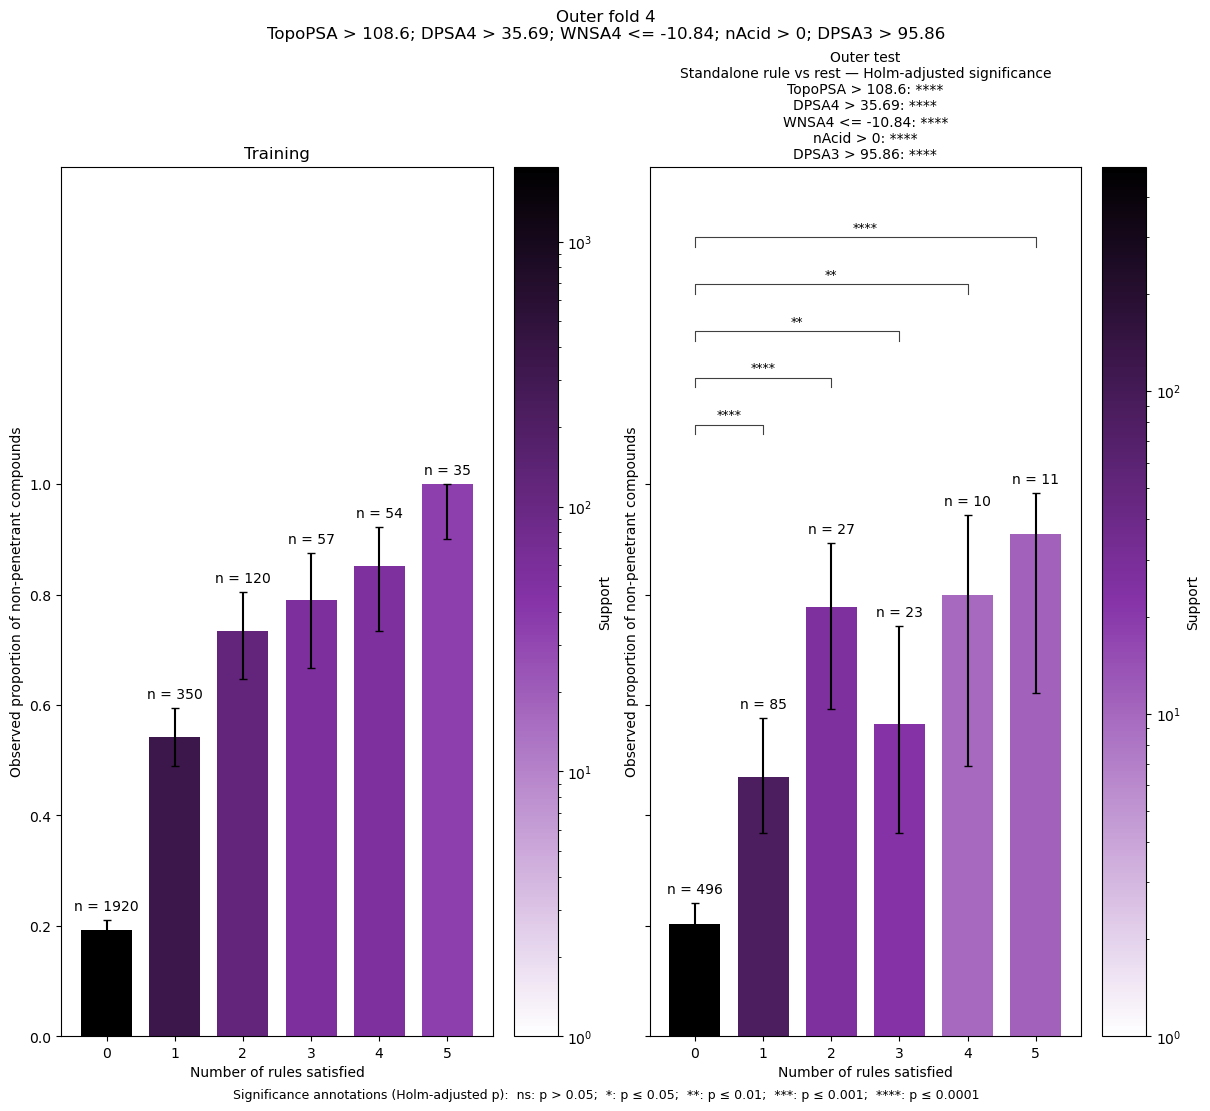

Rule-evaluable rows: 604/604
Rule-evaluable rows: 3188/3188
Rule-evaluable rows: 604/604


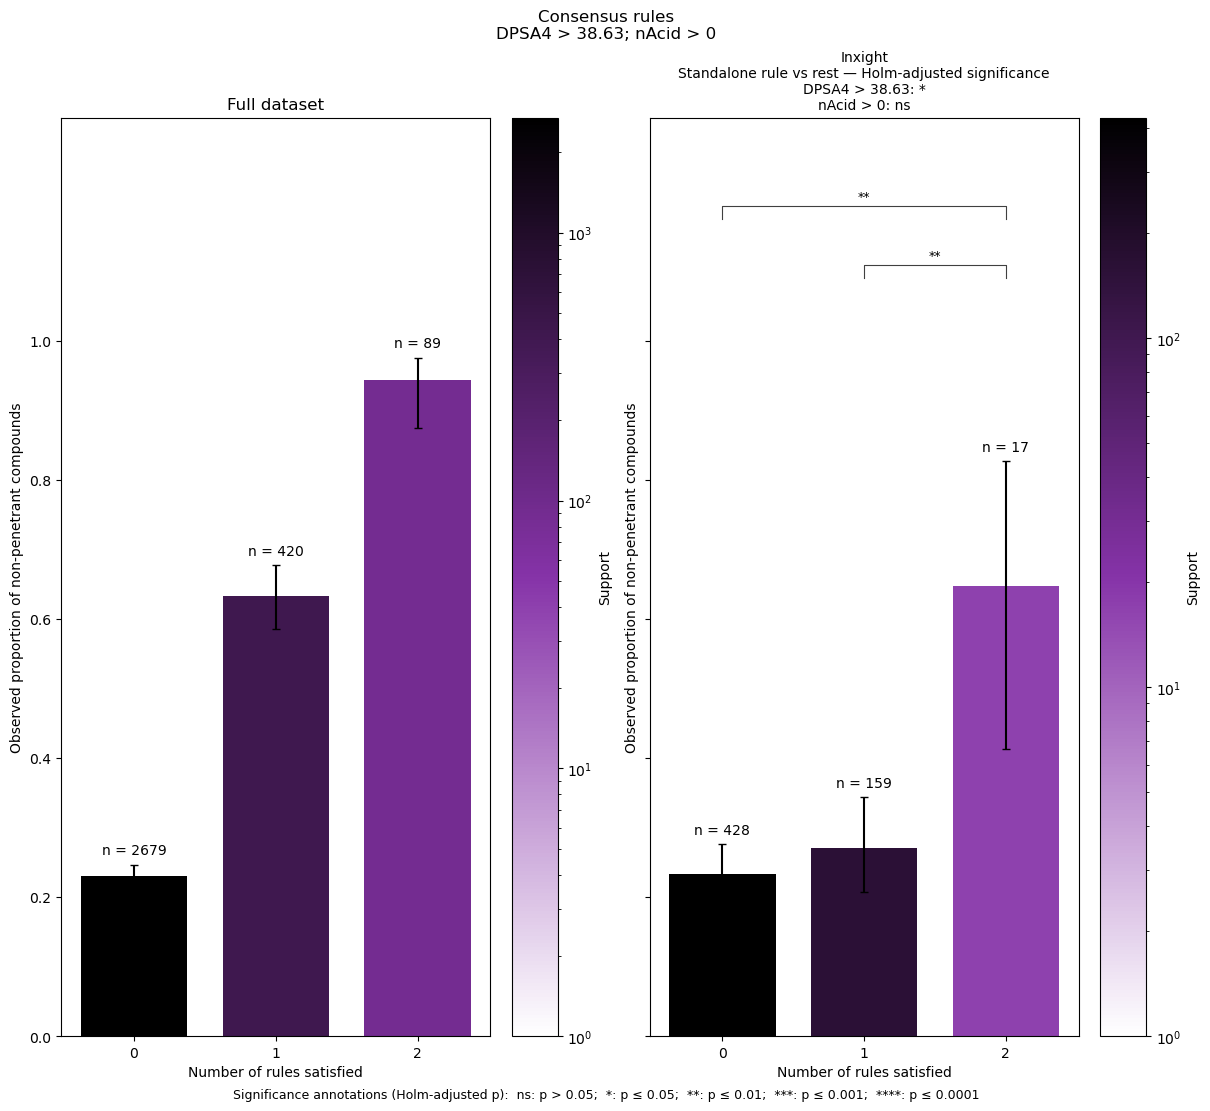

In [20]:
# Run after the current final plotting cell; uses the existing frozen rules.
from itertools import combinations
from scipy.stats import fisher_exact

def count_group_tests(df, chosen):
    summary = rule_summary(df, by_count=True, chosen=chosen)
    rows = []
    for a, b in combinations(range(len(summary)), 2):
        table = summary.iloc[[a, b]][['nonpenetrant', 'penetrant']].to_numpy(dtype=int)
        odds, p = fisher_exact(table, alternative='two-sided') if (table.sum(axis=1) > 0).all() else (np.nan, np.nan)
        rows.append({'group_a': a, 'group_b': b, 'n_a': int(table[0].sum()), 'n_b': int(table[1].sum()),
                     'odds_ratio': odds, 'p_value': p})
    return pd.DataFrame(rows, columns=['group_a', 'group_b', 'n_a', 'n_b', 'odds_ratio', 'p_value'])

def annotate_count_pvalues(ax, tests):
    # Keep all bars; comparisons involving empty groups have no estimable p-value.
    # annotated = combination_tests.loc[combination_tests.p_holm.le(.05)].copy()
    estimable = tests.loc[tests.p_holm.le(.05)].copy()
    estimable['span'] = estimable.group_b - estimable.group_a
    estimable = estimable.sort_values(['span', 'group_a', 'group_b'])
    for level, r in enumerate(estimable.itertuples()):
        y = 1.09 + .085*level
        ax.plot([r.group_a, r.group_a, r.group_b, r.group_b], [y, y+.018, y+.018, y], color='0.25', lw=.8)
        ax.text((r.group_a+r.group_b)/2, y+.023, significance_label(r.p_holm), ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, max(1.2, 1.15+.085*len(estimable)))
    ax.set_yticks(np.arange(0, 1.01, .2))
    add_significance_legend(ax.figure)

# One Holm family across all rule-count comparisons in all outer-test folds.
count_tests = pd.concat([count_group_tests(data.loc[data.outer_fold.eq(f)], chosen).assign(outer_fold=f)
                         for f, chosen in rules_by_outer.items()], ignore_index=True)
count_tests = add_holm(count_tests)
count_tests.to_csv(out/'rule_count_pairwise_outerfold_tests.csv', index=False)

for fold in sorted(rules_by_outer, key=str):
    chosen = rules_by_outer[fold]
    fig, axes = plt.subplots(1, 2, figsize=(12, 11), sharey=True, constrained_layout=True)
    draw_rule_bars(axes[0], data.loc[data.outer_fold.ne(fold)], chosen, 'Training')
    draw_rule_bars(axes[1], data.loc[data.outer_fold.eq(fold)], chosen, 'Outer test')
    if chosen: annotate_pvalues(axes[1], rule_tests.loc[rule_tests.outer_fold.eq(fold)])
    annotate_count_pvalues(axes[1], count_tests.loc[count_tests.outer_fold.eq(fold)])
    rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in chosen)
    fig.suptitle(f'Outer fold {fold}\n{rule_text}', fontsize=12)
    finish(fig, out/f'training_vs_outer_test_{fold}_count_pvalues.png')

if external is not None and consensus_rules:
    # A separate Holm family for the Inxight count-group comparisons.
    inxight_count_tests = add_holm(count_group_tests(external, consensus_rules))
    inxight_count_tests.to_csv(out/'rule_count_pairwise_inxight_tests.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 11), sharey=True, constrained_layout=True)
    draw_rule_bars(axes[0], data, consensus_rules, 'Full dataset')
    draw_rule_bars(axes[1], external, consensus_rules, 'Inxight')
    if consensus_rules: annotate_pvalues(axes[1], external_rule_tests(external, consensus_rules))
    annotate_count_pvalues(axes[1], inxight_count_tests)
    rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in consensus_rules)
    fig.suptitle(f'Consensus rules\n{rule_text}', fontsize=12)
    finish(fig, out/'consensus_full_vs_inxight_count_pvalues.png')


In [21]:
# from pathlib import Path
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.metrics import mutual_info_score


# def rule_mi_curve(df, feature):
#     """MI between class and the binary split at each candidate threshold."""
#     x, y = values(df, feature), values(df, 'bbb_class')
#     valid = np.isfinite(x) & np.isin(y, [0, 1])
#     x, y = x[valid], y[valid]

#     order = np.argsort(x)
#     x, y = x[order], y[order]
#     cuts = np.flatnonzero(x[:-1] < x[1:])

#     if not len(cuts):
#         return pd.DataFrame(columns=['threshold', 'mi']), len(x)

#     # Same calculation and threshold convention as best_mi_split.
#     n_left, pos_left = cuts + 1, np.cumsum(y)[cuts]
#     tables = np.stack(
#         [
#             n_left - pos_left,
#             pos_left,
#             len(y) - n_left - (y.sum() - pos_left),
#             y.sum() - pos_left,
#         ],
#         axis=1,
#     ).reshape(-1, 2, 2)

#     p = tables / len(y)
#     expected = (
#         p.sum(axis=2, keepdims=True)
#         * p.sum(axis=1, keepdims=True)
#     )
#     ratio = np.divide(
#         p, expected, out=np.ones_like(p), where=expected > 0
#     )
#     mi = (
#         p * np.log(np.maximum(ratio, np.finfo(float).tiny))
#     ).sum(axis=(1, 2))

#     return pd.DataFrame({'threshold': x[cuts], 'mi': mi}), len(x)


# def plot_outer_rules_with_mi():
#     destination = Path('./results/deriving_rules/outer_fold_rules_with_mi')
#     destination.mkdir(parents=True, exist_ok=True)

#     for fold in sorted(rules_by_outer, key=str):
#         chosen = rules_by_outer[fold]
#         training = data.loc[data.outer_fold.ne(fold)].copy()
#         testing = data.loc[data.outer_fold.eq(fold)].copy()

#         rows = max(1, len(chosen))
#         fig = plt.figure(figsize=(17, max(8, 2.45 * rows + 2.5)))
#         grid = fig.add_gridspec(
#             rows, 3,
#             width_ratios=[1.15, 1.35, 1.35],
#             left=.065, right=.97, bottom=.10, top=.80,
#             wspace=.43, hspace=.80,
#         )

#         mi_axes = [fig.add_subplot(grid[j, 0]) for j in range(rows)]
#         ax_train = fig.add_subplot(grid[:, 1])
#         ax_test = fig.add_subplot(grid[:, 2])

#         # Reconstruct the training subset at each greedy selection step.
#         current = training.copy()

#         for step, (ax, rule) in enumerate(zip(mi_axes, chosen), 1):
#             feature, direction, threshold = rule
#             curve, n = rule_mi_curve(current, feature)

#             ax.scatter(
#                 curve.threshold, curve.mi,
#                 s=12, color='#F35965', alpha=.65, linewidths=0,
#             )
#             ax.axvline(threshold, color='.3', ls='--', lw=1.1)

#             # Highlight the MI at the already-selected threshold.
#             x = values(current, feature)
#             y = values(current, 'bbb_class')
#             valid = np.isfinite(x) & np.isin(y, [0, 1])

#             selected_mi = (
#                 mutual_info_score(
#                     y[valid], satisfies(current, *rule)[valid]
#                 )
#                 if valid.any() else np.nan
#             )

#             if np.isfinite(selected_mi):
#                 ax.scatter(
#                     threshold, selected_mi,
#                     s=40, color='#F35965', edgecolor='.2',
#                     linewidth=.7, zorder=4,
#                 )

#             ax.set(
#                 xlabel=feature,
#                 ylabel='Mutual information (nats)',
#                 ylim=(0, None),
#             )
#             ax.set_title(
#                 f'Step {step}: {feature} {direction} {threshold:.4g}\n'
#                 f'Training rows at this step: n = {n:,}',
#                 loc='left', fontsize=9,
#             )
#             ax.tick_params(labelsize=8)
#             ax.spines[['top', 'right']].set_visible(False)
#             ax.grid(False)

#             curve.assign(
#                 outer_fold=fold,
#                 step=step,
#                 feature=feature,
#                 selected_threshold=threshold,
#                 n_training=n,
#             ).to_csv(
#                 destination / f'outer_{fold}_mi_step_{step}.csv',
#                 index=False,
#             )

#             current = current.loc[satisfies(current, *rule)].copy()

#         if not chosen:
#             mi_axes[0].text(
#                 .5, .5, 'No rules selected',
#                 ha='center', va='center',
#                 transform=mi_axes[0].transAxes,
#             )
#             mi_axes[0].set_axis_off()

#         # Reuse existing bars, Wilson intervals and support colorbars.
#         draw_rule_bars(ax_train, training, chosen, 'Outer training')
#         draw_rule_bars(ax_test, testing, chosen, 'Held-out outer test')

#         # Reuse the existing adjusted p-values.
#         if chosen:
#             annotate_pvalues(
#                 ax_test,
#                 rule_tests.loc[rule_tests.outer_fold.eq(fold)],
#             )
#         annotate_count_pvalues(
#             ax_test,
#             count_tests.loc[count_tests.outer_fold.eq(fold)],
#         )

#         # Match the proportion scales and retain empty count groups.
#         upper = max(ax_train.get_ylim()[1], ax_test.get_ylim()[1])
#         for ax in [ax_train, ax_test]:
#             ax.set_ylim(0, upper)
#             ax.set_xlim(-.6, len(chosen) + .6)
#             ax.set_yticks(np.arange(0, 1.01, .2))
#             ax.tick_params(labelsize=9)
#             ax.xaxis.label.set_size(10)
#             ax.yaxis.label.set_size(10)
#             ax.spines[['top', 'right']].set_visible(False)
#             ax.grid(False)

#         fig.suptitle(
#             f'Outer fold {fold} — training-selected rules',
#             fontsize=14, y=.975,
#         )
#         fig.text(
#             .065, .855,
#             'Mutual information at each selection step',
#             fontsize=11,
#         )
#         fig.supxlabel(
#             'Bars: 95% Wilson intervals. '
#             'Outer-test comparisons: Holm-adjusted p-values.\n'
#             'ns: p > .05; *: p ≤ .05; **: p ≤ .01; '
#             '***: p ≤ .001; ****: p ≤ .0001',
#             fontsize=9, y=.015,
#         )

#         fig.savefig(
#             destination / f'outer_{fold}_mi_rules.pdf',
#             bbox_inches='tight', dpi=1200,
#         )
#         finish(fig, destination / f'outer_{fold}_mi_rules.png')

#     print(f'Saved figures and MI tables to: {destination.resolve()}')


# plot_outer_rules_with_mi()

Rule-evaluable rows: 2562/2562
Rule-evaluable rows: 626/626


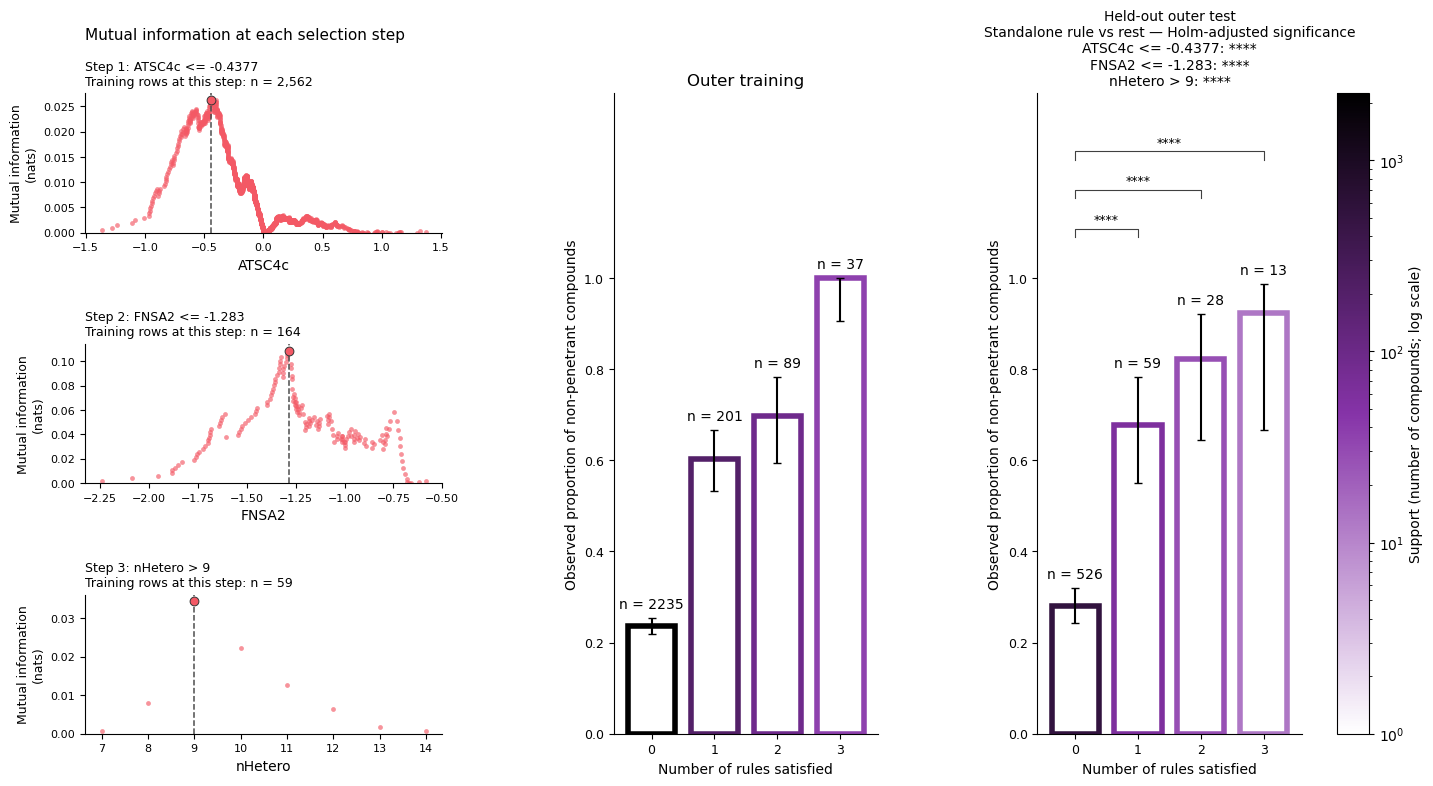

Rule-evaluable rows: 2534/2534
Rule-evaluable rows: 654/654


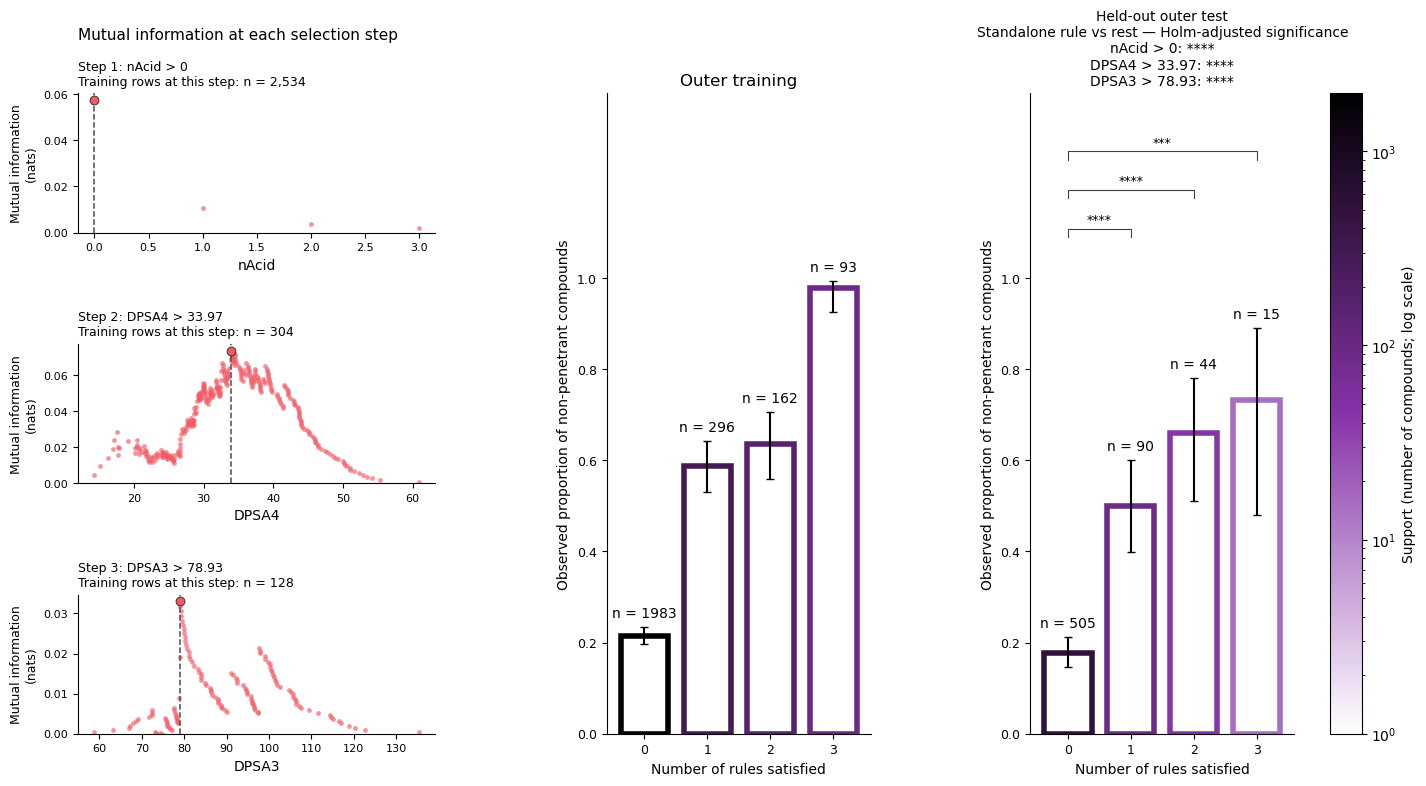

Rule-evaluable rows: 2572/2572
Rule-evaluable rows: 616/616


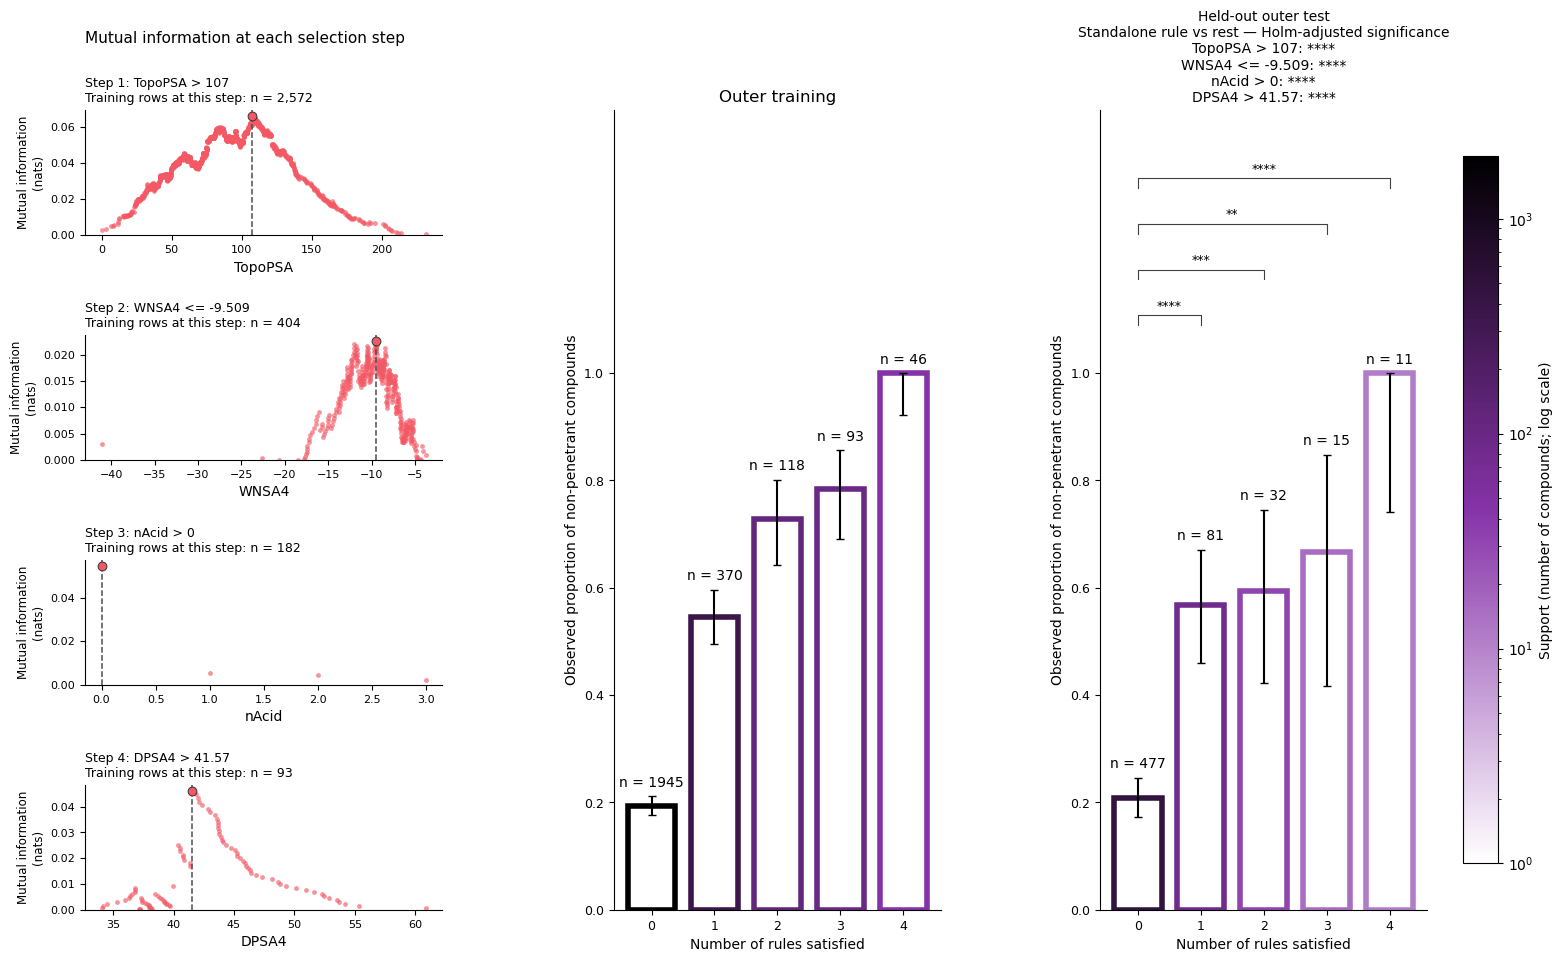

Rule-evaluable rows: 2548/2548
Rule-evaluable rows: 640/640


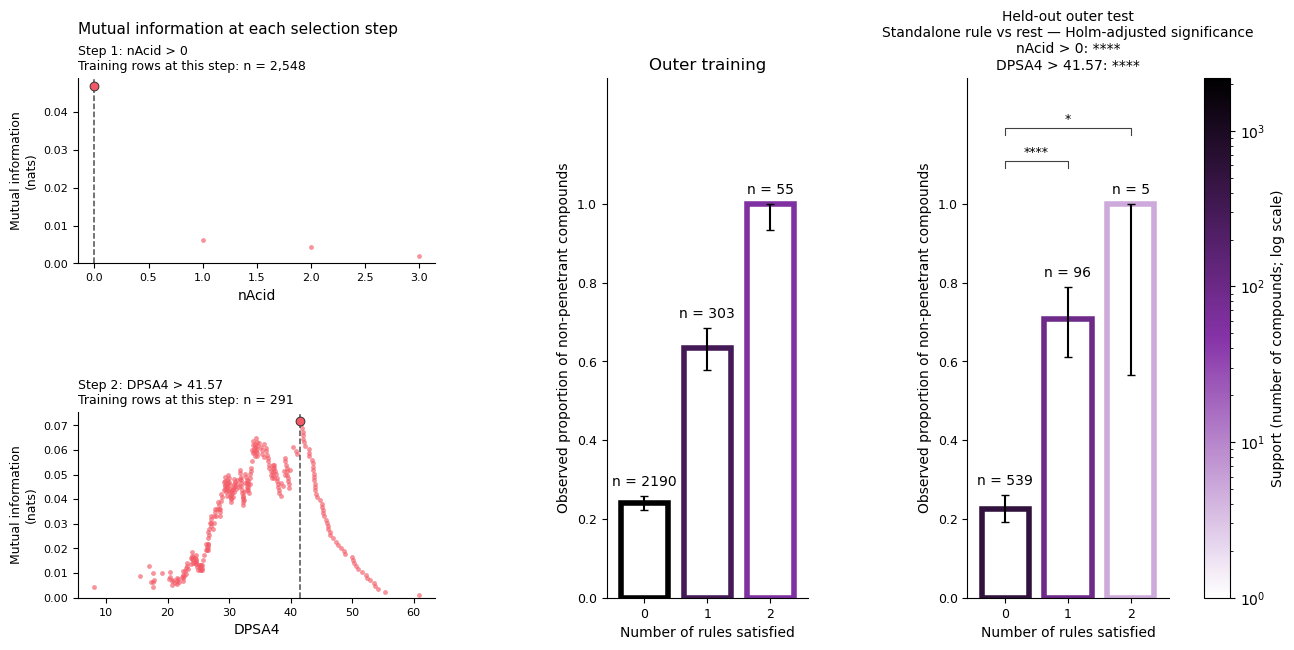

Rule-evaluable rows: 2536/2536
Rule-evaluable rows: 652/652


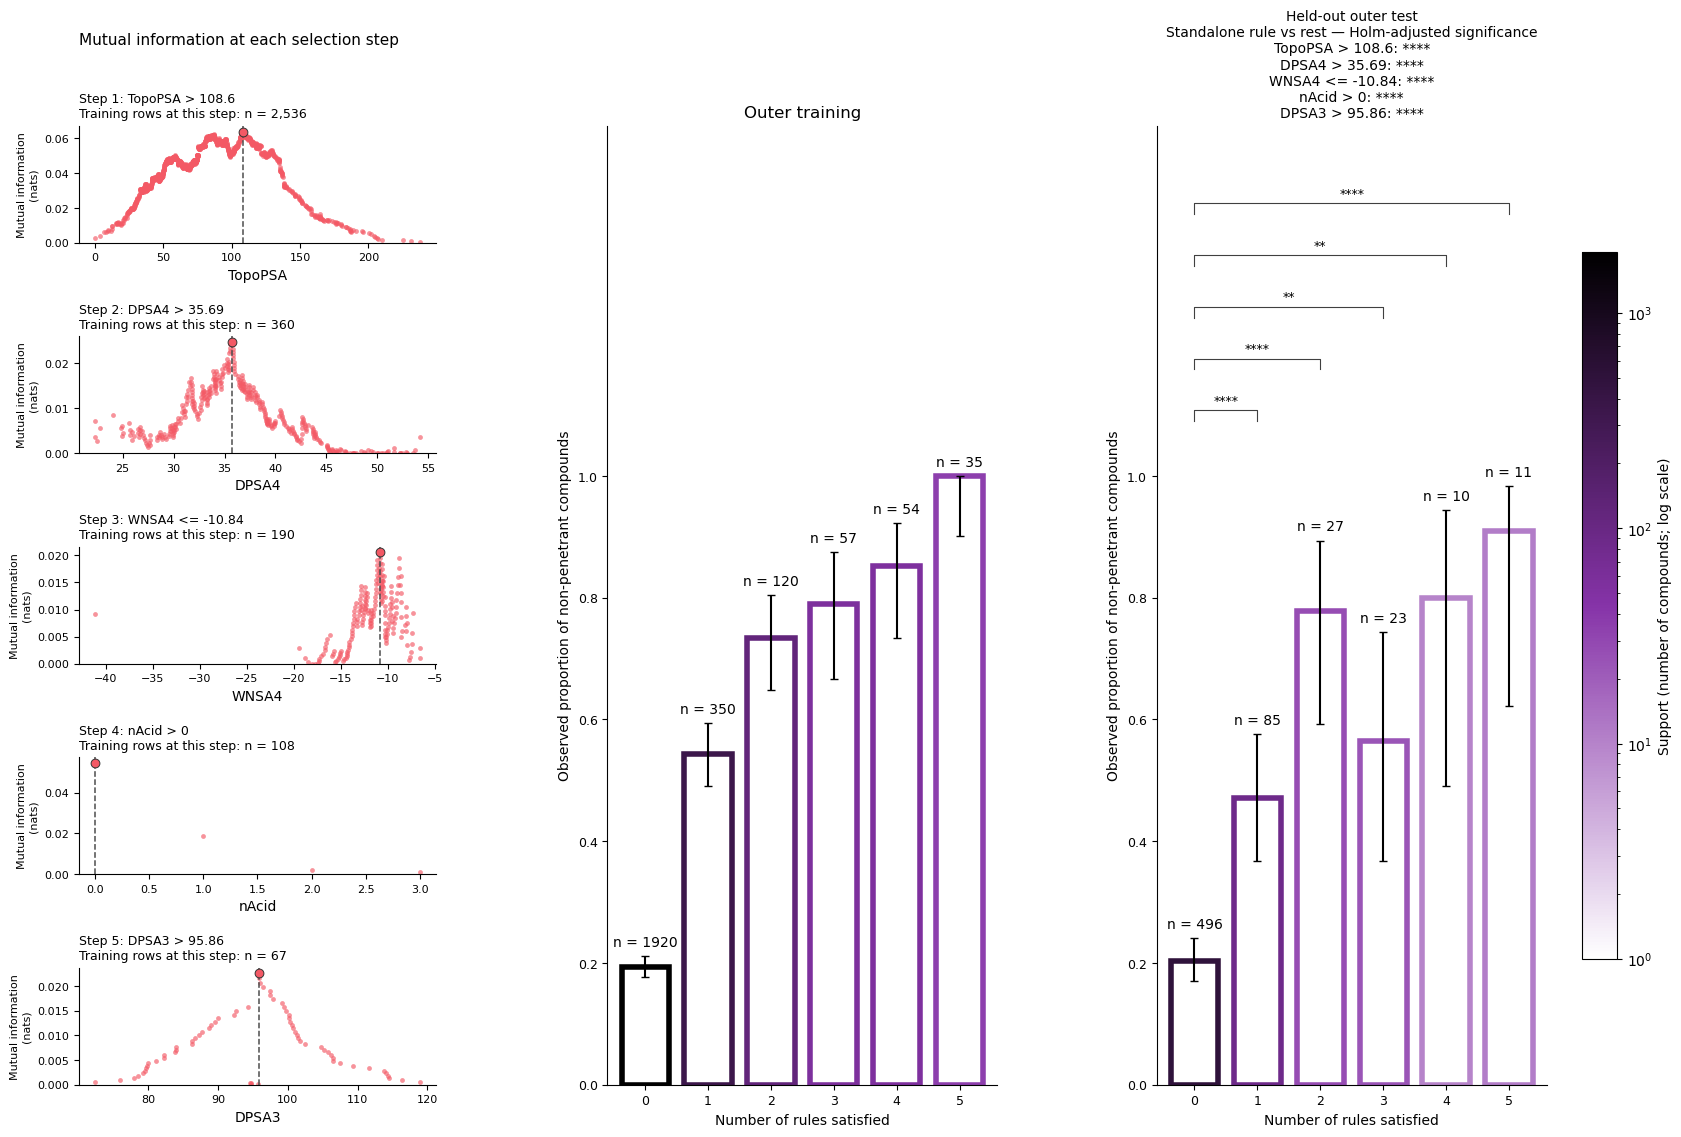

Saved figures and MI tables to: /Users/sziadat/Documents/bbbx/bbb-exc-score/all_revisions_clean/results/deriving_rules/outer_fold_rules_with_mi


In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from sklearn.metrics import mutual_info_score


def rule_mi_curve(df, feature):
    """MI between class and the binary split at each candidate threshold."""
    x, y = values(df, feature), values(df, 'bbb_class')
    valid = np.isfinite(x) & np.isin(y, [0, 1])
    x, y = x[valid], y[valid]
    order = np.argsort(x)
    x, y = x[order], y[order]
    cuts = np.flatnonzero(x[:-1] < x[1:])

    if not len(cuts):
        return pd.DataFrame(columns=['threshold', 'mi']), len(x)

    n_left, pos_left = cuts + 1, np.cumsum(y)[cuts]
    tables = np.stack([
        n_left - pos_left,
        pos_left,
        len(y) - n_left - (y.sum() - pos_left),
        y.sum() - pos_left,
    ], axis=1).reshape(-1, 2, 2)

    p = tables / len(y)
    expected = p.sum(axis=2, keepdims=True) * p.sum(axis=1, keepdims=True)
    ratio = np.divide(p, expected, out=np.ones_like(p), where=expected > 0)
    mi = (p * np.log(np.maximum(ratio, np.finfo(float).tiny))).sum(axis=(1, 2))

    return pd.DataFrame({'threshold': x[cuts], 'mi': mi}), len(x)


def draw_rule_bars_shared(ax, summary, title, norm):
    """Draw bars using a supplied color scale; colorbar is added separately."""
    x = np.arange(len(summary))
    
    ax.bar(x, summary.proportion_nonpenetrant,
           color='white',
           width=.75, edgecolor=custom_cmap(norm(summary.support.clip(lower=1))), linewidth=4.0)
    ax.errorbar(x, summary.proportion_nonpenetrant,
                yerr=np.maximum(0, [summary.error_low, summary.error_high]),
                fmt='none', ecolor='black', capsize=3, zorder=3)

    for i, row in enumerate(summary.itertuples()):
        height = row.ci_high if np.isfinite(row.ci_high) else 0
        ax.annotate(f'n = {int(row.support)}', (i, height), xytext=(0, 7),
                    textcoords='offset points', ha='center')

    ax.set(xticks=x, xticklabels=summary.index, ylim=(0, 1.2),
           xlabel='Number of rules satisfied',
           ylabel='Observed proportion of non-penetrant compounds', title=title)


def plot_outer_rules_with_mi():
    destination = Path('./results/deriving_rules/outer_fold_rules_with_mi')
    destination.mkdir(parents=True, exist_ok=True)

    for fold in sorted(rules_by_outer, key=str):
        chosen = rules_by_outer[fold]
        training = data.loc[data.outer_fold.ne(fold)].copy()
        testing = data.loc[data.outer_fold.eq(fold)].copy()

        rows = max(1, len(chosen))
        fig = plt.figure(figsize=(17, max(8, 2.45 * rows + 2.5)))
        grid = fig.add_gridspec(
            rows, 3, width_ratios=[1.15, 1.35, 1.35],
            left=.065, right=.97, bottom=.15, top=.80,
            wspace=.43, hspace=.80,
        )
        mi_axes = [fig.add_subplot(grid[j, 0]) for j in range(rows)]
        ax_train = fig.add_subplot(grid[:, 1])
        ax_test = fig.add_subplot(grid[:, 2])
        ax_train.set_gid(f'supplementary-rule-training-{fold}')
        ax_test.set_gid(f'supplementary-rule-test-{fold}')

        # Reconstruct the training subset at each greedy selection step.
        current = training.copy()
        for step, (ax, rule) in enumerate(zip(mi_axes, chosen), 1):
            feature, direction, threshold = rule
            curve, n = rule_mi_curve(current, feature)

            ax.scatter(curve.threshold, curve.mi,
                       s=12, color='#F35965', alpha=.65, linewidths=0)
            ax.axvline(threshold, color='.3', ls='--', lw=1.1)

            x, y = values(current, feature), values(current, 'bbb_class')
            valid = np.isfinite(x) & np.isin(y, [0, 1])
            selected_mi = (
                mutual_info_score(y[valid], satisfies(current, *rule)[valid])
                if valid.any() else np.nan
            )
            if np.isfinite(selected_mi):
                ax.scatter(threshold, selected_mi, s=40, color='#F35965',
                           edgecolor='.2', linewidth=.7, zorder=4)

            ax.set(xlabel=feature, ylabel='Mutual information\n(nats)', ylim=(0, None))
            ax.set_gid(f'supplementary-rule-mi-{fold}-{step}')
            ax.yaxis.label.set_fontsize(9)
            ax.yaxis.label.set_clip_on(False)
            ax.set_title(
                f'Step {step}: {feature} {direction} {threshold:.4g}\n'
                f'Training rows at this step: n = {n:,}',
                loc='left', fontsize=9,
            )
            ax.tick_params(labelsize=8)
            ax.spines[['top', 'right']].set_visible(False)
            ax.grid(False)

            curve.assign(
                outer_fold=fold, step=step, feature=feature,
                selected_threshold=threshold, n_training=n,
            ).to_csv(destination / f'outer_{fold}_mi_step_{step}.csv', index=False)

            current = current.loc[satisfies(current, *rule)].copy()

        if not chosen:
            mi_axes[0].text(.5, .5, 'No rules selected', ha='center', va='center',
                            transform=mi_axes[0].transAxes)
            mi_axes[0].set_axis_off()

        # Shared support scale: equal counts have equal colors in both panels.
        train_summary = rule_summary(training, by_count=True, chosen=chosen)
        test_summary = rule_summary(testing, by_count=True, chosen=chosen)
        support_norm = LogNorm(
            vmin=1,
            vmax=max(1.01, train_summary.support.max(), test_summary.support.max()),
        )
        draw_rule_bars_shared(ax_train, train_summary, 'Outer training', support_norm)
        draw_rule_bars_shared(ax_test, test_summary, 'Held-out outer test', support_norm)

        # One colorbar for both panels.
        sm = ScalarMappable(norm=support_norm, cmap=custom_cmap)
        sm.set_array([])
        fig.colorbar(sm, ax=[ax_train, ax_test], fraction=.035, pad=.035).set_label(
            'Support (number of compounds; log scale)'
        )

        # Existing adjusted p-values.
        if chosen:
            annotate_pvalues(ax_test, rule_tests.loc[rule_tests.outer_fold.eq(fold)])
        annotate_count_pvalues(ax_test, count_tests.loc[count_tests.outer_fold.eq(fold)])

        upper = max(ax_train.get_ylim()[1], ax_test.get_ylim()[1])
        for ax in [ax_train, ax_test]:
            ax.set_ylim(0, upper)
            ax.set_xlim(-.6, max(len(r) for r in rules_by_outer.values()) + .6)
            ax.set_yticks(np.arange(0, 1.01, .2))
            ax.tick_params(labelsize=9)
            ax.xaxis.label.set_size(10)
            ax.yaxis.label.set_size(10)
            ax.spines[['top', 'right']].set_visible(False)
            ax.grid(False)

        fig.text(.065, .855, 'Mutual information at each selection step', fontsize=11,
                 gid='supplementary-mi-heading')
        # Annotation helpers add a shared legend; the manuscript supplies that in its caption.
        # Remove it before every numbered and independent export, retaining all panel details.
        if getattr(fig, '_supxlabel', None) is not None:
            fig._supxlabel.remove()
            fig._supxlabel = None

                # Remove unused horizontal space while preserving physical bar widths.
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        for ax in mi_axes:
            label_height = ax.yaxis.label.get_window_extent(renderer).height
            available_height = .9 * ax.get_window_extent(renderer).height
            if label_height > available_height:
                ax.yaxis.label.set_fontsize(ax.yaxis.label.get_fontsize() *
                                           available_height / label_height)
        fig.canvas.draw()
        positions = {a: a.get_position().frozen() for a in fig.axes}
        new_xlim = (-.6, len(chosen) + .6)
        cuts = {
            a: positions[a].width * (
                1 - (new_xlim[1] - new_xlim[0]) / np.diff(a.get_xlim())[0]
            )
            for a in (ax_train, ax_test)
        }
        remaining = 1 - sum(cuts.values())
        fig.set_size_inches(fig.get_figwidth() * remaining, fig.get_figheight())

        # Narrow the rule panels and move subsequent panels/colorbar left.
        for a, p in positions.items():
            shift = sum(
                cut for panel, cut in cuts.items()
                if p.x0 >= positions[panel].x1 - 1e-9
            )
            a.set_position([
                (p.x0 - shift) / remaining, p.y0,
                (p.width - cuts.get(a, 0)) / remaining, p.height,
            ])

        for a in (ax_train, ax_test):
            a.set_xlim(new_xlim)

        # Preserve the MI heading's alignment.
        for text in fig.texts:
            if text.get_ha() == 'left':
                text.set_x(text.get_position()[0] / remaining)

        fig.savefig(destination / f'outer_{fold}_mi_rules.svg', bbox_inches='tight', dpi=1200)
        save_publication(fig, f'S{fold_number_map[fold]+10}',
                         f'Step-conditional MI; outer-training/test rule counts; raw fold {fold}; Wilson CIs and original Holm families.')
        finish(fig, destination / f'outer_{fold}_mi_rules.png')


    print(f'Saved figures and MI tables to: {destination.resolve()}')


plot_outer_rules_with_mi()

## Two-rule consensus combinations
Plot Neither / rule 2 only / rule 1 only / Both. The Inxight title retains the original two standalone-rule-versus-rest p-values, Holm-adjusted together; these test each rule against its complement, rather than all six pairs of combination bars.


In [23]:

# def annotate_pvalues(ax, tests):
#     def stars(p):
#         if not np.isfinite(p): return 'not estimable'
#         return next((s for cutoff, s in [(1e-4, '****'), (1e-3, '***'), (.01, '**'), (.05, '*')] if p <= cutoff), 'ns')

#     if tests.empty: return
#     lines = ['Standalone rule vs rest — Holm-adjusted significance']
#     lines += [f'{r.feature} {r.direction} {r.threshold:.4g}: {stars(r.p_holm)}' for r in tests.itertuples()]
#     ax.set_title(ax.get_title() + '\n' + '\n'.join(lines), fontsize=10)
#     ax.figure.supxlabel(
#         'Significance annotations: ns: p > 0.05; *: p ≤ 0.05; **: p ≤ 0.01; ***: p ≤ 0.001; ****: p ≤ 0.0001',
#         fontsize=9,
#     )
# # Four combination groups for the two frozen consensus rules.
# if len(consensus_rules) != 2: raise ValueError('This plot requires exactly two consensus rules')

# def draw_rule_combinations(ax, df, chosen, title):
#     summary = rule_summary(df, by_count=False, chosen=chosen)
#     x = np.arange(4)
#     norm = LogNorm(vmin=1, vmax=max(1.01, summary.support.max()))
#     ax.bar(x, summary.proportion_nonpenetrant, color=custom_cmap(norm(summary.support.clip(lower=1))), width=.75)
#     ax.errorbar(x, summary.proportion_nonpenetrant, yerr=np.maximum(0, [summary.error_low, summary.error_high]),
#                 fmt='none', ecolor='black', capsize=3, zorder=3)
#     for i, row in enumerate(summary.itertuples()):
#         ax.annotate(f'n = {int(row.support)}', (i, row.ci_high if np.isfinite(row.ci_high) else 0),
#                     xytext=(0, 7), textcoords='offset points', ha='center', fontsize=9)
#     names = [f'{f} {op} {t:.4g}' for f, op, t in chosen]
#     ax.set(xticks=x, xticklabels=['Neither', names[1]+'\nonly', names[0]+'\nonly', 'Both'],
#            ylim=(0, 1.2), xlabel='Rule combination', ylabel='Observed proportion of non-penetrant compounds', title=title)
#     ax.tick_params(axis='x', labelsize=9)
#     sm = cm.ScalarMappable(cmap=custom_cmap, norm=norm)
#     sm.set_array([])
#     ax.figure.colorbar(sm, ax=ax).set_label('Support')
#     return summary

# external = pd.read_csv(EXTERNAL_PATH, low_memory=False)
# fig, axes = plt.subplots(1, 2, figsize=(14, 11), constrained_layout=True)
# full_combinations = draw_rule_combinations(axes[0], data, consensus_rules, 'Full dataset')
# inxight_combinations = draw_rule_combinations(axes[1], external, consensus_rules, 'Inxight')
# # Same standalone-rule-versus-rest tests and Holm correction as your previous plot.
# inxight_rule_tests = external_rule_tests(external, consensus_rules)
# annotate_pvalues(axes[1], inxight_rule_tests)
# rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in consensus_rules)
# fig.suptitle(f'Consensus rules\n{rule_text}', fontsize=12)
# full_combinations.to_csv(out/'consensus_combinations_full.csv')
# inxight_combinations.to_csv(out/'consensus_combinations_inxight.csv')
# inxight_rule_tests.to_csv(out/'consensus_combinations_inxight_rule_tests.csv', index=False)
# finish(fig, out/'consensus_combinations_full_vs_inxight.png')


In [24]:
# from itertools import combinations
# from scipy.stats import fisher_exact
# from statsmodels.stats.multitest import multipletests

# if len(consensus_rules) != 2: raise ValueError('This plot requires exactly two consensus rules')

# def draw_rule_combinations(ax, df, chosen, title):
#     summary = rule_summary(df, by_count=False, chosen=chosen)
#     x = np.arange(4)
#     norm = LogNorm(vmin=1, vmax=max(1.01, summary.support.max()))
#     ax.bar(x, summary.proportion_nonpenetrant, color=custom_cmap(norm(summary.support.clip(lower=1))), width=.75)
#     ax.errorbar(x, summary.proportion_nonpenetrant, yerr=np.maximum(0, [summary.error_low, summary.error_high]),
#                 fmt='none', ecolor='black', capsize=3, zorder=3)
#     for i, row in enumerate(summary.itertuples()):
#         ax.annotate(f'n = {int(row.support)}', (i, row.ci_high if np.isfinite(row.ci_high) else 0),
#                     xytext=(0, 7), textcoords='offset points', ha='center', fontsize=9)
#     names = [f'{f} {op} {t:.4g}' for f, op, t in chosen]
#     ax.set(xticks=x, xticklabels=['Neither', names[1]+'\nonly', names[0]+'\nonly', 'Both'],
#            ylim=(0, 1.2), xlabel='Rule combination', ylabel='Observed proportion of non-penetrant compounds', title=title)
#     ax.tick_params(axis='x', labelsize=9)
#     sm = cm.ScalarMappable(cmap=custom_cmap, norm=norm)
#     sm.set_array([])
#     ax.figure.colorbar(sm, ax=ax).set_label('Support')
#     return summary

# external = pd.read_csv(EXTERNAL_PATH, low_memory=False)
# fig, axes = plt.subplots(1, 2, figsize=(14, 11), sharey=True, constrained_layout=True)
# full_combinations = draw_rule_combinations(axes[0], data, consensus_rules, 'Full dataset')
# inxight_combinations = draw_rule_combinations(axes[1], external, consensus_rules, 'Inxight')

# # Six pairwise comparisons between the four Inxight bars.
# rows = []
# for a, b in combinations(range(4), 2):
#     table = inxight_combinations.iloc[[a, b]][['nonpenetrant', 'penetrant']].to_numpy(dtype=int)
#     odds, p = fisher_exact(table, alternative='two-sided') if (table.sum(axis=1) > 0).all() else (np.nan, np.nan)
#     rows.append({'group_a': a, 'group_b': b, 'label_a': inxight_combinations.index[a],
#                  'label_b': inxight_combinations.index[b], 'n_a': int(table[0].sum()), 'n_b': int(table[1].sum()),
#                  'odds_ratio': odds, 'p_value': p})

# combination_tests = pd.DataFrame(rows)
# combination_tests['p_holm'] = np.nan
# valid = combination_tests.p_value.notna()
# if valid.any(): combination_tests.loc[valid, 'p_holm'] = multipletests(combination_tests.loc[valid, 'p_value'], method='holm')[1]

# # Brackets and stars directly on the Inxight plot.
# annotated = combination_tests.loc[combination_tests.p_holm.le(.05)].copy()
# annotated['span'] = annotated.group_b - annotated.group_a
# annotated = annotated.sort_values(['span', 'group_a', 'group_b'])

# for level, r in enumerate(annotated.itertuples()):
#     label = next((s for cutoff, s in [(1e-4, '****'), (1e-3, '***'), (.01, '**'), (.05, '*')] if r.p_holm <= cutoff), 'ns')
#     y = 1.09 + .085*level
#     axes[1].plot([r.group_a, r.group_a, r.group_b, r.group_b], [y, y+.018, y+.018, y], color='0.25', lw=.8)
#     axes[1].text((r.group_a+r.group_b)/2, y+.023, label, ha='center', va='bottom', fontsize=11)

# for ax in axes:
#     ax.set_ylim(0, max(1.2, 1.15+.085*len(annotated)))
#     ax.set_yticks(np.arange(0, 1.01, .2))

# rule_text = '; '.join(f'{f} {op} {t:.4g}' for f, op, t in consensus_rules)
# fig.suptitle(f'Consensus rules\n{rule_text}', fontsize=12)
# fig.supxlabel('Significance annotations (Holm-adjusted p): ns: p > 0.05; *: p ≤ 0.05; **: p ≤ 0.01; ***: p ≤ 0.001; ****: p ≤ 0.0001', fontsize=9)

# full_combinations.to_csv(out/'consensus_combinations_full.csv')
# inxight_combinations.to_csv(out/'consensus_combinations_inxight.csv')
# combination_tests.to_csv(out/'consensus_combinations_inxight_pairwise_tests.csv', index=False)
# finish(fig, out/'consensus_combinations_full_vs_inxight.png')

Inxight: Neither/penetrant=328, Both/nonpenetrant=11, Both/penetrant=6; missing rule values=0

Neither penetrant vs Both nonpenetrant: maximum Tanimoto = 0.3125; tied best pairs = 1


,member,compound_id,rule_group,bbb_class,SMILES,rule_1_value,rule_2_value
0,A,39,Neither,0,NC(=O)C1=C(O)C=CC=C1,23.195043,0.0
1,B,506,Both,1,OC(=O)C1=CC(=CC=C1O)\N=N\C2=CC(C(O)=O)=C(O)C=C2,45.455128,2.0


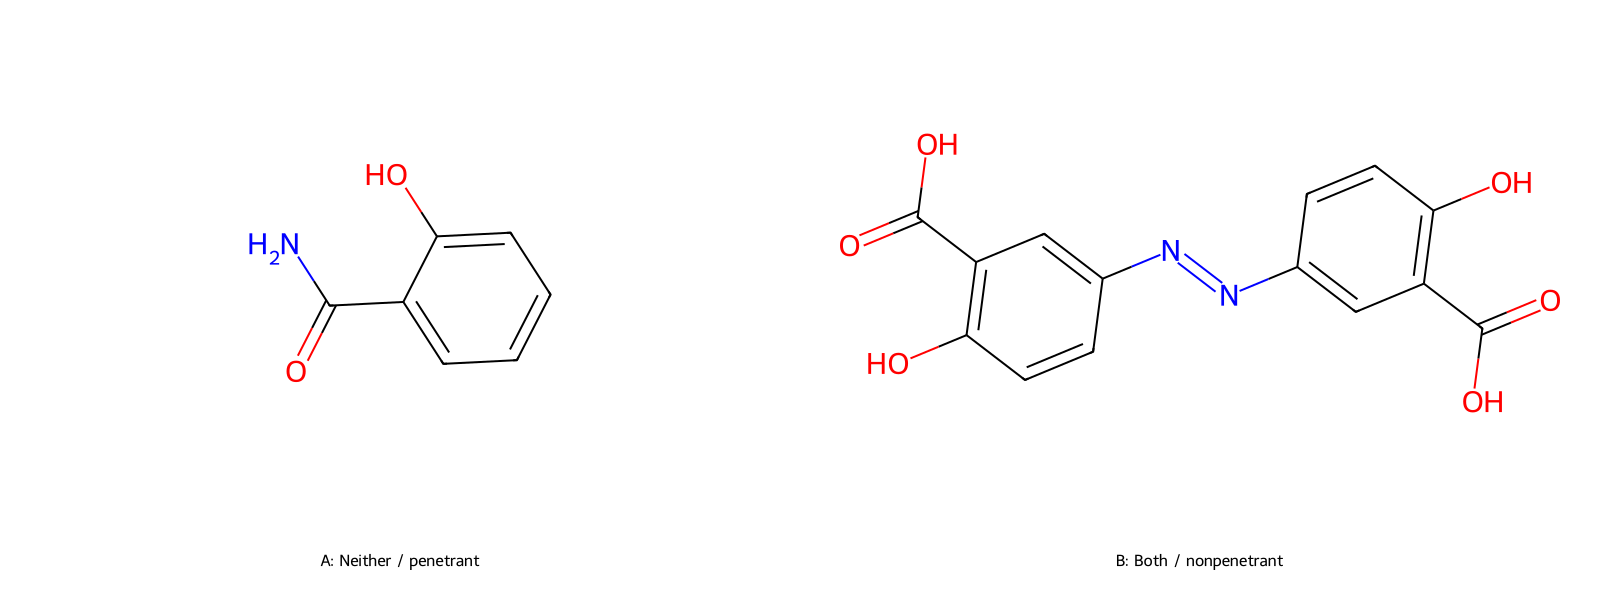


Both penetrant vs Both nonpenetrant: maximum Tanimoto = 0.5111; tied best pairs = 1


,member,compound_id,rule_group,bbb_class,SMILES,rule_1_value,rule_2_value
0,A,40,Both,0,OC(=O)C1=C(O)C=CC(=C1)\N=N\C2=CC=C(C=C2)S(=O)(=O)NC3=NC=CC=C3,40.692135,1.0
1,B,506,Both,1,OC(=O)C1=CC(=CC=C1O)\N=N\C2=CC(C(O)=O)=C(O)C=C2,45.455128,2.0


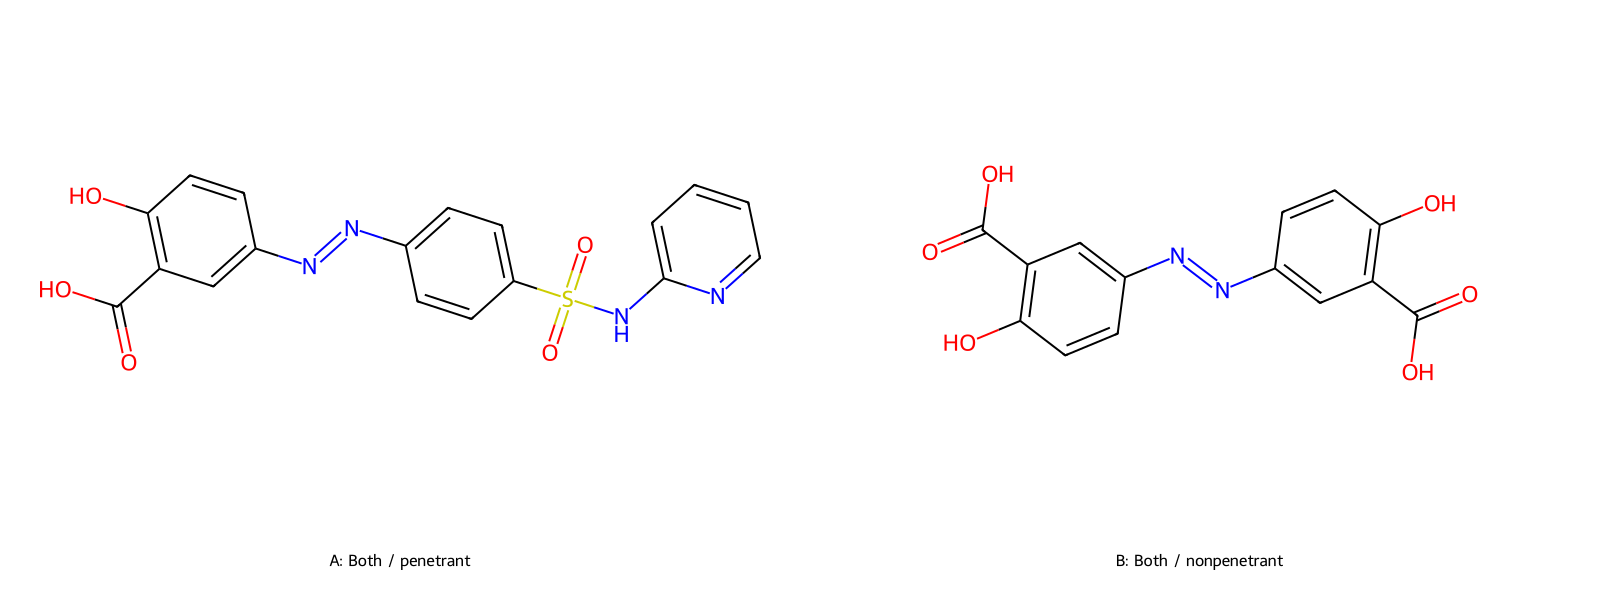


Saved full SMILES, rule values and similarities to results/deriving_rules/outer_0/most_similar_rule_pairs_inxight.csv


In [25]:
similar_pairs = pd.DataFrame()
if external is not None and len(consensus_rules) == 2:
    from rdkit import Chem, DataStructs
    from rdkit.Chem import rdFingerprintGenerator, Draw

    SOURCE, SOURCE_NAME = external, 'Inxight'  # Or: data, 'Full dataset'
    SMILES_COL = next((c for c in ['SMILES', 'smiles', 'canonical_smiles'] if c in SOURCE), None)
    if SMILES_COL is None: raise ValueError('Set SMILES_COL to your SMILES column')
    if len(consensus_rules) != 2: raise ValueError('Exactly two consensus rules are required')

    pair_data = SOURCE.copy().reset_index(drop=True)
    y = pd.to_numeric(pair_data['bbb_class'], errors='raise').to_numpy(dtype=float)
    if not np.isin(y, [0, 1]).all(): raise ValueError('bbb_class must be 0 = penetrant, 1 = nonpenetrant')

    rule_values = np.column_stack([values(pair_data, f) for f, _, _ in consensus_rules])
    known = np.isfinite(rule_values).all(axis=1)
    hits = np.column_stack([satisfies(pair_data, *r) for r in consensus_rules]).sum(axis=1)
    neither_p = np.flatnonzero(known & (hits == 0) & (y == 0))
    both_np = np.flatnonzero(known & (hits == 2) & (y == 1))
    both_p = np.flatnonzero(known & (hits == 2) & (y == 0))
    print(f'{SOURCE_NAME}: Neither/penetrant={len(neither_p)}, Both/nonpenetrant={len(both_np)}, '
          f'Both/penetrant={len(both_p)}; missing rule values={int((~known).sum())}')

    # Morgan fingerprints: radius 2, 2048 bits, chirality included.
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, includeChirality=True)
    mols, fingerprints, canonical = {}, {}, {}
    for i in np.unique(np.concatenate([neither_p, both_np, both_p])):
        smiles = pair_data.at[i, SMILES_COL]
        mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) and smiles.strip() else None
        if mol is None or mol.GetNumAtoms() == 0:
            raise ValueError(f'Missing/invalid SMILES at source row {i}: {smiles!r}')
        mols[i] = mol
        fingerprints[i] = generator.GetFingerprint(mol)
        canonical[i] = Chem.MolToSmiles(mol, isomericSmiles=True)

    def closest_pair(a, b):
        """Search every cross-group pair; ties retain the first pair in source-row order."""
        if not len(a) or not len(b): return None
        b_fps = [fingerprints[j] for j in b]
        best, tied = None, 0
        for i in a:
            similarities = np.asarray(DataStructs.BulkTanimotoSimilarity(fingerprints[i], b_fps))
            k = int(similarities.argmax())
            score = float(similarities[k])
            n_ties = int((similarities == score).sum())
            if best is None or score > best[0]:
                best, tied = (score, int(i), int(b[k])), n_ties
            elif score == best[0]:
                tied += n_ties
        return (*best, tied)

    id_col = next((c for c in ['external_compound_id', 'sample_id', 'compound_id', 'id'] if c in pair_data), None)
    rows = []
    for comparison, a in [('Neither penetrant vs Both nonpenetrant', neither_p),
                          ('Both penetrant vs Both nonpenetrant', both_p)]:
        best = closest_pair(a, both_np)
        if best is None:
            print(f'{comparison}: no eligible pair (one or both groups are empty).')
            continue
        score, i, j, tied = best
        same_structure = canonical[i] == canonical[j]
        print(f'\n{comparison}: maximum Tanimoto = {score:.4f}; tied best pairs = {tied}')
        if same_structure:
            print('NOTE: these rows have identical canonical SMILES but opposing BBB labels.')
        pair_rows, legends = [], []
        for member, k in [('A', i), ('B', j)]:
            group = 'Neither' if hits[k] == 0 else 'Both'
            label = 'penetrant' if y[k] == 0 else 'nonpenetrant'
            row = {'comparison': comparison, 'source': SOURCE_NAME, 'member': member,
                   'row_position': k, 'compound_id': pair_data.at[k, id_col] if id_col else k,
                   'bbb_class': int(y[k]), 'rule_group': group, 'SMILES': pair_data.at[k, SMILES_COL],
                   'canonical_SMILES': canonical[k], 'tanimoto': score, 'tied_best_pairs': tied,
                   'same_canonical_SMILES': same_structure}
            for r, (feature, op, threshold) in enumerate(consensus_rules):
                row[f'rule_{r+1}'] = f'{feature} {op} {threshold!r}'
                row[f'rule_{r+1}_value'] = rule_values[k, r]
            pair_rows.append(row)
            legends.append(f'{member}: {group} / {label}')
        rows.extend(pair_rows)
        with pd.option_context('display.max_colwidth', None):
            display(pd.DataFrame(pair_rows)[['member', 'compound_id', 'rule_group', 'bbb_class',
                                            'SMILES', 'rule_1_value', 'rule_2_value']])
        pair_stem = out / ('most_similar_rule_pair_' + ('neither_vs_both' if len(rows) == 2 else 'both_opposing_labels'))
        pair_image = Draw.MolsToGridImage([mols[i], mols[j]], molsPerRow=2,
                                        subImgSize=(800, 600), legends=legends, returnPNG=False)
        if hasattr(pair_image, 'save'):
            pair_image.save(pair_stem.with_suffix('.png'))
        else:
            pair_stem.with_suffix('.png').write_bytes(pair_image.data)
        pair_svg = Draw.MolsToGridImage(
            [mols[i], mols[j]], molsPerRow=2, subImgSize=(500, 350), legends=legends, useSVG=True)
        pair_stem.with_suffix('.svg').write_text(pair_svg.data if hasattr(pair_svg, 'data') else pair_svg)
        display(pair_image)

    similar_pairs = pd.DataFrame(rows)
    if not similar_pairs.empty:
        pair_output = out / f'most_similar_rule_pairs_{SOURCE_NAME.lower().replace(" ", "_")}.csv'
        similar_pairs.to_csv(pair_output, index=False)
        print(f'\nSaved full SMILES, rule values and similarities to {pair_output}')
else:
    print('Molecule examples need external data and exactly two consensus rules.')


In [26]:
# consider the predicted molecules too. 

Rule-evaluable rows: 3188/3188
Rule-evaluable rows: 604/604


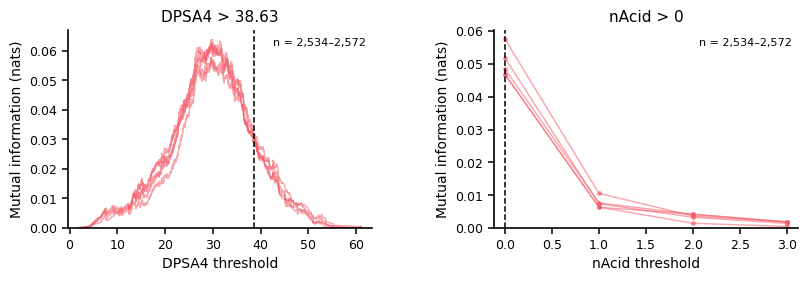

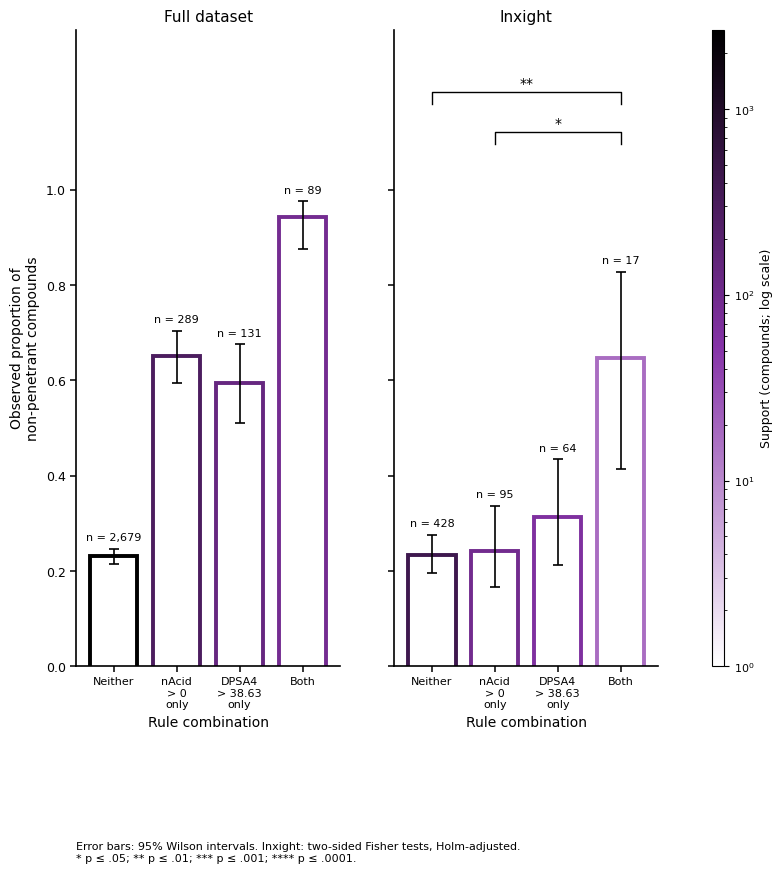

Saved PDF, SVG, PNG and CSV files to: /Users/sziadat/Documents/bbbx/bbb-exc-score/all_revisions_clean/results/deriving_rules/main_figure_panels


In [27]:
if external is not None and len(consensus_rules) == 2:
    from pathlib import Path
    from itertools import combinations
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.colors import LogNorm
    from matplotlib.cm import ScalarMappable
    from scipy.stats import fisher_exact
    from statsmodels.stats.multitest import multipletests

    # ── IMAGE SIZE CONTROLS: (width, height) in inches ──
    MI_SIZE = (10.0, 2.75)
    BAR_SIZE = (8, 9.5)

    MI_COLOR = "#F35965"
    BAR_WIDTH = .75
    EDGE_WIDTH = 2.8

    DEST = Path("./results/deriving_rules/main_figure_panels")
    DEST.mkdir(parents=True, exist_ok=True)

    main_rules = list(consensus_rules)
    if len(main_rules) != 2:
        raise ValueError("This figure requires exactly two consensus rules.")
    if data.outer_fold.isna().any():
        raise ValueError("Missing outer-fold assignments.")


    def rule_mi_curve(df, feature):
        """MI between BBB class and each binary threshold split, in nats."""
        x = pd.to_numeric(df[feature], errors="coerce").to_numpy(dtype=float, na_value=np.nan)
        y = pd.to_numeric(df["bbb_class"], errors="coerce").to_numpy(dtype=float, na_value=np.nan)
        valid = np.isfinite(x) & np.isin(y, [0, 1])
        x, y = x[valid], y[valid]

        order = np.argsort(x)
        x, y = x[order], y[order]
        cuts = np.flatnonzero(x[:-1] < x[1:])

        if not len(cuts):
            return pd.DataFrame(columns=["threshold", "mi"]), len(x)

        n_left, pos_left = cuts + 1, np.cumsum(y)[cuts]
        pos_right = y.sum() - pos_left
        tables = np.stack([
            n_left - pos_left, pos_left,
            len(y) - n_left - pos_right, pos_right,
        ], axis=1).reshape(-1, 2, 2)

        p = tables / len(y)
        expected = p.sum(axis=2, keepdims=True) * p.sum(axis=1, keepdims=True)
        ratio = np.divide(p, expected, out=np.ones_like(p), where=expected > 0)
        mi = (p * np.log(np.maximum(ratio, np.finfo(float).tiny))).sum(axis=(1, 2))
        return pd.DataFrame({"threshold": x[cuts], "mi": mi}), len(x)


    def clean_axes(ax):
        ax.set_facecolor("white")
        ax.spines[["top", "right"]].set_visible(False)
        for side in ["left", "bottom"]:
            ax.spines[side].set_linewidth(1.2)
            ax.spines[side].set_color("black")
        ax.tick_params(direction="out", width=1.1, length=4, labelsize=9)
        ax.grid(False)


    def save_panel(fig, name):
        for extension in ["pdf", "svg", "png"]:
            fig.savefig(
                DEST / f"{name}.{extension}",
                bbox_inches="tight", pad_inches=.08,
                dpi=600, facecolor="white",
            )


    def stars(p):
        return next(
            (s for cutoff, s in [
                (1e-4, "****"), (1e-3, "***"), (.01, "**"), (.05, "*")
            ] if p <= cutoff),
            "ns",
        )


    with plt.rc_context({
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "path",
        "figure.facecolor": "white",
    }):
        # MI column: complete outer-training partitions.
        folds = sorted(data.outer_fold.unique(), key=str)
        fig_mi, mi_axes = plt.subplots(1, 2, figsize=MI_SIZE)
        fig_mi.subplots_adjust(
            left=.23, right=.96, bottom=.19, top=.91, wspace=.40
        )
        curve_tables = []

        for ax, (feature, direction, threshold) in zip(mi_axes, main_rules):
            sizes = []
            for fold in folds:
                outer_training = data.loc[data.outer_fold.ne(fold)]
                curve, n = rule_mi_curve(outer_training, feature)
                sizes.append(n)

                ax.plot(
                    curve.threshold, curve.mi,
                    color=MI_COLOR, lw=1.0, alpha=.55,
                    marker="o" if len(curve) <= 25 else None,
                    markersize=2.5,
                )
                curve_tables.append(curve.assign(
                    outer_fold=fold,
                    feature=feature,
                    n_training=n,
                    consensus_threshold=threshold,
                    subset="full_outer_training",
                ))

            ax.axvline(threshold, color="black", ls="--", lw=1.1, zorder=4)
            ax.set(
                xlabel=f"{feature} threshold",
                ylabel="Mutual information (nats)",
                title=f"{feature} {direction} {threshold:.4g}",
                ylim=(0, None),
            )
            ax.text(
                .98, .96, f"n = {min(sizes):,}–{max(sizes):,}",
                transform=ax.transAxes,
                ha="right", va="top", fontsize=8,
            )
            ax.margins(x=.04)
            clean_axes(ax)

        # fig_mi.text(
        #     .23, .015,
        #     f"Coral curves: {len(folds)} full outer-training partitions.\n"
        #     "Dashed lines: frozen consensus thresholds.",
        #     fontsize=8, va="bottom",
        # )
        pd.concat(curve_tables, ignore_index=True).to_csv(
            DEST / "main_features_outer_training_mi.csv", index=False
        )
        save_panel(fig_mi, "main_mi_column")

        # Main bars: full dataset and Inxight.
        summaries = [
            rule_summary(data, by_count=False, chosen=main_rules),
            rule_summary(external, by_count=False, chosen=main_rules),
        ]
        norm = LogNorm(
            vmin=1,
            vmax=max(1.01, *(float(s.support.max()) for s in summaries)),
        )
        names = [
            f"{feature}\n{direction} {threshold:.4g}\nonly"
            for feature, direction, threshold in main_rules
        ]
        labels = ["Neither", names[1], names[0], "Both"]

        fig_bars = plt.figure(figsize=BAR_SIZE)
        grid = fig_bars.add_gridspec(
            1, 3, width_ratios=[1, 1, .045],
            left=.10, right=.91, bottom=.23, top=.90, wspace=.30,
        )
        ax_full = fig_bars.add_subplot(grid[0, 0])
        ax_external = fig_bars.add_subplot(grid[0, 1], sharey=ax_full)
        cax = fig_bars.add_subplot(grid[0, 2])

        for ax, summary, title in zip(
            [ax_full, ax_external], summaries, ["Full dataset", "Inxight"]
        ):
            x = np.arange(len(summary))

            ax.bar(
                x, summary.proportion_nonpenetrant,
                width=BAR_WIDTH, facecolor="white", edgecolor="none", zorder=2,
            )

            # Three-sided outlines: left, top and right.
            for xi, height, support in zip(
                x, summary.proportion_nonpenetrant, summary.support
            ):
                if np.isfinite(height):
                    left, right = xi - BAR_WIDTH / 2, xi + BAR_WIDTH / 2
                    ax.plot(
                        [left, left, right, right], [0, height, height, 0],
                        color=custom_cmap(norm(max(1, support))),
                        linewidth=EDGE_WIDTH,
                        solid_capstyle="butt", solid_joinstyle="miter",
                        zorder=2.5,
                    )

            ax.errorbar(
                x, summary.proportion_nonpenetrant,
                yerr=np.maximum(
                    0, np.array([summary.error_low, summary.error_high])
                ),
                fmt="none", ecolor="black",
                elinewidth=1.2, capsize=3.5, capthick=1.2, zorder=3,
            )

            for i, row in enumerate(summary.itertuples()):
                height = row.ci_high if np.isfinite(row.ci_high) else 0
                ax.annotate(
                    f"n = {int(row.support):,}", (i, height),
                    xytext=(0, 6), textcoords="offset points",
                    ha="center", fontsize=8,
                )

            ax.set(
                xticks=x, xticklabels=labels, xlim=(-.6, 3.6),
                yticks=np.arange(0, 1.01, .2),
                xlabel="Rule combination", title=title,
            )
            clean_axes(ax)
            ax.tick_params(axis="x", labelsize=8)

        ax_full.set_ylabel("Observed proportion of\nnon-penetrant compounds")
        ax_external.tick_params(labelleft=False)

        # Six pairwise Inxight combination comparisons, Holm-adjusted.
        test_rows = []
        for a, b in combinations(range(4), 2):
            table = summaries[1].iloc[[a, b]][
                ["nonpenetrant", "penetrant"]
            ].to_numpy(dtype=int)

            p = (
                fisher_exact(table, alternative="two-sided")[1]
                if (table.sum(axis=1) > 0).all() else np.nan
            )
            test_rows.append({
                "group_a": a,
                "group_b": b,
                "label_a": labels[a].replace("\n", " "),
                "label_b": labels[b].replace("\n", " "),
                "p_value": p,
            })

        main_tests = pd.DataFrame(test_rows)
        main_tests["p_holm"] = np.nan
        valid = main_tests.p_value.notna()
        if valid.any():
            main_tests.loc[valid, "p_holm"] = multipletests(
                main_tests.loc[valid, "p_value"], method="holm"
            )[1]

        significant = main_tests.loc[main_tests.p_holm.le(.05)].copy()
        significant["span"] = significant.group_b - significant.group_a
        significant = significant.sort_values(["span", "group_a", "group_b"])

        tops = pd.concat([s.ci_high for s in summaries]).dropna()
        base = max(1.02, (tops.max() if len(tops) else 1) + .12)

        for level, row in enumerate(significant.itertuples()):
            y = base + .085 * level
            a, b = row.group_a, row.group_b
            ax_external.plot(
                [a, a, b, b], [y, y + .025, y + .025, y],
                color="black", lw=1, clip_on=False,
            )
            ax_external.text(
                (a + b) / 2, y + .028, stars(row.p_holm),
                ha="center", va="bottom", fontsize=10,
            )

        ax_full.set_ylim(0, base + .085 * len(significant) + .07)

        cbar = fig_bars.colorbar(
            ScalarMappable(norm=norm, cmap=custom_cmap), cax=cax
        )
        cbar.set_label("Support (compounds; log scale)", fontsize=9)
        cbar.ax.tick_params(labelsize=8)
        cbar.outline.set_linewidth(.8)

        fig_bars.text(
            .10, .025,
            "Error bars: 95% Wilson intervals. "
            "Inxight: two-sided Fisher tests, Holm-adjusted.\n"
            "* p ≤ .05; ** p ≤ .01; *** p ≤ .001; **** p ≤ .0001.",
            fontsize=8,
        )

        for summary, name in zip(summaries, ["full_dataset", "inxight"]):
            summary.to_csv(DEST / f"main_combinations_{name}.csv")
        main_tests.to_csv(
            DEST / "main_inxight_combination_tests.csv", index=False
        )
        save_panel(fig_bars, "main_rule_bars")
        plt.show()
        plt.close(fig_mi)
        plt.close(fig_bars)
        gc.collect()

    print(f"Saved PDF, SVG, PNG and CSV files to: {DEST.resolve()}")
else:
    print('Existing main MI/bar panel exports need external data and exactly two consensus rules.')


## Complete descriptor figures: Figure 3 and S4–S10
The individual fold figures use their own training-derived top ten. The union figures use five outer-training partitions. Figure 3b–c retains the selected fold's five inner-training subsets. Supply the original held-out grouped-SHAP data for panel 3a; training-ranking values are never substituted.

**`grouped_shap` schema:** `cluster,feature,n_members,outer_fold,mean_abs_group_shap`, with each stable cluster represented in all five folds; optional `members_json` is checked for identical membership. Alternatively, a saved summary uses `cluster,feature,n_members,mean,sd,n_folds`, with `n_folds=5`. The importance scale must be the paper's mean absolute grouped SHAP scale. Select the intended model before supplying the file, or rename columns explicitly using `column_map`.


In [28]:
# Figure 3 and Figures S4-S10. No held-out row is used to choose a rule or a feature.
publication_gam_cache = {}

def descriptor_curve(training, feature, reference, grid=None, cache_key=None):
    key = (cache_key, feature)
    x, y = values(training, feature), values(training, 'logBB')
    valid = np.isfinite(x) & measured(training)
    if valid.sum() < 6 or np.unique(x[valid]).size < 2:
        raise FigureInputError(f'{feature}: too few measured, varying training values for a GAM.')
    if key not in publication_gam_cache:
        publication_gam_cache[key] = LinearGAM(n_splines=5).gridsearch(
            x[valid, None], y[valid], progress=False)
    if grid is None:
        r = values(reference, feature)
        r = r[np.isfinite(r)]
        if not len(r) or np.ptp(r) == 0:
            raise FigureInputError(f'{feature}: no varying reference values.')
        grid = np.linspace(r.min(), r.max(), 500)[:, None]
    gam = publication_gam_cache[key]
    return gam, grid, valid

def draw_gam_curve(ax, training, feature, gam, grid, interval='prediction', curves=None,
                   marker_size=10, line_width=1.2, display_mask=None, scatter_options=None):
    x, y = values(training, feature), values(training, 'logBB')
    valid = np.isfinite(x) & measured(training)
    if curves is None:
        mean = gam.predict(grid)
        low, high = gam.prediction_intervals(grid, width=.95).T
        label = f"Pseudo-R² = {gam.statistics_['pseudo_r2']['explained_deviance']:.4f}"
    else:
        mean, sd = curves.mean(axis=0), curves.std(axis=0, ddof=1)
        low, high = mean - sd, mean + sd
        label = interval
    if display_mask is not None:
        display_mask = np.asarray(display_mask, dtype=bool)
        if display_mask.shape != np.shape(mean):
            raise FigureInputError('GAM display support mask does not match its prediction grid.')
        mean, low, high = [np.where(display_mask, value, np.nan) for value in [mean, low, high]]
    ax.fill_between(grid[:, 0], low, high, color=colors[2], alpha=.2)
    ax.plot(grid[:, 0], mean, '--', color=colors[2], lw=line_width)
    point_style = {'color': colors[2], 's': marker_size, 'alpha': .5, 'label': label}
    point_style.update(scatter_options or {})
    ax.scatter(x[valid], y[valid], **point_style)
    ax.set(xlabel=feature, ylabel='logBB')
    ax.legend(fontsize=6, loc='best', frameon=True)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=.15, ls='--')

def ratio_norm(tables):
    arrays = [t.loc[t.proportion.notna(), 'nonpenetrant'].to_numpy() for t in tables]
    counts = np.concatenate(arrays) if arrays else np.array([])
    return LogNorm(vmin=1, vmax=max(1.01, counts.max() if len(counts) else 1.01))

def draw_proportion_curve(ax, tables, feature, norm, mean=False, marker_size=9, error_line_width=.6):
    if mean:
        proportions = np.stack([t.proportion.to_numpy() for t in tables])
        valid = np.isfinite(proportions).all(axis=0)
        x = tables[0].x.to_numpy()[valid]
        y = proportions[:, valid].mean(axis=0)
        sd = proportions[:, valid].std(axis=0, ddof=1)
        count = np.stack([t.nonpenetrant.to_numpy() for t in tables]).mean(axis=0)[valid]
        ax.errorbar(x, y, yerr=sd, fmt='none', ecolor=colors[3], alpha=.18, lw=error_line_width)
    else:
        t = tables[0]
        x, y, count = t.x, t.proportion, t.nonpenetrant
        sd = np.full(len(t), np.nan)
    ax.scatter(x, y, c=custom_cmap(norm(np.maximum(count, 1))), s=marker_size, alpha=.8)
    ax.set(xlabel=feature, ylim=(0, 1))
    ax.set_ylabel('Proportion of\nnonpenetrant molecules', fontsize=8)
    ax.tick_params(labelsize=8)
    return pd.DataFrame({'x': x, 'proportion': y, 'sd': sd, 'mean_nonpenetrant': count})

def classification_plot_domain(tables, feature):
    """Supported BIN INTERVALS; x in feature_ratios is the bin's upper edge."""
    if not tables:
        raise FigureInputError(f'{feature}: no classification tables for display limits.')
    reference = tables[0]
    keys = ['step', 'bin', 'x']
    for table in tables:
        require_columns(table, keys + ['support', 'proportion'], f'{feature}: classification windows')
        if len(table) != len(reference) or not np.allclose(table[keys], reference[keys], equal_nan=False):
            raise FigureInputError(f'{feature}: classification windows differ between training partitions.')
    # Infer the existing bin width rather than introducing another binning rule.
    widths = (reference.groupby('step', sort=False).x.diff() /
              reference.groupby('step', sort=False)['bin'].diff()).dropna().to_numpy(float)
    widths = widths[np.isfinite(widths) & (widths > 0)]
    if not len(widths) or not np.allclose(widths, np.median(widths), rtol=1e-8, atol=1e-12):
        raise FigureInputError(f'{feature}: cannot identify one common classification-bin width.')
    bin_width = float(np.median(widths))
    eligible = np.stack([np.isfinite(t.proportion.to_numpy(float)) &
                         (t.support.to_numpy(float) > MIN_SUPPORT) for t in tables]).all(axis=0)
    right = reference.x.to_numpy(float)[eligible]
    if not len(right):
        raise FigureInputError(f'{feature}: no classification window has count > {MIN_SUPPORT} '
                               f'in every one of the {len(tables)} training partitions.')
    windows = sorted(zip(right-bin_width, right))
    tolerance = np.finfo(float).eps * max(1., np.max(np.abs(windows))) * 32
    intervals = []
    for lo, hi in windows:
        if intervals and lo <= intervals[-1][1] + tolerance:
            intervals[-1][1] = max(intervals[-1][1], float(hi))
        else:
            intervals.append([float(lo), float(hi)])
    lo, hi = intervals[0][0], intervals[-1][1]
    pad = .05 * (hi-lo if hi > lo else max(abs(lo), 1.))
    point_lo, point_hi = float(right.min()), float(right.max())
    point_pad = .05 * (point_hi-point_lo) if point_hi > point_lo else .5 * bin_width
    return {'feature': feature, 'xmin': lo-pad, 'xmax': hi+pad,
            'classification_xmin': point_lo-point_pad,
            'classification_xmax': point_hi+point_pad,
            'support_min': lo, 'support_max': hi, 'bin_width': bin_width,
            'n_training_partitions': len(tables), 'minimum_count_exclusive': MIN_SUPPORT,
            'n_supported_windows': int(eligible.sum()), 'intervals': np.asarray(intervals)}

def classification_display_mask(domain, grid):
    x = np.asarray(grid).reshape(-1)
    intervals = domain['intervals']
    tolerance = np.finfo(float).eps * max(1., np.max(np.abs(intervals))) * 32
    return ((x[:, None] >= intervals[None, :, 0]-tolerance) &
            (x[:, None] <= intervals[None, :, 1]+tolerance)).any(axis=1)

def save_classification_plot_domains(domains, path):
    rows = []
    for domain in domains.values():
        rows.append({**{key: value for key, value in domain.items() if key != 'intervals'},
                     'supported_intervals_json': json.dumps(domain['intervals'].tolist()),
                     'support_population': 'all BBB-classification training rows',
                     'bin_x_coordinate': 'upper edge; GAM limits cover full intervals; classification limits follow plotted edges'})
    pd.DataFrame(rows).to_csv(path, index=False)

def fold_descriptor_figure(fold):
    selected = rankings_by_outer[fold].head(PUBLICATION_TOP_N).selected_representative.tolist()
    if len(selected) != PUBLICATION_TOP_N:
        raise FigureInputError(f'Fold {fold}: need {PUBLICATION_TOP_N} ranked medoids.')
    training = data.loc[data.outer_fold.ne(fold)].copy()
    nrows = int(np.ceil(len(selected) / n_cols))
    fig = plt.figure(figsize=(3.3*n_cols, 2.7*nrows*2), layout='constrained')
    grid = fig.add_gridspec(2*nrows, n_cols)
    tables = {f: feature_ratios(training, f, training) for f in selected}
    domains = {f: classification_plot_domain([tables[f]], f) for f in selected}
    norm = ratio_norm(list(tables.values()))
    axes_top = []
    destination = Path(f'./results/deriving_rules/outer_{fold}')
    destination.mkdir(parents=True, exist_ok=True)
    save_classification_plot_domains(domains, destination/'publication_top10_plot_ranges.csv')
    for j, feature in enumerate(selected):
        ax_top = fig.add_subplot(grid[j//n_cols, j%n_cols])
        ax_gam = fig.add_subplot(grid[nrows + j//n_cols, j%n_cols])
        ax_top.set_gid(f'supplementary-classification-{j}')
        ax_gam.set_gid(f'supplementary-gam-{j}')
        axes_top.append(ax_top)
        domain = domains[feature]
        display_grid = np.linspace(domain['support_min'], domain['support_max'], 500)[:, None]
        supported = classification_display_mask(domain, display_grid)
        draw_proportion_curve(ax_top, [tables[feature]], feature, norm)
        # Fitting still uses ALL measured outer-training rows. Only the display changes.
        gam, grid_x, valid = descriptor_curve(training, feature, training, display_grid, cache_key=fold)
        draw_gam_curve(ax_gam, training, feature, gam, grid_x, display_mask=supported)
        ax_top.set_xlim(domain['classification_xmin'], domain['classification_xmax'])
        ax_gam.set_xlim(domain['xmin'], domain['xmax'])
        tables[feature].assign(feature=feature).to_csv(
            destination / f'publication_top10_feature_{j+1}_proportions.csv', index=False)
        low, high = gam.prediction_intervals(grid_x, width=.95).T
        pd.DataFrame({'feature': feature, 'x': grid_x[:, 0], 'prediction': gam.predict(grid_x),
                      'pi_low': low, 'pi_high': high, 'n_measured': int(valid.sum()),
                      'classification_supported': supported}).to_csv(
            destination / f'publication_top10_feature_{j+1}_gam.csv', index=False)
    fig.colorbar(cm.ScalarMappable(cmap=custom_cmap, norm=norm), ax=axes_top,
                 shrink=.7, fraction=.025).set_label('Nonpenetrant count (log scale)')
    displayed_fold = fold_number_map[fold]
    fig.suptitle(f'Outer fold {displayed_fold} held out (saved fold {fold})', fontsize=13)
    save_formats(fig, destination / 'publication_top10_classification_and_gam')
    save_publication(fig, f'S{displayed_fold+3}',
                     f'Top {PUBLICATION_TOP_N} training-ranked medoids; tight classification axes and supported-bin GAM ranges; '
                     f'GAM 95% prediction intervals use all measured training rows. Raw fold {fold}.')
    plt.close(fig)

def union_descriptor_figure(kind):
    if kind not in ['gam', 'proportions']:
        raise FigureInputError(f'Unknown union descriptor figure: {kind!r}.')
    ordered_folds = sorted(fold_number_map, key=fold_number_map.get)
    selected = list(dict.fromkeys(feature for fold in ordered_folds
                     for feature in rankings_by_outer[fold].head(PUBLICATION_TOP_N).selected_representative))
    if not selected:
        raise FigureInputError('No training-ranked features available for S9/S10.')
    training_sets = [data.loc[data.outer_fold.ne(fold)].copy() for fold in ordered_folds]
    # S9/S10 use the same aligned windows and count rule; classification axes follow plotted points.
    tables = {f: [feature_ratios(t, f, data) for t in training_sets] for f in selected}
    domains = {f: classification_plot_domain(tables[f], f) for f in selected}
    nrows = int(np.ceil(len(selected)/n_cols))
    fig, axes = plt.subplots(nrows, n_cols, figsize=(3.3*n_cols, 2.7*nrows),
                             squeeze=False, layout='constrained')
    axes = axes.ravel()
    destination = Path('./results/deriving_rules/union_top10')
    destination.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({'feature': selected}).to_csv(destination/'union_features.csv', index=False)
    save_classification_plot_domains(domains, destination/'feature_plot_ranges.csv')
    if kind == 'proportions':
        norm = ratio_norm([table for series in tables.values() for table in series])
    for j, (ax, feature) in enumerate(zip(axes, selected)):
        ax.set_gid(f'union-{kind}-{feature}')
        domain = domains[feature]
        if kind == 'gam':
            grid = np.linspace(domain['support_min'], domain['support_max'], 500)[:, None]
            supported = classification_display_mask(domain, grid)
            fits = [descriptor_curve(t, feature, data, grid, fold)[0]
                    for fold, t in zip(ordered_folds, training_sets)]
            curves = np.stack([gam.predict(grid) for gam in fits])
            draw_gam_curve(ax, data, feature, None, grid,
                           interval='Mean ± SD (5 outer-training partitions)', curves=curves,
                           display_mask=supported)
            # Keep every evaluated prediction retrievable; the mask records what was drawn.
            pd.DataFrame({'feature': feature, 'x': grid[:, 0], 'mean': curves.mean(axis=0),
                          'sd': curves.std(axis=0, ddof=1), 'classification_supported': supported,
                          **{f'saved_fold_{f}': y for f, y in zip(ordered_folds, curves)}}).to_csv(
                destination/f'feature_{j+1}_gam_mean_sd.csv', index=False)
        else:
            summary = draw_proportion_curve(ax, tables[feature], feature, norm, mean=True)
            summary.assign(feature=feature).to_csv(destination/f'feature_{j+1}_proportion_mean_sd.csv', index=False)
            pd.concat([t.assign(feature=feature, outer_fold=fold) for fold, t in zip(ordered_folds, tables[feature])]).to_csv(
                destination/f'feature_{j+1}_proportions_all_folds.csv', index=False)
        if kind == 'gam':
            ax.set_xlim(domain['xmin'], domain['xmax'])
        else:
            ax.set_xlim(domain['classification_xmin'], domain['classification_xmax'])
    for ax in axes[len(selected):]:
        ax.set_visible(False)
    if kind == 'proportions':
        fig.colorbar(cm.ScalarMappable(cmap=custom_cmap, norm=norm), ax=list(axes[:len(selected)]),
                     shrink=.7, fraction=.02).set_label('Mean nonpenetrant count (log scale)')
    number = 'S9' if kind == 'gam' else 'S10'
    save_formats(fig, destination / ('gam_mean_sd' if kind == 'gam' else 'classification_mean_sd'))
    save_publication(fig, number, f'Union of top {PUBLICATION_TOP_N} medoids; mean ± sample SD across five '
                     'OUTER-training partitions; tight classification axes, supported-bin GAM ranges and unsupported curve gaps.')
    plt.close(fig)


def grouped_shap_summary():
    source = read_figure_source('grouped_shap')
    # Native saved grouped-SHAP summary: preserve the saved fold mean and fold SD.
    # The pooled-compound and normalized columns measure different quantities.
    native_summary_columns = {
        'cluster_id': 'cluster',
        'selected_representative': 'feature',
        'cluster_size_defined': 'n_members',
        'n_outer_folds': 'n_folds',
        'fold_mean_mean_abs_group_shap': 'mean',
        'fold_sd_mean_abs_group_shap': 'sd',
    }
    for saved_name, figure_name in native_summary_columns.items():
        if figure_name not in source and saved_name in source:
            source[figure_name] = source[saved_name]
    require_columns(source, ['cluster', 'feature', 'n_members'], 'grouped_shap')
    for column in ['cluster', 'feature', 'n_members']:
        if source[column].isna().any():
            raise FigureInputError(f'grouped_shap: missing {column}.')
    if {'outer_fold', 'mean_abs_group_shap'}.issubset(source):
        source['mean_abs_group_shap'] = pd.to_numeric(source.mean_abs_group_shap, errors='raise')
        if source.duplicated(['cluster', 'outer_fold']).any():
            raise FigureInputError('grouped_shap: duplicate cluster/fold estimates; select one model in the source.')
        publication_fold_numbers(source.outer_fold.unique())
        rows = []
        for cluster, frame in source.groupby('cluster', sort=False):
            if frame.outer_fold.nunique() != 5 or frame.feature.nunique() != 1 or frame.n_members.nunique() != 1:
                raise FigureInputError(f'Cluster {cluster}: require five folds and one stable medoid/member count.')
            if 'members_json' in frame:
                memberships = [tuple(sorted(json.loads(x))) for x in frame.members_json]
                if len(set(memberships)) != 1:
                    raise FigureInputError(f'Cluster {cluster}: memberships differ between folds; cannot average by cluster number.')
            y = frame.mean_abs_group_shap.to_numpy(float)
            if not np.isfinite(y).all() or (y < 0).any():
                raise FigureInputError('grouped_shap: importance must be finite and nonnegative.')
            rows.append({'cluster': cluster, 'feature': frame.feature.iloc[0], 'n_members': frame.n_members.iloc[0],
                         'mean': y.mean(), 'sd': y.std(ddof=1), 'n_folds': 5})
        summary = pd.DataFrame(rows)
    else:
        require_columns(source, ['mean', 'sd', 'n_folds'], 'grouped_shap summary')
        if source.cluster.duplicated().any() or not pd.to_numeric(source.n_folds, errors='raise').eq(5).all():
            raise FigureInputError('grouped_shap summary: require unique clusters and n_folds=5.')
        summary = source.copy()
    for column in ['mean', 'sd', 'n_members']:
        summary[column] = pd.to_numeric(summary[column], errors='raise')
        if not np.isfinite(summary[column]).all() or (summary[column] < 0).any():
            raise FigureInputError(f'grouped_shap: invalid {column}.')
    if (summary.n_members < 1).any() or not np.allclose(summary.n_members, np.round(summary.n_members)):
        raise FigureInputError('grouped_shap: n_members must be a positive integer.')
    if len(summary) < 10:
        raise FigureInputError('grouped_shap: require at least ten clusters for Figure 3a.')
    return summary.sort_values('mean', ascending=False, kind='stable').head(10).reset_index(drop=True)

def manuscript_figure_style(font_size=8, tick_size=7, legend_size=6):
    from matplotlib import font_manager
    available = {item.name for item in font_manager.fontManager.ttflist}
    family = next((name for name in ['Arial', 'Helvetica', 'Nimbus Sans', 'Liberation Sans']
                   if name in available), 'DejaVu Sans')
    font_file = font_manager.findfont(font_manager.FontProperties(family=family))
    style = {
        'font.family': family, 'font.size': font_size,
        'axes.labelsize': font_size, 'axes.titlesize': font_size,
        'xtick.labelsize': tick_size, 'ytick.labelsize': tick_size, 'legend.fontsize': legend_size,
        'axes.linewidth': .75, 'pdf.fonttype': 42, 'ps.fonttype': 42,
        'svg.fonttype': 'path', 'mathtext.fontset': 'custom',
        'mathtext.rm': family, 'mathtext.it': family + ':italic',
        'mathtext.bf': family + ':bold', 'mathtext.cal': family,
        'mathtext.sf': family, 'mathtext.tt': family,
    }
    return style, family, font_file

def apply_manuscript_typography(fig, family, font_size=8, tick_size=7, legend_size=6):
    from matplotlib.text import Text
    for text in fig.findobj(match=Text):
        text.set_fontfamily(family)
    for ax in fig.axes:
        ax.xaxis.label.set_fontsize(font_size)
        ax.yaxis.label.set_fontsize(font_size)
        ax.title.set_fontsize(font_size)
        ax.tick_params(labelsize=tick_size)
        for spine in ax.spines.values():
            spine.set_linewidth(.75)
        legend = ax.get_legend()
        if legend is not None:
            for text in legend.get_texts():
                text.set_fontsize(legend_size)

def build_figure_3(figsize=(6.0, 6.0)):
    summary = grouped_shap_summary()
    selected = list(MAIN_FIGURE_FEATURES)
    if len(selected) != 3:
        raise FigureInputError('Figure 3 requires exactly three MAIN_FIGURE_FEATURES.')
    require_columns(train, selected, 'Figure 3 descriptors')
    if any(f not in gams or f not in ratios for f in selected):
        raise FigureInputError('Run the inner-training GAM/proportion cell with MAIN_FIGURE_FEATURES first.')
    style, family, _ = manuscript_figure_style(font_size=7, tick_size=6.5, legend_size=4)
    with plt.rc_context(style):
        fig = plt.figure(figsize=figsize)
        ax_importance = fig.add_axes([.25, .68, .65, .25])
        ax_importance.set_gid('figure3-importance')
        y = np.arange(len(summary))
        ax_importance.errorbar(summary['mean'], y, xerr=summary.sd, fmt='o',
                               markersize=3.5, color='#419ac1', ecolor='.75', elinewidth=.7, capsize=0)
        labels = [f'Cluster {r.cluster}: {r.feature} (n={int(r.n_members)})'
                  for r in summary.itertuples()]
        ax_importance.set(yticks=y, yticklabels=labels,
                          xlabel='Mean absolute grouped SHAP value')
        ax_importance.invert_yaxis()
        axes_gam = [fig.add_axes([.1 + j*.3, .36, .2, .2]) for j in range(3)]
        axes_proportion = [fig.add_axes([.1 + j*.3, .06, .2, .2]) for j in range(3)]
        norm = ratio_norm([t for feature in selected for t in ratios[feature]])
        for j, feature in enumerate(selected):
            ax_gam, ax_ratio = axes_gam[j], axes_proportion[j]
            ax_gam.set_gid(f'figure3-gam-{j}')
            ax_ratio.set_gid(f'figure3-proportion-{j}')
            grid_x = grids[feature]
            curves = np.stack([gam.predict(grid_x) for gam in gams[feature]])
            draw_gam_curve(ax_gam, train, feature, None, grid_x,
                           interval='Mean ± SD (5 inner-training sets)', curves=curves,
                           marker_size=(np.sqrt(7.5) - .2)**2, line_width=.6,
                           scatter_options={'alpha': .35, 'edgecolors': colors[2], 'linewidths': .2})
            ax_gam.set_xlim(feature_limits[feature])
            draw_proportion_curve(ax_ratio, ratios[feature], feature, norm, mean=True,
                                  marker_size=3, error_line_width=.3)
            ax_ratio.set_xlim(feature_limits[feature])
        cax = fig.add_axes([.94, .06, .015, .2])
        cax.set_gid('figure3-colorbar')
        fig.colorbar(cm.ScalarMappable(cmap=custom_cmap, norm=norm), cax=cax).set_label(
            'Mean nonpenetrant count (log scale)')
        # Sizes are measured from the proof at its six-inch printed width.
        # The SHAP labels, GAM labels and proportion labels have distinct scales.
        apply_manuscript_typography(fig, family, font_size=7, tick_size=6.5, legend_size=4)
        gam_limits = (min(ax.get_ylim()[0] for ax in axes_gam),
                      max(ax.get_ylim()[1] for ax in axes_gam))
        for j, (ax_gam, ax_ratio) in enumerate(zip(axes_gam, axes_proportion)):
            ax_gam.set_ylim(gam_limits)
            for ax, size, tick_size in [(ax_gam, 6, 3.5), (ax_ratio, 6.4, 4.2)]:
                ax.xaxis.label.set_fontsize(size)
                ax.yaxis.label.set_fontsize(size)
                ax.tick_params(labelsize=tick_size, width=.4, length=1.6, pad=2)
                for spine in ax.spines.values():
                    spine.set_linewidth(.4)
            ax_gam.grid(alpha=.15, ls='--', lw=.3)
            if j:
                ax_gam.sharey(axes_gam[0])
                ax_ratio.sharey(axes_proportion[0])
                for ax in [ax_gam, ax_ratio]:
                    ax.set_ylabel('')
                    ax.tick_params(axis='y', left=False, labelleft=False)
            else:
                ax_ratio.set_ylabel('Proportion of nonpenetrant molecules', fontsize=6.4)
        ax_importance.xaxis.label.set_fontsize(6.4)
        ax_importance.tick_params(width=.5, length=2, pad=3)
        for spine in ax_importance.spines.values():
            spine.set_linewidth(.5)
        cax.yaxis.label.set_fontsize(4.5)
        cax.tick_params(labelsize=4, width=.4, length=1.6, pad=2)
        fig.canvas.draw()
        renderer, dpi = fig.canvas.get_renderer(), fig.dpi

        def margins(ax):
            box, full = ax.get_window_extent(renderer), ax.get_tightbbox(renderer)
            return np.maximum(0, np.array([box.x0-full.x0, box.y0-full.y0,
                                           full.x1-box.x1, full.y1-box.y1])) / dpi

        # Measure labels on the independent panels before arranging them. All six
        # data boxes then receive the same physical side length; only the canvas grows.
        lower_margins = np.stack([margins(ax) for ax in axes_gam + axes_proportion])
        left_margin, right_margin = lower_margins[:, 0].max(), lower_margins[:, 2].max()
        width = fig.get_figwidth()
        border, cbar_width, cbar_gap = .035, .07, .09
        content_left = border
        content_right = width - border - cbar_width - cbar_gap - margins(cax)[2]
        gap = .14  # Interior panels share the first y axis, so no repeated label margin.
        side = (content_right-content_left-left_margin-right_margin-2*gap) / 3
        if side <= 0:
            raise FigureInputError('Figure 3: increase the figure width to fit the descriptor labels.')
        importance_margin = margins(ax_importance)
        importance_left = content_left + importance_margin[0]
        importance_width = content_right - importance_left - importance_margin[2]
        importance_height = importance_width * 3 / 8
        ratio_bottom = border + lower_margins[3:, 1].max()
        gam_bottom = ratio_bottom + side + lower_margins[3:, 3].max() + lower_margins[:3, 1].max() + .16
        importance_bottom = gam_bottom + side + lower_margins[:3, 3].max() + importance_margin[1] + .18
        height = importance_bottom + importance_height + importance_margin[3] + border
        fig.set_size_inches(width, height)

        def place(ax, x, bottom, panel_width, panel_height):
            ax.set_position([x/width, bottom/height, panel_width/width, panel_height/height])

        place(ax_importance, importance_left, importance_bottom, importance_width, importance_height)
        ax_importance.set_box_aspect(3/8)
        for j, (ax_gam, ax_ratio) in enumerate(zip(axes_gam, axes_proportion)):
            left = content_left + left_margin + j*(side+gap)
            place(ax_gam, left, gam_bottom, side, side)
            place(ax_ratio, left, ratio_bottom, side, side)
            ax_gam.set_box_aspect(1)
            ax_ratio.set_box_aspect(1)
        place(cax, content_right+cbar_gap, ratio_bottom, cbar_width, side)
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        # Align each row's full extent, including its y labels, under the SHAP labels.
        for j, pair in enumerate(zip(axes_gam[:1], axes_proportion[:1])):
            target_left = (content_left + j*(side+gap)) * fig.dpi
            for ax in pair:
                full = ax.get_tightbbox(renderer)
                label = ax.yaxis.label
                anchor = label.get_transform().transform(label.get_position())
                data_box = ax.get_window_extent(renderer)
                ax.yaxis.set_label_coords((anchor[0]+target_left-full.x0)/fig.bbox.width,
                                          (data_box.y0+data_box.y1)/2/fig.bbox.height,
                                          transform=fig.transFigure)
        from matplotlib.transforms import Bbox
        fig._publication_export_bbox = Bbox.from_bounds(0, 0, width, height)
        summary.to_csv(FIGURE_DIR/'Figure_3_grouped_shap.csv', index=False)
        save_publication(fig, '3', 'Held-out grouped SHAP above two aligned rows of three equal square plots; single combined figure without panel letters.')
        plt.close(fig)


for raw_fold in sorted(fold_number_map, key=fold_number_map.get):
    attempt_figure(f'S{fold_number_map[raw_fold]+3}', lambda f=raw_fold: fold_descriptor_figure(f))
attempt_figure('S9', lambda: union_descriptor_figure('gam'))
attempt_figure('S10', lambda: union_descriptor_figure('proportions'))
attempt_figure('3', build_figure_3)


## Complete Figure 4
This assembles panels a, b, and c into one file, alongside the existing separate main-panel exports. Thresholds come from this run's training-defined consensus. The molecule table uses the actual source descriptor values; a named or ID-selected example must exist uniquely and satisfy both frozen rules.


In [29]:
def select_figure4_examples():
    if external is None:
        raise FigureInputError(f'Figure 4c needs the unbalanced Inxight data at EXTERNAL_PATH={EXTERNAL_PATH!r}.')
    identifier = next((c for c in ['external_compound_id', 'sample_id', 'compound_id', 'id'] if c in external), None)
    smiles_column = next((c for c in ['SMILES', 'smiles', 'canonical_smiles'] if c in external), None)
    if smiles_column is None:
        raise FigureInputError('Figure 4c: external data need SMILES.')
    selected, names = [], []
    if FIGURE4_EXAMPLE_IDS is not None:
        if identifier is None or len(FIGURE4_EXAMPLE_IDS) != 2:
            raise FigureInputError('FIGURE4_EXAMPLE_IDS needs two name: ID entries and an external ID column.')
        for name, ident in FIGURE4_EXAMPLE_IDS.items():
            matches = external.loc[external[identifier].astype(str).eq(str(ident))]
            if len(matches) != 1:
                raise FigureInputError(f'Figure 4c: expected one external row for ID {ident!r}; found {len(matches)}.')
            selected.append(matches.iloc[0])
            names.append(name)
    else:
        name_column = next((c for c in ['name', 'Name', 'compound_name', 'drug_name', 'Molecule', 'molecule', 'pref_name', 'common_name'] if c in external), None)
        if name_column:
            for name in ['Sulfasalazine', 'Olsalazine']:
                matches = external.loc[external[name_column].astype(str).str.strip().str.casefold().eq(name.casefold())]
                if len(matches) == 1:
                    selected.append(matches.iloc[0])
                    names.append(name)
        if len(selected) != 2:
            from rdkit import Chem
            def canonical_structure(smiles):
                mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) else None
                return Chem.MolToSmiles(mol, isomericSmiles=True) if mol is not None else None
            canonical = external[smiles_column].map(canonical_structure)
            selected, names = [], []
            for name, smiles in FIGURE4_EXAMPLE_STRUCTURES.items():
                matches = external.loc[canonical.eq(canonical_structure(smiles))]
                if len(matches) != 1:
                    raise FigureInputError(f'Figure 4c: cannot uniquely identify {name} by name/structure. Set FIGURE4_EXAMPLE_IDS; another pair is not substituted.')
                selected.append(matches.iloc[0])
                names.append(name)
    examples = pd.DataFrame(selected).reset_index(drop=True)
    if set(examples.bbb_class.astype(int)) != {0, 1}:
        raise FigureInputError('Figure 4c examples must have opposing observed BBB classes.')
    if not all(satisfies(examples, *rule).all() for rule in consensus_rules):
        raise FigureInputError('Figure 4c examples must both satisfy the two frozen consensus rules.')
    return examples, names, smiles_column

def draw_molecule_examples(fig, spec, examples, names, smiles_column, font_file=None, family=None):
    import io
    from PIL import Image, ImageChops, ImageOps
    from rdkit import Chem
    from rdkit.Chem.Draw import rdMolDraw2D
    box = spec.get_position(fig) if hasattr(spec, 'get_position') else spec
    width, height = fig.get_size_inches()
    table_height = (3 * 7 * 1.50 / 72) / height
    molecule_row_height = (3 * 7 * 1.55 / 72) / height
    ax_table = fig.add_axes([box.x0, box.y0, box.width, table_height])
    ax_table.set_gid('figure4-molecule-table')
    names_y = box.y0 + molecule_row_height + .11 / height
    molecule_bottom = names_y + .10 / height
    molecule_height = box.y1 - molecule_bottom
    if molecule_height <= 0:
        raise FigureInputError('Figure 4: insufficient height for molecule drawings and table.')
    gap = .12 / width
    molecule_width = (box.width - gap) / 2
    molecule_lift = (3 / 72) / height
    ax_mols = [fig.add_axes([box.x0 + j * (molecule_width + gap), molecule_bottom + molecule_lift,
                             molecule_width, molecule_height]) for j in range(2)]
    molecules = [Chem.MolFromSmiles(s) for s in examples[smiles_column]]
    if any(m is None or m.GetNumAtoms() == 0 for m in molecules):
        raise FigureInputError('Figure 4c: invalid selected SMILES.')
    # Draw both structures together at one chemical scale. Apply one crop to
    # equal-sized image tiles so matplotlib cannot enlarge either molecule alone.
    tile_width, tile_height = 1400, 650
    paired = rdMolDraw2D.MolDraw2DCairo(2 * tile_width, tile_height,
                                      tile_width, tile_height)
    options = paired.drawOptions()
    options.drawMolsSameScale = True
    if font_file:
        options.fontFile = str(font_file)
    options.fixedFontSize = 52
    options.bondLineWidth = 6
    paired.DrawMolecules(molecules)
    paired.FinishDrawing()
    drawing = Image.open(io.BytesIO(paired.GetDrawingText())).convert('RGB')
    tiles = [drawing.crop((j * tile_width, 0, (j + 1) * tile_width, tile_height))
             for j in range(2)]
    bounds = [ImageChops.difference(tile, Image.new('RGB', tile.size, 'white')).getbbox()
              for tile in tiles]
    if any(bound is None for bound in bounds):
        raise FigureInputError('Figure 4c: a selected molecule drawing is empty.')
    common_bounds = (min(b[0] for b in bounds), min(b[1] for b in bounds),
                     max(b[2] for b in bounds), max(b[3] for b in bounds))
    for j, (ax, tile, name) in enumerate(zip(ax_mols, tiles, names)):
        drawing = ImageOps.expand(tile.crop(common_bounds), border=25, fill='white')
        ax.imshow(drawing)
        ax.set_anchor('S')
        ax.set_axis_off()
        ax.set_gid(f'figure4-molecule-{j}')
        fig.text(box.x0 + (j + .5) * molecule_width + j * gap, names_y, name,
                 ha='center', va='center', fontsize=5.8, fontfamily=family)
    destination = Path('./results/deriving_rules/main_figure_panels')
    destination.mkdir(parents=True, exist_ok=True)
    drawer = rdMolDraw2D.MolDraw2DCairo(2200, 600, 1100, 600)
    drawer.drawOptions().legendFontSize = 42
    drawer.drawOptions().drawMolsSameScale = True
    if font_file:
        drawer.drawOptions().fontFile = str(font_file)
    drawer.DrawMolecules(molecules, legends=names)
    drawer.FinishDrawing()
    (destination/'main_example_molecules.png').write_bytes(drawer.GetDrawingText())
    vector = rdMolDraw2D.MolDraw2DSVG(1100, 300, 550, 300)
    vector.drawOptions().legendFontSize = 21
    vector.drawOptions().drawMolsSameScale = True
    if font_file:
        vector.drawOptions().fontFile = str(font_file)
    vector.DrawMolecules(molecules, legends=names)
    vector.FinishDrawing()
    (destination/'main_example_molecules.svg').write_text(vector.GetDrawingText())
    header = ['Molecule', 'Class'] + [rule[0] for rule in consensus_rules]
    rows = [[name, 'Nonpenetrant' if int(row.bbb_class) else 'Penetrant'] +
            [f'{float(row[feature]):.3f}'.rstrip('0').rstrip('.') for feature, _, _ in consensus_rules]
            for name, (_, row) in zip(names, examples.iterrows())]
    ax_table.set_axis_off()
    table = ax_table.table(cellText=rows, colLabels=header, loc='center', cellLoc='center',
                          bbox=[0, 0, 1, 1], colWidths=[.33, .27, .20, .20])
    table.set_gid('figure4-table')
    table.auto_set_font_size(False)
    table.set_fontsize(6)
    for (r, c), cell in table.get_celld().items():
        cell.set_edgecolor('.4')
        cell.set_linewidth(.5)
        cell.get_text().set_fontfamily(family)
        if r == 0:
            cell.get_text().set_fontweight('bold')
            cell.set_facecolor('.95')
    examples.assign(figure_label=names).to_csv(destination/'main_example_molecules.csv', index=False)
    return ax_table, table

def apply_figure4_typography(fig, family):
    # The proof uses larger MI labels than bar labels, rather than a uniform size.
    apply_manuscript_typography(fig, family, font_size=4, tick_size=3.3, legend_size=3.5)
    for ax in fig.axes:
        role = ax.get_gid() or ''
        if role.startswith('figure4-mi-'):
            ax.xaxis.label.set_fontsize(5)
            ax.yaxis.label.set_fontsize(5)
            ax.title.set_fontsize(5.2)
            ax.tick_params(labelsize=4.2)
        elif role.startswith('figure4-bars-'):
            ax.title.set_fontsize(4.5)
        ax.tick_params(width=.45, length=1.7, pad=2)
        for spine in ax.spines.values():
            spine.set_linewidth(.45)

def build_figure_4(figsize=(7.0, 4.2)):
    if len(consensus_rules) != 2:
        raise FigureInputError('Figure 4 requires exactly two TRAINING-defined consensus rules; no thresholds are substituted.')
    if external is None:
        raise FigureInputError(f'Set EXTERNAL_PATH to the unbalanced rule-validation dataset: {EXTERNAL_PATH}')
    examples, names, smiles_column = select_figure4_examples()
    style, family, font_file = manuscript_figure_style(font_size=5.2, tick_size=4.2, legend_size=3.5)
    with plt.rc_context(style):
        fig = plt.figure(figsize=figsize)
        width, height = fig.get_size_inches()
        # Preserve the MI panel proportions and reduce bar-panel height to bring
        # the molecule/table row closer to the MI panels.
        mi_left, mi_right, top = .055, .54, .93
        mi_bottom = top - (mi_right - mi_left) * width * (2.75 / 10) / height
        mi_grid = fig.add_gridspec(1, 2, left=mi_left, right=mi_right,
                                   bottom=mi_bottom, top=top, wspace=.25)
        mi_axes, curves, rule_annotations = [], [], []
        for j, rule in enumerate(consensus_rules):
            feature, direction, threshold = rule
            ax = fig.add_subplot(mi_grid[j], sharey=mi_axes[0] if mi_axes else None)
            ax.set_gid(f'figure4-mi-{j}')
            mi_axes.append(ax)
            for fold in sorted(fold_number_map, key=fold_number_map.get):
                curve, n = rule_mi_curve(data.loc[data.outer_fold.ne(fold)], feature)
                ax.plot(curve.threshold, curve.mi, color='#F35965', alpha=.55, lw=.4,
                        marker='o' if len(curve) < 25 else None, markersize=1.8)
                curves.append(curve.assign(outer_fold=fold, feature=feature, n_training=n,
                                           consensus_threshold=threshold, subset='full_outer_training'))
            ax.axvline(threshold, color='.2', ls='--', lw=.5)
            ax.set(xlabel=f'{feature} threshold', ylabel='Mutual information (nats)',
                   ylim=(0, None))
            rule_note = ax.annotate(
                f'{feature} {direction} {threshold:.4g}',
                xy=(threshold, .18 if feature == 'nAcid' else .78),
                xycoords=ax.get_xaxis_transform(),
                xytext=(3, 0), textcoords='offset points', ha='left', va='center',
                fontsize=4.5, bbox={'facecolor': 'white', 'edgecolor': 'none',
                                    'alpha': .85, 'pad': .3},
                gid=f'figure4-mi-rule-{j}')
            rule_annotations.append((ax, rule_note))
            clean_axes(ax)
        # One MI scale and tick locator, with headroom derived from all curves.
        mi_max = max(float(curve.mi.max()) for curve in curves)
        mi_axes[0].set_ylim(0, mi_max * 1.05 if mi_max > 0 else 1.0)
        mi_axes[1].set_ylabel('')
        bar_left, bar_right = .60, .935
        bar_bottom = top - (bar_right - bar_left) * width * (9.5 / 8) * .86 / height
        bargrid = fig.add_gridspec(1, 3, left=bar_left, right=bar_right,
                                   bottom=bar_bottom, top=top,
                                   width_ratios=[1, 1, .045], wspace=.20)
        axes = [fig.add_subplot(bargrid[0]), fig.add_subplot(bargrid[1])]
        for j, ax in enumerate(axes):
            ax.set_gid(f'figure4-bars-{j}')
        cax = fig.add_subplot(bargrid[2])
        cax.set_gid('figure4-colorbar')
        summaries = [rule_summary(source, by_count=False, chosen=consensus_rules) for source in [data, external]]
        norm = LogNorm(vmin=1, vmax=max(1.01, *(s.support.max() for s in summaries)))
        rule_labels = [f'{f}\n{op} {threshold:.4g}\nonly' for f, op, threshold in consensus_rules]
        labels = ['Neither', rule_labels[1], rule_labels[0], 'Both']
        count_annotations = []
        for ax, summary, title in zip(axes, summaries, ['B3DB', 'Inxight']):
            x = np.arange(4)
            ax.bar(x, summary.proportion_nonpenetrant, width=.65, facecolor='white',
                   edgecolor=custom_cmap(norm(summary.support.clip(lower=1))), linewidth=1.1)
            ax.errorbar(x, summary.proportion_nonpenetrant,
                        yerr=np.maximum(0, np.array([summary.error_low, summary.error_high])),
                        fmt='none', ecolor='.25', capsize=2, lw=.7)
            annotations = []
            for j, row in enumerate(summary.itertuples()):
                annotations.append(ax.annotate(f'n = {int(row.support):,}',
                            (j, row.ci_high if row.support else 0), xytext=(0, 5),
                            textcoords='offset points', ha='center', fontsize=3.5))
            count_annotations.append(annotations)
            ax.set(xticks=x, xticklabels=labels, xlabel='Rule combination', title=title,
                   xlim=(-.5, 3.5), yticks=np.arange(0, 1.01, .2))
            clean_axes(ax)
        axes[0].set_ylabel('Observed proportion of\nnonpenetrant compounds')
        axes[1].tick_params(labelleft=False)
        tests = []
        for a, b in combinations(range(4), 2):
            counts = summaries[1].iloc[[a, b]][['nonpenetrant', 'penetrant']].to_numpy(int)
            p = fisher_exact(counts, alternative='two-sided')[1] if (counts.sum(axis=1) > 0).all() else np.nan
            tests.append({'group_a': a, 'group_b': b, 'label_a': labels[a].replace('\n', ' '),
                          'label_b': labels[b].replace('\n', ' '), 'p_value': p})
        tests = add_holm(pd.DataFrame(tests))
        annotate_count_pvalues(axes[1], tests)
        for text in axes[1].texts:
            if text not in count_annotations[1]:
                text.set_fontsize(4.5)
        upper = max(1.2, axes[1].get_ylim()[1])
        for ax in axes:
            ax.set_ylim(0, upper)
        fig.colorbar(cm.ScalarMappable(cmap=custom_cmap, norm=norm), cax=cax).set_label(
            'Support (compounds; log scale)')
        if getattr(fig, '_supxlabel', None) is not None:
            fig._supxlabel.remove()
            fig._supxlabel = None
        apply_figure4_typography(fig, family)
        fig.canvas.draw()
        # Move only colliding count labels; data, intervals and test brackets stay fixed.
        renderer = fig.canvas.get_renderer()
        # Keep each rule beside its threshold line and inside the MI panel.
        for ax, note in rule_annotations:
            if note.get_window_extent(renderer).x1 > ax.get_window_extent(renderer).x1 - 2:
                note.set_ha('right')
                note.set_position((-3, 0))
        for annotations in count_annotations:
            placed = []
            for text in annotations:
                while any(text.get_window_extent(renderer).padded(1).overlaps(box) for box in placed):
                    x, y = text.get_position()
                    text.set_position((x, y + 7))
                placed.append(text.get_window_extent(renderer).padded(1))
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        transform = fig.transFigure.inverted()
        label_bottom = min(ax.xaxis.label.get_window_extent(renderer).transformed(transform).y0
                           for ax in axes)
        mi_boxes = [ax.get_tightbbox(renderer).transformed(transform) for ax in mi_axes]
        from matplotlib.transforms import Bbox
        molecule_box = Bbox.from_extents(min(b.x0 for b in mi_boxes), label_bottom,
                                         max(b.x1 for b in mi_boxes),
                                         min(b.y0 for b in mi_boxes) - .12 / height)
        ax_table, table = draw_molecule_examples(fig, molecule_box, examples, names,
                                                 smiles_column, font_file, family)
        apply_figure4_typography(fig, family)
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        final_bottom = min(ax.xaxis.label.get_window_extent(renderer).y0 for ax in axes)
        table_bottom = table.get_window_extent(renderer).y0
        position = ax_table.get_position()
        # Lift the border slightly above the text bounding box's descent padding.
        table_lift = (2 / 72) / height
        ax_table.set_position([position.x0, position.y0 + (final_bottom - table_bottom) / fig.bbox.height + table_lift,
                               position.width, position.height])
        destination = Path('./results/deriving_rules/main_figure_panels')
        pd.concat(curves, ignore_index=True).to_csv(destination/'main_features_outer_training_mi.csv', index=False)
        tests.to_csv(destination/'main_inxight_combination_tests.csv', index=False)
        for name, summary in zip(['full_dataset', 'inxight'], summaries):
            summary.to_csv(destination/f'main_combinations_{name}.csv')
        fig.canvas.draw()
        extent = fig.get_tightbbox(fig.canvas.get_renderer())
        fig._publication_export_bbox = Bbox.from_extents(0, extent.y0-.04, width, extent.y1+.04)
        save_publication(fig, '4', 'Two MI curves; B3DB/Inxight rule combinations; molecule structures and descriptor table; single combined figure without panel letters or footer.')
        plt.close(fig)


attempt_figure('4', build_figure_4)


Rule-evaluable rows: 3188/3188
Rule-evaluable rows: 604/604


## Other main/SI figures and complete coverage report
Supply **per-compound** prediction files for prediction figures; aggregate metric tables cannot reconstruct them. Use `column_map` for different column names. Each model must cover the same compounds with matching labels and fold IDs. For main Figure 2, use the **balanced** Inxight ensemble source; Figure 4 continues to use the **unbalanced** descriptor data at `EXTERNAL_PATH`.

`beta_sweep`: `beta,mae,balanced_accuracy` (saved fold rows are averaged by β).

`regression_tests`: `model_a,model_b,subset,metric,p_holm`; required subsets are `measured_penetrant` and `measured_nonpenetrant`, metric `mae`, and exact saved model IDs. Supply the original compound-level permutation results with the original Holm correction. No tests are performed on five fold means.

`probability_np` means saved **calibrated nonpenetrance probability**. `score_np` is a ranking score and is never treated as a probability. Missing OOF probabilities can be derived only from matching outer-model training predictions; the ID/fold check rejects leakage. External reliability requires the original saved calibrated probabilities. Empty training bins do not receive probabilities estimated from held-out labels.

`flowchart`: JSON `{"nodes":[...],"edges":[...]}`. Each node has unique `id`, `label`, normalized `x,y` center coordinates, optional `width,height`, and either an audited integer `count` or a dataset `count_path`. A class-specific count additionally specifies `class_column,class_value`. Each edge has `source,target` node IDs. All counts come from supplied audits/data, not numbers transcribed from the PDF.

S16 defaults to the unmodified current dataset and columns `nHBDon,nHBAcc,MW,TopoPSA,SLogP,bbb_class`. An optional source/column mapping can select a different original dataset. Missing descriptor values are reported explicitly; no compound filter is added.


In [30]:
# Figures from other analyses: read saved results; do not refit models or recreate p-values.
from sklearn.metrics import balanced_accuracy_score, recall_score, precision_score, r2_score, roc_curve, auc

prediction_cache = {}
PREDICTION_ALIASES = {
    'sample_id': ['sample_id', 'external_compound_id', 'compound_id'],
    'model': ['model', 'model_name'],
    'bbb_class': ['bbb_class', 'Class', 'true_bbb_class'],
    'predicted_logBB': ['predicted_logBB', 'predicted_logbb'],
    'logBB': ['logBB', 'true_logBB', 'true_logbb', 'experimental_logBB'],
    'class_prediction': ['class_prediction', 'pred_np', 'predicted_bbb_class'],
    'decision_threshold': ['decision_threshold', 'selected_threshold', 'threshold_logbb', 'threshold'],
    'probability_np': ['probability_np', 'probability_nonpenetrant'],
    'outer_fold': ['outer_fold'],
}

def prediction_frame(key):
    if key in prediction_cache:
        return prediction_cache[key].copy()
    frame = read_figure_source(key)
    for canonical, aliases in PREDICTION_ALIASES.items():
        present = [column for column in aliases if column in frame]
        if not present:
            continue
        chosen = frame[present[0]]
        for column in present[1:]:
            other = frame[column]
            both = chosen.notna() & other.notna()
            if canonical in ['model', 'sample_id']:
                same = chosen[both].astype(str).eq(other[both].astype(str)).all()
            else:
                same = np.allclose(pd.to_numeric(chosen[both], errors='raise'),
                                   pd.to_numeric(other[both], errors='raise'), equal_nan=True)
            if not same:
                raise FigureInputError(f'{key}: conflicting aliases {present[0]} and {column}.')
            chosen = chosen.combine_first(other)
        frame[canonical] = chosen
    if 'has_logBB' in frame:
        flags = {'true': True, 'false': False, '1': True, '0': False, '1.0': True, '0.0': False}
        saved_flag = frame['has_logBB'].astype('string').str.lower().str.strip().map(flags)
        if saved_flag.isna().any():
            raise FigureInputError(f'{key}: unknown/missing has_logBB flag.')
        if 'has_logbb' in frame:
            existing = frame['has_logbb'].astype('string').str.lower().str.strip().map(flags)
            if existing.isna().any() or not saved_flag.equals(existing):
                raise FigureInputError(f'{key}: conflicting has_logBB/has_logbb flags.')
        frame['has_logbb'] = saved_flag
    require_columns(frame, ['sample_id', 'model', 'bbb_class', 'predicted_logBB'], key)
    if frame[['sample_id', 'model']].isna().any().any():
        raise FigureInputError(f'{key}: missing compound/model identifiers.')
    frame['sample_id'] = frame.sample_id.astype(str)
    frame['model'] = frame.model.astype(str)
    frame['bbb_class'] = pd.to_numeric(frame.bbb_class, errors='raise')
    if not frame.bbb_class.isin([0, 1]).all():
        raise FigureInputError(f'{key}: bbb_class must be 0=penetrant, 1=nonpenetrant.')
    for column in ['predicted_logBB', 'logBB', 'probability_np', 'decision_threshold', 'class_prediction']:
        if column in frame:
            frame[column] = pd.to_numeric(frame[column], errors='raise')
    keys = ['model', 'sample_id'] + (['outer_fold'] if key == 'training_predictions' else [])
    if frame.duplicated(keys).any():
        raise FigureInputError(f'{key}: duplicate {keys}; use ensemble external files, not per-fold external predictions.')
    prediction_cache[key] = frame
    return frame.copy()

def selected_prediction(frame, role, context):
    model_id = FIGURE_MODEL_IDS[role]
    matches = frame.loc[frame.model.eq(model_id)].copy()
    # These are the two names used for the same model by the existing 09/11 readers.
    if matches.empty and role == 'custom' and model_id in ['custom_mtl_bab', 'custom_mtl_original']:
        alias = 'custom_mtl_original' if model_id == 'custom_mtl_bab' else 'custom_mtl_bab'
        matches = frame.loc[frame.model.eq(alias)].copy()
    if matches.empty:
        raise FigureInputError(f'{context}: model {model_id!r} absent. Available: {sorted(frame.model.unique())}. Set FIGURE_MODEL_IDS.')
    if not np.isfinite(matches.predicted_logBB).all():
        raise FigureInputError(f'{context}: {model_id} has nonfinite predicted_logBB; no compounds were dropped.')
    matches['bbbx_score'] = 6 * (matches.predicted_logBB + 2.5) / (2 - (-2.5))
    return matches

def matched_models(source_key, roles):
    frame = prediction_frame(source_key)
    selected = {role: selected_prediction(frame, role, source_key).sort_values('sample_id').reset_index(drop=True) for role in roles}
    reference = selected[roles[0]]
    for role, table in selected.items():
        if not table.sample_id.equals(reference.sample_id):
            raise FigureInputError(f'{source_key}: {role} has different compound coverage; no intersection is taken.')
        if not np.array_equal(table.bbb_class, reference.bbb_class):
            raise FigureInputError(f'{source_key}: inconsistent true labels for {role}.')
        if source_key == 'oof_predictions':
            require_columns(table, ['outer_fold'], source_key)
            publication_fold_numbers(table.outer_fold.unique())
            if table.outer_fold.isna().any() or not table.outer_fold.equals(reference.outer_fold):
                raise FigureInputError(f'{source_key}: model folds differ or are missing.')
    return selected

def probability_bins(probability):
    p = np.asarray(probability, float)
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise FigureInputError('Calibration needs finite probabilities in [0,1], not ranking scores or logits.')
    return np.minimum((p * 10).astype(int), 9)

def score_bins(score):
    return np.digitize(np.asarray(score, float), [1, 2, 3, 4, 5], right=False)

def validate_training_predictions(training, oof):
    require_columns(training, ['outer_fold'], 'training_predictions')
    if training.outer_fold.isna().any():
        raise FigureInputError('training_predictions: missing model fold.')
    publication_fold_numbers(training.outer_fold.unique())
    for fold in oof.outer_fold.unique():
        rows = training.loc[training.outer_fold.eq(fold)]
        expected = oof.loc[oof.outer_fold.ne(fold), ['sample_id', 'bbb_class']].set_index('sample_id')
        if set(rows.sample_id) != set(expected.index) or rows.sample_id.duplicated().any():
            raise FigureInputError(f'training_predictions fold {fold}: IDs must be exactly that outer model\'s training cohort.')
        if not np.array_equal(rows.bbb_class.to_numpy(), expected.loc[rows.sample_id, 'bbb_class'].to_numpy()):
            raise FigureInputError(f'training_predictions fold {fold}: labels conflict with OOF source.')

def calibrated_oof(table, role):
    if 'probability_np' in table and table.probability_np.notna().any():
        probability_bins(table.probability_np)
        return table
    training = selected_prediction(prediction_frame('training_predictions'), role, 'training_predictions')
    validate_training_predictions(training, table)
    table = table.copy()
    table['probability_np'] = np.nan
    for fold in table.outer_fold.unique():
        train_rows = training.loc[training.outer_fold.eq(fold)]
        probabilities = train_rows.groupby(score_bins(train_rows.bbbx_score)).bbb_class.mean()
        chosen = table.outer_fold.eq(fold)
        table.loc[chosen, 'probability_np'] = pd.Series(score_bins(table.loc[chosen, 'bbbx_score']),
                                                        index=table.index[chosen]).map(probabilities)
    probability_bins(table.probability_np)  # Empty training bins remain missing, never filled using test labels.
    return table

def draw_score_proportions(ax, table, title):
    binned = table.groupby(score_bins(table.bbbx_score)).bbb_class.agg(nonpenetrant='sum', support='size').reindex(range(6), fill_value=0)
    fraction = np.divide(binned.nonpenetrant, binned.support, out=np.zeros(6), where=binned.support.gt(0))
    ax.bar(range(6), fraction, color='#118b3c', edgecolor='.25', linewidth=.6)
    ax.bar(range(6), np.where(binned.support.gt(0), 1-fraction, 0), bottom=fraction, color='#d71e27', edgecolor='.25', linewidth=.6)
    for j, (n, p) in enumerate(zip(binned.support, fraction)):
        ax.text(j, 1.025, f'n={int(n)}', ha='center', fontsize=7)
        if n:
            ax.text(j, max(.025, float(p)-.05), f'{p:.2f}', color='white' if p > .12 else 'black', ha='center', va='top', fontsize=8)
    ax.set(xticks=range(6), xticklabels=['<1', '[1,2)', '[2,3)', '[3,4)', '[4,5)', '≥5'],
           ylim=(0, 1.13), ylabel='Fraction of compounds', xlabel='BBBX score range', title=title)
    return binned.assign(fraction_nonpenetrant=fraction)

def draw_reliability(ax, table, title):
    require_columns(table, ['probability_np'], title)
    bins = probability_bins(table.probability_np)
    binned = table.groupby(bins).agg(mean_probability=('probability_np', 'mean'),
                                     observed=('bbb_class', 'mean'), support=('bbb_class', 'size'), nonpenetrant=('bbb_class', 'sum'))
    low, high = proportion_confint(binned.nonpenetrant, binned.support, method='wilson')
    ax.errorbar(binned.mean_probability, binned.observed,
                yerr=np.maximum(0, [binned.observed-low, high-binned.observed]), fmt='o-',
                color=colors[2], capsize=3, ms=4, lw=1)
    ax.plot([0, 1], [0, 1], '--', color='.6', lw=1)
    ece = (binned.support * abs(binned.observed-binned.mean_probability)).sum()/len(table)
    brier = np.mean((table.probability_np-table.bbb_class)**2)
    ax.text(.97, .03, f'ECE = {ece:.3f}\nBrier score = {brier:.3f}', transform=ax.transAxes,
            va='bottom', ha='right', fontsize=8, bbox={'facecolor':'white', 'edgecolor':'.7'})
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Predicted probability of nonpenetrance',
           ylabel='Observed fraction of nonpenetrant compounds', title=title)
    return binned.assign(ci_low=low, ci_high=high, ece=ece, brier=brier)

def threshold_sweeps():
    models = matched_models('oof_predictions', ['mse', 'custom'])
    values_all = np.concatenate([t.predicted_logBB.to_numpy() for t in models.values()])
    thresholds = np.sort(np.unique(np.r_[np.linspace(values_all.min(), values_all.max(), 401), -1.]))
    rows = []
    for role, table in models.items():
        y = table.bbb_class.to_numpy(int)
        for threshold in thresholds:
            pred = table.predicted_logBB.to_numpy() < threshold
            rows.append({'model_role': role, 'threshold': threshold,
                         'balanced_accuracy': balanced_accuracy_score(y, pred),
                         'recall': recall_score(y, pred, zero_division=0),
                         'precision': precision_score(y, pred, zero_division=0)})
    return models, pd.DataFrame(rows)

def draw_threshold_sweep(ax, curves, metric):
    for role, color, label in [('mse', colors[2], 'Model 3: MSE'), ('custom', '#37bf68', 'Model 4: Custom loss')]:
        t = curves.loc[curves.model_role.eq(role)]
        ax.plot(t.threshold, t[metric], color=color, label=label, lw=1.4)
    ax.axvline(-1, color='.5', ls='--', lw=.9)
    ax.set(xlabel='logBB threshold', ylabel=metric.replace('_', ' ').capitalize(), ylim=(0, 1.02))
    ax.legend(fontsize=7)

def build_s2():
    _, curves = threshold_sweeps()
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.5), layout='constrained')
    for ax, metric in zip(axes, ['balanced_accuracy', 'recall', 'precision']):
        draw_threshold_sweep(ax, curves, metric)
    curves.to_csv(FIGURE_DIR/'Figure_S2_threshold_sweep.csv', index=False)
    save_publication(fig, 'S2', 'Balanced accuracy, nonpenetrant recall, nonpenetrant precision; all OOF compounds.')

def build_s1():
    models = matched_models('oof_predictions', ['custom', 'mse'])
    scores = np.concatenate([x.bbbx_score.to_numpy() for x in models.values()])
    bins = np.linspace(scores.min(), scores.max(), 31)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, layout='constrained')
    histogram_rows = []
    for ax, (role, table), letter in zip(axes, models.items(), ['a', 'b']):
        predicted_np = table.bbbx_score.lt(2).to_numpy()
        for cls, color, name in [(1, '#159c40', 'Nonpenetrant'), (0, colors[0], 'Penetrant')]:
            for correct in [True, False]:
                mask = table.bbb_class.eq(cls).to_numpy() & ((predicted_np == cls) == correct)
                counts, edges = np.histogram(table.loc[mask, 'bbbx_score'], bins=bins)
                ax.bar(edges[:-1], counts, width=np.diff(edges), align='edge', color=color if correct else 'none',
                       edgecolor=color, hatch=None if correct else '///', alpha=.7,
                       label=f'{name}: {"correct" if correct else "incorrect"}')
                histogram_rows.extend({'model_role': role, 'bbb_class': cls, 'correct': correct,
                                       'bin_left': left, 'bin_right': right, 'count': int(n)}
                                      for left, right, n in zip(edges[:-1], edges[1:], counts))
        ax.axvline(2, ls='--', color='black', lw=1)
        ax.set(xlabel='BBBX score' if role == 'custom' else 'Model 3 Score', xlim=(-1, 6),
               ylabel='Count', title='Model 4: Custom MTL' if role == 'custom' else 'Model 3: LightGBM MSE')
        ax.legend(fontsize=7)
        panel_label(ax, letter)
    pd.DataFrame(histogram_rows).to_csv(FIGURE_DIR/'Figure_S1_histogram_counts.csv', index=False)
    save_publication(fig, 'S1', 'Two model score histograms; conventional score 2 cutoff; incorrect predictions hatched.')

def build_figure_2():
    oof = matched_models('oof_predictions', ['custom', 'mse'])
    external_models = matched_models('external_predictions', ['custom', 'mse'])
    fig, axes = plt.subplots(2, 3, figsize=(12.5, 8), layout='constrained')
    for row, role in enumerate(['custom', 'mse']):
        internal = oof[role]  # These two panels show score-bin proportions, not OOF reliability.
        ext = external_models[role]
        require_columns(ext, ['probability_np'], 'Figure 2: external predictions with saved calibration')
        for col, frame in enumerate([internal, ext]):
            title = f'{"B3DB OOF" if col == 0 else "Inxight ensemble"} predictions (n={len(frame):,})'
            stats = draw_score_proportions(axes[row, col], frame, title)
            stats.to_csv(FIGURE_DIR/f'Figure_2_{role}_{"oof" if col == 0 else "external"}_bins.csv')
        calibration = draw_reliability(axes[row, 2], ext, 'External reliability')
        calibration.to_csv(FIGURE_DIR/f'Figure_2_{role}_reliability.csv')
        for col in range(3):
            panel_label(axes[row, col], 'abcdef'[row*3+col])
    save_publication(fig, '2', 'a-c: model 4; d-f: model 3. OOF/external score bins and external reliability with saved probabilities.')

def build_s3():
    oof = matched_models('oof_predictions', ['custom'])['custom']
    training = selected_prediction(prediction_frame('training_predictions'), 'custom', 'training_predictions')
    validate_training_predictions(training, oof)
    calibrated = calibrated_oof(oof, 'custom')
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8), layout='constrained')
    draw_score_proportions(axes[0], training, 'Pooled outer-training predictions').to_csv(FIGURE_DIR/'Figure_S3_training_bins.csv')
    draw_score_proportions(axes[1], oof, 'Pooled outer-test predictions').to_csv(FIGURE_DIR/'Figure_S3_test_bins.csv')
    draw_reliability(axes[2], calibrated, 'Outer-test reliability').to_csv(FIGURE_DIR/'Figure_S3_reliability.csv')
    calibrated[['sample_id', 'outer_fold', 'probability_np']].to_csv(FIGURE_DIR/'Figure_S3_heldout_probabilities.csv', index=False)
    for ax, letter in zip(axes, 'abc'):
        panel_label(ax, letter)
    save_publication(fig, 'S3', 'Pooled outer-training/test score proportions and held-out reliability; training maps checked against exact fold IDs.')

def observed_rows(table):
    require_columns(table, ['logBB'], 'Measured regression data')
    return measured(table)

def decision_values(table, role):
    if 'decision_threshold' in table and table.decision_threshold.notna().any():
        threshold = table.decision_threshold.to_numpy(float)
        if not np.isfinite(threshold).all():
            raise FigureInputError(f'{role}: partial missing decision_threshold values.')
    elif role == 'tuned':
        raise FigureInputError('Model 5 needs its saved training-selected decision_threshold for boundary-distance figures.')
    else:
        threshold = np.full(len(table), -1.)
    prediction = (table.predicted_logBB.to_numpy() < threshold).astype(int)
    if 'class_prediction' in table and table.class_prediction.notna().any():
        if not table.class_prediction.isin([0, 1]).all() or not np.array_equal(prediction, table.class_prediction.to_numpy(int)):
            raise FigureInputError(f'{role}: saved class predictions disagree with predicted_logBB and decision threshold.')
    distance = np.abs(table.predicted_logBB.to_numpy() - threshold)
    return prediction != table.bbb_class.to_numpy(int), distance

def build_figure_1():
    models = matched_models('oof_predictions', ['mse', 'custom', 'tuned'])
    _, sweeps = threshold_sweeps()
    beta = read_figure_source('beta_sweep')
    require_columns(beta, ['beta', 'mae', 'balanced_accuracy'], 'beta_sweep')
    for column in ['beta', 'mae', 'balanced_accuracy']:
        beta[column] = pd.to_numeric(beta[column], errors='raise')
        if not np.isfinite(beta[column]).all():
            raise FigureInputError(f'beta_sweep: {column} must be finite.')
    beta = beta.groupby('beta', as_index=False)[['mae', 'balanced_accuracy']].mean()
    tests = read_figure_source('regression_tests')
    require_columns(tests, ['model_a', 'model_b', 'subset', 'metric', 'p_holm'], 'regression_tests')
    fig, axes = plt.subplots(2, 3, figsize=(13, 8.5), layout='constrained')
    draw_threshold_sweep(axes[0, 0], sweeps, 'balanced_accuracy')
    custom = models['custom']
    keep = observed_rows(custom)
    if keep.sum() < 2:
        raise FigureInputError('Figure 1b needs at least two measured logBB targets.')
    observed, predicted = custom.loc[keep, 'logBB'], custom.loc[keep, 'predicted_logBB']
    axes[0, 1].scatter(observed, predicted, s=10, alpha=.6, color='#37bf68')
    limits = (min(observed.min(), predicted.min()), max(observed.max(), predicted.max()))
    axes[0, 1].plot(limits, limits, '--', color='.6')
    axes[0, 1].set(xlabel='Experimental logBB', ylabel='Predicted logBB', xlim=limits, ylim=limits)
    axes[0, 1].text(.04, .94, f'R² = {r2_score(observed, predicted):.3f}', transform=axes[0, 1].transAxes)
    scatter = axes[0, 2].scatter(beta.mae, beta.balanced_accuracy, c=beta.beta, cmap='Blues', edgecolors=colors[2])
    axes[0, 2].set(xlabel='Regression MAE', ylabel='Balanced accuracy')
    fig.colorbar(scatter, ax=axes[0, 2]).set_label('β')
    fold_mae, comparison_p = [], []
    ax = axes[1, 0]
    for cls, subset in [(0, 'measured_penetrant'), (1, 'measured_nonpenetrant')]:
        measured_reference = observed_rows(models['mse']) & models['mse'].bbb_class.eq(cls).to_numpy()
        for offset, role, color in [(-.13, 'mse', colors[2]), (.13, 'custom', '#37bf68')]:
            table = models[role]
            measured_mask = observed_rows(table) & table.bbb_class.eq(cls).to_numpy()
            if not np.array_equal(measured_mask, measured_reference):
                raise FigureInputError('Figure 1d: models have different measured regression cohorts.')
            if not np.allclose(table.loc[measured_mask, 'logBB'], models['mse'].loc[measured_mask, 'logBB']):
                raise FigureInputError('Figure 1d: measured targets disagree between models.')
            ys = []
            for fold in table.outer_fold.unique():
                mask = measured_mask & table.outer_fold.eq(fold).to_numpy()
                if not mask.any():
                    raise FigureInputError(f'{subset}: no measured rows in fold {fold}; cannot show five fold MAEs.')
                error = np.abs(table.loc[mask, 'logBB']-table.loc[mask, 'predicted_logBB']).mean()
                ys.append(error)
                fold_mae.append({'model_role': role, 'outer_fold': fold, 'subset': subset, 'mae': error, 'n': int(mask.sum())})
            ax.scatter(np.full(5, cls+offset), ys, color=color, s=20)
            ax.plot([cls+offset-.09, cls+offset+.09], [np.mean(ys)]*2, color=color, lw=2)
        a, b = models['mse'].model.iloc[0], models['custom'].model.iloc[0]
        tests['p_holm'] = pd.to_numeric(tests.p_holm, errors='raise')
        found = tests.loc[tests.metric.astype(str).str.casefold().eq('mae') & tests.subset.eq(subset) &
                          (((tests.model_a == a) & (tests.model_b == b)) | ((tests.model_a == b) & (tests.model_b == a)))]
        if len(found) != 1 or not np.isfinite(pd.to_numeric(found.p_holm, errors='raise')).all() or not found.p_holm.between(0, 1).all():
            raise FigureInputError(f'regression_tests: need one saved adjusted MAE comparison for {a} vs {b}, {subset}.')
        comparison_p.append((cls, float(found.p_holm.iloc[0])))
    max_mae = max(r['mae'] for r in fold_mae)
    for cls, p in comparison_p:
        y = max_mae * 1.1
        ax.plot([cls-.13, cls-.13, cls+.13, cls+.13], [y, y+.02, y+.02, y], color='.3', lw=1)
        ax.text(cls, y+.025, significance_label(p), ha='center', fontsize=9)
    ax.set(xticks=[0, 1], xticklabels=['Penetrant', 'Nonpenetrant'], ylabel='Regression MAE', ylim=(0, max_mae*1.35))
    risk_rows, error_rows = [], []
    for role, color, label in [('mse', colors[2], 'Model 3: MSE'), ('custom', '#37bf68', 'Model 4: Custom loss'),
                                ('tuned', '#f1ad1b', 'Model 5: Tuned MSE')]:
        table = models[role]
        error, distance = decision_values(table, role)
        order = np.argsort(-distance, kind='stable')
        retained = np.arange(1, len(table)+1)/len(table)
        risk = np.cumsum(error[order])/np.arange(1, len(table)+1)
        axes[1, 1].plot(retained*100, risk*100, color=color, label=label, lw=1.3)
        axes[1, 1].axhline(error.mean()*100, color=color, ls=':', lw=.7)
        risk_rows.extend({'model_role':role, 'retained_fraction':x, 'error_rate':y} for x, y in zip(retained, risk))
        fpr_grid = np.linspace(0, 1, 201)
        curves = []
        for fold in table.outer_fold.unique():
            mask = table.outer_fold.eq(fold).to_numpy()
            if len(np.unique(error[mask])) != 2:
                raise FigureInputError(f'{role}, fold {fold}: error-detection ROC requires correct and incorrect predictions.')
            fpr, tpr, _ = roc_curve(error[mask].astype(int), -distance[mask])
            curves.append(np.interp(fpr_grid, fpr, tpr))
        curves = np.stack(curves)
        mean, sd = curves.mean(axis=0), curves.std(axis=0, ddof=1)
        axes[1, 2].plot(fpr_grid, mean, color=color, label=f'{label} (AUC={auc(fpr_grid, mean):.3f})')
        axes[1, 2].fill_between(fpr_grid, np.maximum(0, mean-sd), np.minimum(1, mean+sd), color=color, alpha=.15)
        error_rows.extend({'model_role':role, 'fpr':x, 'mean_tpr':y, 'sd_tpr':s} for x, y, s in zip(fpr_grid, mean, sd))
    axes[1, 1].set(xlabel='Compounds retained (%)', ylabel='Classification error (%)')
    axes[1, 1].legend(fontsize=7)
    axes[1, 2].plot([0, 1], [0, 1], '--', color='.65', lw=.8)
    axes[1, 2].set(xlabel='Correct predictions flagged (FPR)', ylabel='Errors detected (TPR)', xlim=(0, 1), ylim=(0, 1))
    axes[1, 2].legend(fontsize=6)
    for ax, letter in zip(axes.ravel(), 'abcdef'):
        panel_label(ax, letter)
    for name, frame in [('fold_mae', pd.DataFrame(fold_mae)), ('risk_coverage', pd.DataFrame(risk_rows)),
                         ('error_detection', pd.DataFrame(error_rows)), ('beta_sweep', beta), ('threshold_sweep', sweeps)]:
        frame.to_csv(FIGURE_DIR/f'Figure_1_{name}.csv', index=False)
    save_publication(fig, '1', 'Six panels: threshold sweep, regression, beta sweep, class-specific fold MAE, risk coverage, error-detection ROC.')

def build_s16():
    frame = read_figure_source('feature_distributions', required=False)
    if frame is None:
        frame = full_df.copy()
    features = ['nHBDon', 'nHBAcc', 'MW', 'TopoPSA', 'SLogP']
    require_columns(frame, features + ['bbb_class'], 'Figure S16')
    y = pd.to_numeric(frame.bbb_class, errors='raise')
    if not y.isin([0, 1]).all():
        raise FigureInputError('Figure S16: classes must be 0/1.')
    fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.5), layout='constrained')
    rows = []
    for ax, feature in zip(axes.ravel(), features):
        x = pd.to_numeric(frame[feature], errors='raise').to_numpy(float)
        finite = np.isfinite(x)
        if not finite.all():
            raise FigureInputError(f'Figure S16: {feature} has {int((~finite).sum())} missing/nonfinite values; no molecules were silently discarded.')
        unique = np.unique(x)
        bins = np.arange(np.floor(x.min())-.5, np.ceil(x.max())+1.5, 1) if len(unique) <= 20 and np.allclose(x, np.round(x)) else np.histogram_bin_edges(x, bins=40)
        for cls, color, label in [(0, '#0d9d3b', 'BBB Penetrant'), (1, '#77c5d6', 'BBB Nonpenetrant')]:
            counts, edges = np.histogram(x[y.eq(cls)], bins=bins)
            ax.bar(edges[:-1], counts, width=np.diff(edges), align='edge', color=color, edgecolor='.25', linewidth=.35, alpha=.85, label=label)
            rows.extend({'feature':feature, 'bbb_class':cls, 'bin_left':a, 'bin_right':b, 'count':int(n)} for a, b, n in zip(edges[:-1], edges[1:], counts))
        ax.set(xlabel=feature, ylabel='Count')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    axes[1, 2].axis('off')
    axes[1, 2].legend(handles[::-1], labels[::-1], loc='center')
    pd.DataFrame(rows).to_csv(FIGURE_DIR/'Figure_S16_histogram_counts.csv', index=False)
    save_publication(fig, 'S16', 'Unfiltered class-wise distributions: H-bond donors/acceptors, molecular weight, TopoPSA and SLogP.')

def build_figure_5():
    from matplotlib.patches import FancyBboxPatch
    source = FIGURE_SOURCES['flowchart']
    if source is None or source == '':
        raise FigureInputError('Set FIGURE_SOURCES["flowchart"] to the original cleaning-audit JSON (nodes and edges).')
    path = Path(source['path'] if isinstance(source, dict) else source)
    audit = json.loads(path.read_text())
    if not isinstance(audit.get('nodes'), list) or not isinstance(audit.get('edges'), list):
        raise FigureInputError('flowchart JSON needs nodes and edges lists.')
    fig, ax = plt.subplots(figsize=(11, 8))
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis('off')
    nodes = {}
    for node in audit['nodes']:
        if not {'id', 'label', 'x', 'y'}.issubset(node) or node['id'] in nodes:
            raise FigureInputError('Every flowchart node needs unique id, label, x and y.')
        if 'count_path' in node:
            table = pd.read_csv(node['count_path'], low_memory=False)
            if 'class_value' in node:
                require_columns(table, [node['class_column']], 'flowchart count source')
                table = table.loc[table[node['class_column']].eq(node['class_value'])]
            count = len(table)
        elif 'count' in node:
            count = node['count']
        else:
            raise FigureInputError(f'Flowchart node {node["id"]}: supply audited count or count_path.')
        if isinstance(count, bool) or not np.isfinite(float(count)) or float(count) < 0 or float(count) != int(count):
            raise FigureInputError(f'Flowchart node {node["id"]}: count must be a nonnegative integer.')
        x, y = float(node['x']), float(node['y'])
        width, height = float(node.get('width', .28)), float(node.get('height', .11))
        ax.add_patch(FancyBboxPatch((x-width/2, y-height/2), width, height, boxstyle='round,pad=.01',
                                   edgecolor='.3', facecolor='white', lw=1.1))
        ax.text(x, y, f'{node["label"]}\n(n={int(count):,})', ha='center', va='center', fontsize=9, wrap=True)
        nodes[node['id']] = (x, y, width, height)
    for edge in audit['edges']:
        if edge['source'] not in nodes or edge['target'] not in nodes:
            raise FigureInputError('Flowchart edge points to an unknown node.')
        x, y, width, height = nodes[edge['source']]
        xx, yy, ww, hh = nodes[edge['target']]
        ax.annotate('', (xx, yy+hh/2), (x, y-height/2), arrowprops={'arrowstyle':'->', 'color':'.25', 'lw':1.1})
    save_publication(fig, '5', 'Data-processing flowchart, with every count read from the cleaning audit or its dataset files.')

for number, builder in [('1', build_figure_1), ('2', build_figure_2), ('5', build_figure_5),
                        ('S1', build_s1), ('S2', build_s2), ('S3', build_s3), ('S16', build_s16)]:
    attempt_figure(number, builder)
coverage = write_figure_coverage()
missing = coverage.loc[coverage.status.ne('generated')]
if len(missing):
    print(f'{len(missing)} numbered figures are incomplete. See the exact requirements above and {FIGURE_DIR / "figure_coverage.csv"}.')
else:
    print('All 21 publication figures generated. Figures 3 and 4 are each one complete file per format.')


Figure 1: missing_input: Set FIGURE_SOURCES['oof_predictions'] to the original saved source.
Figure 2: missing_input: Set FIGURE_SOURCES['oof_predictions'] to the original saved source.
Figure 5: missing_input: Set FIGURE_SOURCES["flowchart"] to the original cleaning-audit JSON (nodes and edges).
Figure S1: missing_input: Set FIGURE_SOURCES['oof_predictions'] to the original saved source.
Figure S2: missing_input: Set FIGURE_SOURCES['oof_predictions'] to the original saved source.
Figure S3: missing_input: Set FIGURE_SOURCES['oof_predictions'] to the original saved source.


,figure,status,details,files
0,Figure 1,missing_input,Set FIGURE_SOURCES['oof_predictions'] to the o...,
1,Figure 2,missing_input,Set FIGURE_SOURCES['oof_predictions'] to the o...,
2,Figure 3,generated,Held-out grouped SHAP above two aligned rows o...,figures/Figure_3.pdf | figures/Figure_3.svg | ...
3,Figure 4,generated,Two MI curves; B3DB/Inxight rule combinations;...,figures/Figure_4.pdf | figures/Figure_4.svg | ...
4,Figure 5,missing_input,"Set FIGURE_SOURCES[""flowchart""] to the origina...",
5,Figure S1,missing_input,Set FIGURE_SOURCES['oof_predictions'] to the o...,
6,Figure S2,missing_input,Set FIGURE_SOURCES['oof_predictions'] to the o...,
7,Figure S3,missing_input,Set FIGURE_SOURCES['oof_predictions'] to the o...,
8,Figure S4,generated,Top 10 training-ranked medoids; tight classifi...,figures/Figure_S4.pdf | figures/Figure_S4.svg ...
9,Figure S5,generated,Top 10 training-ranked medoids; tight classifi...,figures/Figure_S5.pdf | figures/Figure_S5.svg ...


6 numbered figures are incomplete. See the exact requirements above and figures/figure_coverage.csv.
